# NB-05 · Stage 6 - Professor distillation (with the completion of Stage 5)

**Project:** HiDMamba, hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, GPU T4, internet not required. One long session; the notebook resumes by itself if it is stopped.

The notebook has two parts.

**PART A - completion of Stage 5.** The first Stage-5 run trained everything but stopped in the last cell (a reload check that compared fp16 outputs of different batch sizes with a 1e-3 tolerance). Nothing had to be retrained. Part A **reloads** the five finished heads, the flat student, the ablation runs and the learning-rate search from the attached Stage-5 output, repeats the evaluation, the figures and the export, and replaces the failing check with an fp32 comparison on identical batches. It also corrects the teacher parameter count (it printed 0.00 M because the frozen teacher has no trainable parameters). Part A never trains: if a finished run is missing it stops with a message instead of silently retraining for hours (`STRICT_STAGE5_CACHE`).

**PART B - Stage 6.** The 21 subclass **Professors**, one per subclass, each distilled from its parent HOD (and DEAN), with the hierarchy-consistency term of the synopsis. Section 16 onwards.

### Inputs (attach these Datasets)
| Dataset | What is read |
|---|---|
| `dean-finetuned-v2` (NB-02) | `dean_finetuned.pt`, `dean_lib.py`, `eval_lib.py`, `split_idx.npz`, `calibration.json`, `dean_logits_*`, `dean_emb_*`, `dean_tokens_*_fp16.npy` |
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| **the Stage-5 output** (the failed version's output, or a Dataset made from it) | `hods/hod_*_final.pt` (heads, flat student, `hod_pilot_*`, `hod_abl*`), `hod_lr_search.json`, and, if present, `hod_logits_*.npy`, `hod_<n>_emb_*.npy`, `hod_<n>_tokens_*_fp16.npy` (Part A regenerates them) |

Fold 10 is never read.

### Outputs (`/kaggle/working`, publish as one Dataset, for example `professors-v1`)
* Stage 5: `hods/hod_<n>_final.pt` and `_deploy.pt`, `hod_lib.py`, `hod_logits_{train,val}.npy`, `hod_<n>_emb_*`, `hod_<n>_tokens_*_fp16.npy`, `hod_calibration.json`, `hod_metrics.json`.
* Stage 6: `professors/prof_<label>_final.pt` and `_deploy.pt`, `prof_lib.py`, `prof_logits_*`, `prof_emb_*_fp16.npy`, `prof_calibration.json`, `prof_metrics.json`.
* `tables/*.csv`, `figures/*.png|pdf` for the paper.

### Expected run time (T4, estimates; the smoke test in section 18 prints the measured figure for your session)
| Step | Typical | Upper bound |
|---|---|---|
| Part A: reload, bootstraps, t-SNE, figures, export | 0.7 h | 0.9 h |
| Part B: setup and smoke test | 0.1 h | 0.1 h |
| Part B: 21 Professors (2 blocks, about 35 to 40 s per epoch, early stopping after about 10 to 12 epochs) | 2.4 h | 4.4 h |
| Part B: ablation (8 runs x 12 epochs) | 1.0 h | 1.0 h |
| Part B: predictions, tables, figures, export | 0.4 h | 0.5 h |
| **Total** | **about 4.6 h** | **about 6.9 h** |

Setting `run_ablation=False` in `PCFG` saves about 1 h. If the time budget (`max_hours`, 11 h) is reached, the notebook saves its state and resumes in the next session.


## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform, importlib
from collections import defaultdict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning)
NB_T0 = time.time()

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
HOD_DIR = os.path.join(WORK, 'hods')
FIG_DIR = os.path.join(WORK, 'figures')
TAB_DIR = os.path.join(WORK, 'tables')
for d in (HOD_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if ON_KAGGLE:
    assert dev.type == 'cuda', 'No GPU. Settings -> Accelerator -> GPU T4.'
USE_AMP = dev.type == 'cuda'
if USE_AMP:
    torch.backends.cudnn.benchmark = True

def amp():
    return torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if USE_AMP: torch.cuda.manual_seed_all(s)

def find_art(name):
    hits = sorted(glob.glob(f'{WORK}/**/{name}', recursive=True)) + sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True))
    return hits[0] if hits else None

def find_one(name):
    p = find_art(name)
    if p is None:
        raise FileNotFoundError(f'{name} not found. Attach the Dataset that contains it.')
    return p

def hours_left(max_hours):
    return max_hours - (time.time() - NB_T0) / 3600

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
print(VERSIONS)
print('device', dev, '|', torch.cuda.get_device_name(0) if USE_AMP else 'cpu', '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'}
device cuda | Tesla T4 | work /kaggle/working


## 1. Configuration
Every setting that matters is here. The values in the first block are the plan's (`Next-Steps-&-Hyperparameters.md`, phase 5) unless the comment says otherwise.

* **Student:** 4 bidirectional Mamba blocks at the teacher's width (d_model 256), so a head has about 4.7 M parameters. Superclass branch: one linear layer. Subclass branch: 256 -> 256 -> n_subclasses.
* **Loss weights:** supervised BCE 1.0 (positive weights capped at 100, as in NB-02), logit KD 1.0 at T = 3, Gram-RKD 0.5, contrastive 0.3 (temperature 0.1).
* **Optimiser:** AdamW, cosine schedule with 2 warm-up epochs, weight decay 0.05, gradient clipping 1.0, EMA of the weights (the EMA copy is validated and exported), early stopping on validation macro-AUC of the head's own labels.
* **Stages that cost extra time** can be switched off: `run_lr_pilot` (the per-head search; every head then uses `lr`), `run_flat`, `run_ablation`.
* **Learning rate:** `lr` is only the fallback. Each head gets its own value from the search in section 7; `lr_cap` is the highest value the search may pick.

In [2]:
CFG = dict(
    seed=42, min_pos=10, n_boot=300,
    hods=['CD', 'MI', 'STTC', 'HYP', 'NORM'],
    # student
    depth=4, head_drop=0.2, sub_hidden=256,
    # optimisation
    epochs=40, batch_size=64, lr=1e-4, wd=0.05, warmup_epochs=2, lr_floor=0.02, clip=1.0,
    patience=8, ema_decay=0.998, save_every=2, max_hours=11.0,
    lr_cap=5e-4,                     # highest learning rate any head may use (1e-3 diverged on MI)
    # loss
    pos_weight_cap=100.0, label_smooth=0.01,
    w_sup=1.0, w_kd=1.0, w_rkd=0.5, w_con=0.3, T=3.0, tau=0.1,
    kd_source='oof',                 # 'oof' (default) or 'insample'
    aug_strength=1.0,                # mild, teacher-invariant augmentation; 0 switches it off
    init='random',                   # 'random' (plan) or 'dean_layers'
    sampler='uniform',               # 'uniform' or 'enriched'
    enrich=1.0,
    # optional stages
    run_lr_pilot=True, pilot_family='CD', pilot_lrs=[1e-4, 3e-4, 5e-4], pilot_epochs=6, pilot_margin=0.002,
    run_flat=True,
    run_ablation=True, ablation_family='CD', ablation_epochs=12,
)
STRICT_STAGE5_CACHE = True      # Part A only reloads the finished Stage-5 runs; it never retrains a head by accident (set False to train again, hours)
print({k: CFG[k] for k in ['depth', 'epochs', 'batch_size', 'lr', 'w_kd', 'w_rkd', 'w_con', 'T', 'kd_source', 'run_lr_pilot', 'run_flat', 'run_ablation']})

{'depth': 4, 'epochs': 40, 'batch_size': 64, 'lr': 0.0001, 'w_kd': 1.0, 'w_rkd': 0.5, 'w_con': 0.3, 'T': 3.0, 'kd_source': 'oof', 'run_lr_pilot': True, 'run_flat': True, 'run_ablation': True}


## 2. Libraries
`eval_lib.py` (metrics, thresholds, Platt calibration, bootstrap) and `dean_lib.py` (the encoder) come from the Stage-3 Dataset, so the numbers here are computed with exactly the code that produced the teacher's. `hod_lib.py` is written below: the student network, the loss functions, the augmentation and a few utilities. It is kept in a file so that the Professor notebooks and the Chief Resident can import the same losses.

The Mamba scan in `dean_lib` builds a (batch, 40, 512, 16) tensor. `hod_lib.fast_scan` computes the same recurrence step by step without it and is 2.9 x faster on a T4 (NB-02 checked the outputs and gradients agree). The smoke test repeats that check before it is used.

In [3]:
%%writefile hod_lib.py
import math, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import dean_lib
from dean_lib import DEANEncoder


# ---------------------------------------------------------------- Mamba scan
def fast_scan(u, dt, A, Bm, Cm, D):
    # same maths as dean_lib.selective_scan, written so that no (B,L,Din,N) tensor is ever built
    with torch.autocast(device_type='cuda', enabled=False):
        u, dt, Bm, Cm = u.float(), dt.float(), Bm.float(), Cm.float()
        h = torch.zeros(u.shape[0], u.shape[2], A.shape[1], device=u.device)
        ys = []
        for u_t, dt_t, B_t, C_t in zip(u.unbind(1), dt.unbind(1), Bm.unbind(1), Cm.unbind(1)):
            h = torch.exp(dt_t.unsqueeze(-1) * A) * h + (dt_t * u_t).unsqueeze(-1) * B_t.unsqueeze(1)
            ys.append(torch.einsum('bdn,bn->bd', h, C_t))
        return torch.stack(ys, 1) + u * D


# ---------------------------------------------------------------- teacher (NB-02 layout)
class Head(nn.Module):
    def __init__(self, mu, sd, n_out, drop):
        super().__init__()
        self.register_buffer('mu', torch.as_tensor(mu, dtype=torch.float32).clone())
        self.register_buffer('sd', torch.as_tensor(sd, dtype=torch.float32).clone())
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(len(self.mu), n_out)

    def forward(self, z):
        return self.fc(self.drop((z.float() - self.mu) / self.sd))


class TeacherDEAN(nn.Module):
    def __init__(self, enc, head):
        super().__init__()
        self.enc, self.head = enc, head

    def forward(self, x):
        return self.head(self.enc(x).float().mean(1))

    def features(self, x):
        tok = self.enc(x)
        z = tok.float().mean(1)
        return self.head(z), z, tok


def load_teacher(path, device):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    cfg = dict(ck['enc_config'])
    cfg['grad_ckpt'] = False
    enc = DEANEncoder(**cfg)
    enc.load_state_dict(ck['encoder'])
    d = cfg['d_model']
    head = Head(torch.zeros(d), torch.ones(d), len(ck['label_columns']), 0.0)
    head.load_state_dict(ck['head'])
    return TeacherDEAN(enc, head).to(device).eval(), ck


# ---------------------------------------------------------------- student
class HODNet(nn.Module):
    """Patchifier + a few bidirectional Mamba blocks + two heads.
    Output columns are [superclass logit(s), subclass logits]. `proj` only exists for the contrastive term."""

    def __init__(self, enc_cfg, depth, n_sup, n_sub, d_anchor, head_drop=0.2, sub_hidden=256):
        super().__init__()
        c = dict(enc_cfg)
        c.update(depth=depth, grad_ckpt=False)
        self.enc = DEANEncoder(**c)
        d = c['d_model']
        self.n_sup, self.n_sub = n_sup, n_sub
        self.drop = nn.Dropout(head_drop)
        self.sup = nn.Linear(d, n_sup)
        self.sub = (nn.Sequential(nn.Linear(d, sub_hidden), nn.GELU(), nn.Dropout(head_drop), nn.Linear(sub_hidden, n_sub))
                    if n_sub > 0 else None)
        self.proj = nn.Linear(d, d_anchor)

    def set_prior(self, p):
        # start from the label prevalence, as the NB-02 head does
        b = torch.log(p / (1 - p)).to(self.sup.bias.device)
        with torch.no_grad():
            self.sup.bias.copy_(b[:self.n_sup])
            if self.sub is not None:
                self.sub[-1].bias.copy_(b[self.n_sup:])

    def forward(self, x, full=False):
        tok = self.enc(x)
        z = tok.float().mean(1)
        h = self.drop(z)
        out = [self.sup(h)]
        if self.sub is not None:
            out.append(self.sub(h))
        logits = torch.cat(out, 1)
        return (logits, z, tok) if full else logits

    def deploy_state(self):
        return {k: v for k, v in self.state_dict().items() if not k.startswith('proj.')}


def init_from_dean(student_enc, teacher_enc):
    # layer-skipping initialisation: patchifier, positional embedding and final norm are copied,
    # the student blocks come from evenly spaced teacher blocks
    ns, nt = len(student_enc.blocks), len(teacher_enc.blocks)
    assert student_enc.pos_emb.shape == teacher_enc.pos_emb.shape, 'student and teacher widths differ'
    picks = np.linspace(0, nt - 1, ns).round().astype(int)
    student_enc.patch_embed.load_state_dict(teacher_enc.patch_embed.state_dict())
    with torch.no_grad():
        student_enc.pos_emb.copy_(teacher_enc.pos_emb)
    student_enc.norm.load_state_dict(teacher_enc.norm.state_dict())
    for i, j in enumerate(picks):
        student_enc.blocks[i].load_state_dict(teacher_enc.blocks[int(j)].state_dict())
    return [int(j) for j in picks]


# ---------------------------------------------------------------- losses
def kd_sigmoid(s_logit, t_logit, T):
    # multi-label distillation: KL between Bernoulli(sigmoid(t/T)) and Bernoulli(sigmoid(s/T)), times T^2.
    # Written as BCE minus the entropy of the target, so the minimum is exactly zero.
    ts = torch.sigmoid(t_logit.float() / T)
    bce = F.binary_cross_entropy_with_logits(s_logit.float() / T, ts, reduction='none')
    ent = -(ts * torch.log(ts + 1e-7) + (1 - ts) * torch.log(1 - ts + 1e-7))
    return (T * T) * (bce - ent).mean()


def token_gram(tok):
    # (B,L,D) -> (B,L,L) cosine similarity between the tokens of ONE record, after removing the record's mean token.
    # It does not depend on the basis of the feature space, so student and teacher can be compared directly.
    t = tok.float()
    t = t - t.mean(1, keepdim=True)
    t = F.normalize(t, dim=-1, eps=1e-6)
    return t @ t.transpose(1, 2)


def gram_loss(tok_s, tok_t):
    return F.mse_loss(token_gram(tok_s), token_gram(tok_t))


def anchored_supcon(p, anchors, ysup, tau):
    # p: (B,Da) student projections, anchors: (B,Da) L2-normalised DEAN embeddings (fixed), ysup: (B,5) superclass bits.
    # Positives of record i: its own DEAN embedding and the DEAN embedding of every record in the batch that has
    # exactly the same, non-empty set of superclasses. Everything else in the batch is a negative.
    B = p.shape[0]
    p = F.normalize(p.float(), dim=-1)
    S = p @ anchors.float().t() / tau
    yb = ysup > 0.5
    same = (yb[:, None, :] == yb[None, :, :]).all(-1) & yb.any(1)[:, None]
    pos = same | torch.eye(B, dtype=torch.bool, device=p.device)
    logp = S - torch.logsumexp(S, dim=1, keepdim=True)
    return -((logp * pos).sum(1) / pos.sum(1)).mean()


# ---------------------------------------------------------------- augmentation
def aug_mild(x, strength=1.0):
    # only perturbations the teacher is (almost) invariant to, because the cached teacher targets belong to the clean record
    B, C, T = x.shape
    d = x.device
    x = x * (1 + 0.10 * strength * (2 * torch.rand(B, C, 1, device=d) - 1))
    t = torch.arange(T, device=d) / 100.0
    f, ph = 0.1 + 0.4 * torch.rand(B, 1, 1, device=d), 2 * math.pi * torch.rand(B, 1, 1, device=d)
    x = x + 0.15 * strength * torch.rand(B, C, 1, device=d) * torch.sin(2 * math.pi * f * t + ph)
    return x + 0.02 * strength * torch.randn_like(x)


def aug_strong(x, strength=1.0):
    # the NB-02 augmentation, used only to show why it is NOT used here
    B, C, T = x.shape
    d = x.device
    x = x * (1 + 0.15 * strength * (2 * torch.rand(B, C, 1, device=d) - 1))
    t = torch.arange(T, device=d) / 100.0
    f, ph = 0.1 + 0.4 * torch.rand(B, 1, 1, device=d), 2 * math.pi * torch.rand(B, 1, 1, device=d)
    x = x + 0.3 * strength * torch.rand(B, C, 1, device=d) * torch.sin(2 * math.pi * f * t + ph)
    x = x + 0.03 * strength * torch.randn_like(x)
    x = x * (torch.rand(B, C, 1, device=d) > 0.1 * strength).float()
    shift = torch.randint(-50, 51, (B,), device=d) * (torch.rand(B, device=d) < 0.5)
    idx = torch.arange(T, device=d)[None] - shift[:, None]
    ok = (idx >= 0) & (idx < T)
    return torch.gather(x, 2, idx.clamp(0, T - 1)[:, None, :].expand(B, C, T)) * ok[:, None, :]


# ---------------------------------------------------------------- training utilities
class EMA:
    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, m in zip(self.model.parameters(), model.parameters()):
            e.mul_(d).add_(m.detach(), alpha=1 - d)
        for e, m in zip(self.model.buffers(), model.buffers()):
            e.copy_(m)


def cosine_scale(step, total, warm, floor):
    if step < warm:
        return (step + 1) / warm
    p = min(1.0, (step - warm) / max(1, total - warm))
    return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p))


def linear_cka(X, Y):
    # X, Y: (n, dx), (n, dy) numpy arrays
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    hsic = np.linalg.norm(X.T @ Y, 'fro') ** 2
    return float(hsic / (np.linalg.norm(X.T @ X, 'fro') * np.linalg.norm(Y.T @ Y, 'fro') + 1e-12))

Writing hod_lib.py


In [4]:
sys.path.insert(0, WORK)
for nm in ('eval_lib.py', 'dean_lib.py'):
    src = find_one(nm)
    if os.path.abspath(src) != os.path.join(WORK, nm):
        shutil.copy(src, os.path.join(WORK, nm))
import eval_lib, dean_lib, hod_lib
for m in (eval_lib, dean_lib, hod_lib):
    importlib.reload(m)
ORIG_SCAN = dean_lib.selective_scan          # the library scan, kept as the reference for the smoke test
from eval_lib import (sigmoid, auc_per_label, f1_at, tune_thresholds, summarize, bootstrap, paired_delta,
                      per_label_table, reliability, fit_calibration, crossfit_ece)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False, 'pdf.fonttype': 42,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
C_TEACHER, C_STUDENT, C_FLAT = '#333333', '#0072B2', '#999999'
LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
FAMILY = {
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI',
    'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')
    plt.show()

print('libraries from', WORK, '| cuda mamba kernels:', dean_lib.USE_CUDA_MAMBA)

libraries from /kaggle/working | cuda mamba kernels: False


## 3. Teacher, labels and cached outputs
The teacher is rebuilt from `dean_finetuned.pt` (encoder configuration, normalisation statistics and label order all come from that file). The signals are standardised with the statistics stored there. The record order of every cached array is the order in `split_idx.npz`; it is checked against the fold column rather than assumed.

The five families are read off the fixed label order: a head owns its superclass column and the subclass columns whose parent it is. NORM has no subclass of its own, so its head has a single output.

In [5]:
teacher, TCK = hod_lib.load_teacher(find_one('dean_finetuned.pt'), dev)
for p in teacher.parameters():
    p.requires_grad_(False)
LABELS = list(TCK['label_columns'])
ENC_CFG = dict(TCK['enc_config'])
MU = np.array(TCK['norm_mean'], dtype=np.float32)
SD = np.array(TCK['norm_std'], dtype=np.float32)
D_T = ENC_CFG['d_model']
assert LABELS[:5] == SUPER, LABELS[:5]
SUB = LABELS[5:]
print(f'teacher: {len(LABELS)} labels | d_model {D_T} | depth {ENC_CFG["depth"]} | encoder {dean_lib.count_params(teacher.enc) / 1e6:.2f} M parameters')

sig = np.load(find_one('ptbxl_100hz.npy'), mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12:
    sig = np.transpose(sig, (0, 2, 1))
df = pd.read_csv(find_one('labels_multihot.csv'))
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
assert len(df) == sig.shape[0], f'row mismatch: csv {len(df)} vs npy {sig.shape[0]}'
fold_col = next(c for c in ('strat_fold', 'fold') if c in df.columns)
assert all(c in df.columns for c in LABELS), 'label columns of the csv do not match the teacher'
fold = df[fold_col].values.astype(int)

split = np.load(find_one('split_idx.npz'), allow_pickle=True)
tr_idx, va_idx = split['train_idx'], split['val_idx']
assert np.array_equal(tr_idx, np.where(fold <= 8)[0]) and np.array_equal(va_idx, np.where(fold == 9)[0]), 'split_idx.npz disagrees with the fold column'
assert list(split['label_columns']) == LABELS
print('train', len(tr_idx), '| val', len(va_idx), '| fold 10 is never read (', int((fold == 10).sum()), 'records )')

def load_std(idx):
    x = np.nan_to_num(np.ascontiguousarray(sig[idx]).astype(np.float32))
    return (x - MU[None, :, None]) / SD[None, :, None]

Yall = df[LABELS].values.astype(np.float32)
Ytr_np, Yva = Yall[tr_idx], Yall[va_idx]

def ld(name, required=True):
    p = find_art(name)
    if p is None:
        if required:
            raise FileNotFoundError(f'{name} not found. Attach dean-finetuned-v2.')
        return None
    return np.load(p)

TL_in, TL_va = ld('dean_logits_train.npy'), ld('dean_logits_val.npy')
TL_oof = ld('dean_logits_train_oof.npy', required=False)
TE_tr, TE_va = ld('dean_emb_train.npy'), ld('dean_emb_val.npy')
TK_tr, TK_va = ld('dean_tokens_train_fp16.npy'), ld('dean_tokens_val_fp16.npy')
assert TL_in.shape == (len(tr_idx), len(LABELS)) and TL_va.shape == (len(va_idx), len(LABELS))
assert TK_tr.shape == (len(tr_idx), ENC_CFG['seq_len'] // ENC_CFG['patch'], D_T) and TK_tr.dtype == np.float16
assert TE_tr.shape == (len(tr_idx), D_T)
if TL_oof is None:
    print('WARNING: dean_logits_train_oof.npy is missing, falling back to the in-sample teacher logits.')
    CFG['kd_source'] = 'insample'
    TL_oof = TL_in
assert TL_oof.shape == TL_in.shape
print('cached arrays:', TL_in.shape, TK_tr.shape, TE_tr.shape, '| out-of-fold logits:', 'yes' if find_art('dean_logits_train_oof.npy') else 'NO')

# per-dimension standardised, then L2-normalised DEAN embeddings: the fixed anchors of the contrastive term
E_MU, E_SD = TE_tr.mean(0), TE_tr.std(0) + 1e-6
def anchors(E):
    a = (E - E_MU) / E_SD
    return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)

n_pos_tr = Ytr_np.sum(0)
POS_W = torch.tensor(np.clip((len(tr_idx) - n_pos_tr) / np.maximum(n_pos_tr, 1), 1.0, CFG['pos_weight_cap']), dtype=torch.float32, device=dev)

DATA = dict(
    X_tr=torch.from_numpy(load_std(tr_idx)).to(dev), X_va=torch.from_numpy(load_std(va_idx)).to(dev),
    Y_tr=torch.from_numpy(Ytr_np).to(dev), Y_va=Yva,
    TL_oof=torch.from_numpy(TL_oof.astype(np.float32)).to(dev), TL_in=torch.from_numpy(TL_in.astype(np.float32)).to(dev), TL_va=TL_va,
    TK_tr=torch.from_numpy(TK_tr).to(dev), ANCH_tr=torch.from_numpy(anchors(TE_tr).astype(np.float32)).to(dev), POS_W=POS_W,
)
print('train tensor', tuple(DATA['X_tr'].shape), '| val tensor', tuple(DATA['X_va'].shape),
      f"| gpu memory {torch.cuda.memory_allocated() / 1e9:.2f} GB" if USE_AMP else '')

HOD_COLS = {}
for s in SUPER:
    si = LABELS.index(s)
    subi = [LABELS.index(l) for l in SUB if FAMILY[l] == s]
    HOD_COLS[s] = dict(sup=[si], sub=subi, cols=[si] + subi)
assert sorted(c for v in HOD_COLS.values() for c in v['cols']) == list(range(len(LABELS))), 'families do not partition the 26 labels'
UNRELIABLE = [l for l, n in zip(LABELS, Yva.sum(0)) if n < CFG['min_pos']]
print({s: len(v['cols']) for s, v in HOD_COLS.items()}, '| labels with fewer than', CFG['min_pos'], 'validation positives:', UNRELIABLE)

teacher: 26 labels | d_model 256 | depth 10 | encoder 0.00 M parameters
train 17418 | val 2183 | fold 10 is never read ( 2198 records )
cached arrays: (17418, 26) (17418, 40, 256) (17418, 256) | out-of-fold logits: yes
train tensor (17418, 12, 1000) | val tensor (2183, 12, 1000) | gpu memory 1.37 GB
{'NORM': 1, 'MI': 5, 'STTC': 5, 'CD': 9, 'HYP': 6} | labels with fewer than 10 validation positives: ['PMI', 'ILBBB', 'WPW', 'RVH', 'SEHYP']


### Does the label hierarchy hold in the data?
A head sees every record, so the subclass branch is trained with the other departments' records as negatives. That is only sensible if a subclass is (almost) never positive without its parent. The table shows the fraction of each subclass's positives whose parent superclass is also positive.

In [6]:
rows = []
for l in SUB:
    j, p = LABELS.index(l), LABELS.index(FAMILY[l])
    pos = Ytr_np[:, j] > 0
    rows.append(dict(subclass=l, parent=FAMILY[l], train_pos=int(pos.sum()), val_pos=int(Yva[:, j].sum()),
                     parent_also_positive=float(Ytr_np[pos, p].mean()) if pos.any() else np.nan))
HIER = pd.DataFrame(rows)
print(HIER.round(3).to_string(index=False))
print(f"\nrecords with at least one subclass but no parent superclass: {int(((Ytr_np[:, 5:].sum(1) > 0) & (Ytr_np[:, :5].sum(1) == 0)).sum())}")
HIER.to_csv(os.path.join(TAB_DIR, 'hierarchy_check.csv'), index=False)

 subclass parent  train_pos  val_pos  parent_also_positive
      AMI     MI       2054      258                   1.0
      IMI     MI       1791      227                   1.0
      LMI     MI        100       12                   1.0
      PMI     MI          9        2                   1.0
     ISCA   STTC        750       91                   1.0
     ISCI   STTC        314       37                   1.0
     ISC_   STTC       1008      124                   1.0
     NST_   STTC        449       56                   1.0
    CLBBB     CD        428       54                   1.0
    CRBBB     CD        431       55                   1.0
    ILBBB     CD         61        7                   1.0
    IRBBB     CD        891      112                   1.0
     IVCD     CD        630       78                   1.0
LAFB/LPFB     CD       1437      180                   1.0
      WPW     CD         64        7                   1.0
     _AVB     CD        655       83                   1

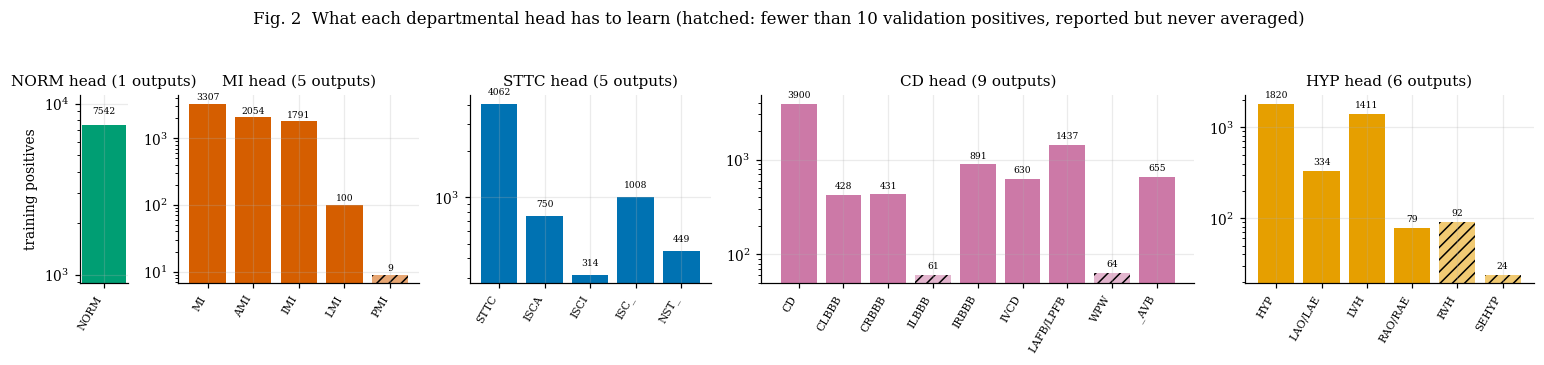

In [7]:
# Fig. 2 label coverage of the five departments (training positives, log scale)
fig, axes = plt.subplots(1, 5, figsize=(14, 3.1), gridspec_kw=dict(width_ratios=[len(HOD_COLS[s]['cols']) for s in SUPER]))
for ax, s in zip(axes, SUPER):
    cols = HOD_COLS[s]['cols']
    ntr, nva = n_pos_tr[cols], Yva[:, cols].sum(0)
    x = np.arange(len(cols))
    bars = ax.bar(x, ntr, color=SUPER_COL[s])
    for b, v in zip(bars, nva):
        if v < CFG['min_pos']:
            b.set_hatch('///'); b.set_alpha(0.55)
    ax.set_yscale('log'); ax.set_xticks(x); ax.set_xticklabels([LABELS[c] for c in cols], rotation=60, ha='right', fontsize=7)
    ax.set_title(f'{s} head ({len(cols)} outputs)')
    for xi, (a, v) in enumerate(zip(ntr, nva)):
        ax.text(xi, a * 1.15, f'{int(a)}', ha='center', fontsize=6)
axes[0].set_ylabel('training positives')
fig.suptitle('Fig. 2  What each departmental head has to learn (hatched: fewer than %d validation positives, reported but never averaged)' % CFG['min_pos'], y=1.05)
fig.tight_layout()
save_fig(fig, 'fig02_head_label_coverage')

## 4. Is the cache trustworthy, and which augmentation is safe?
Two things can silently ruin a distillation run.

**Row alignment.** The cached logits, tokens and embeddings are only useful if row *i* of each belongs to signal *i* here. The teacher is run again on 256 random training records and compared with the cache. This is the only place where DEAN is run in this notebook besides the checks below; during training it is never touched.

**Augmentation consistency.** The cached targets belong to the clean record. If an augmentation changes what the teacher would predict (or how its tokens relate to each other), the student is trained to imitate a target that is wrong for the input it sees. The teacher is run on 512 records under four perturbations: the mild one used here, the mild one plus lead dropout, the mild one plus a time shift of up to 0.5 s, and the NB-02 fine-tuning augmentation. The two quantities are the mean absolute change of the 26 logits and the change of the token Gram matrix.

cache vs fresh teacher pass on 256 records: max |logit diff| 0.0078 (mean 0.00032) | max |token diff| 0.0224 (mean 0.00031)
alignment check passed
                    mean_abs_logit_change  gram_mse
augmentation                                       
mild (used)                        0.0500    0.0004
+ lead dropout                     0.1800    0.0034
+ time shift                       0.3485    0.1311
NB-02 augmentation                 0.3114    0.0702


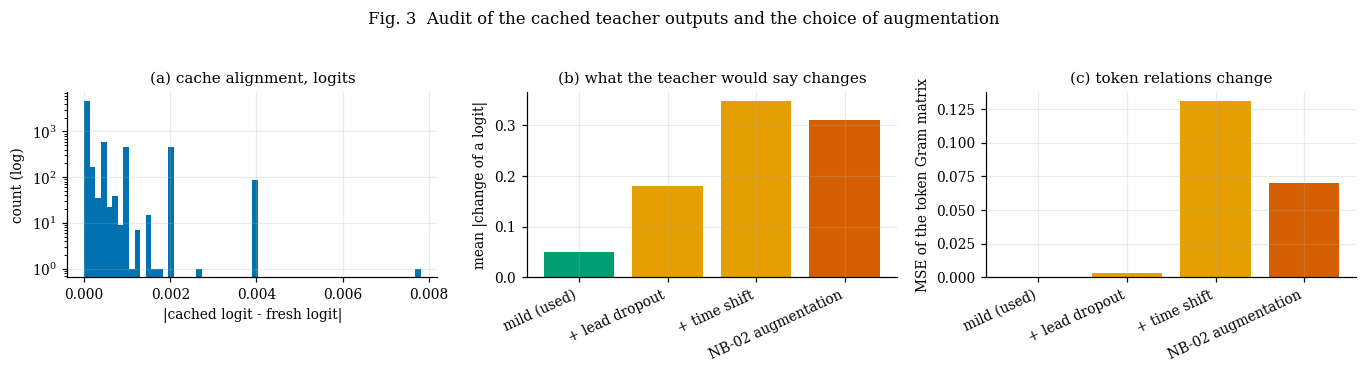

In [8]:
def use_fast_scan():
    dean_lib.selective_scan = hod_lib.fast_scan

@torch.no_grad()
def teacher_pass(x, bs=128):
    lg, tk = [], []
    for i in range(0, len(x), bs):
        with amp():
            o, z, t = teacher.features(x[i:i + bs])
        lg.append(o.float().cpu()); tk.append(t.float().cpu())
    return torch.cat(lg), torch.cat(tk)

use_fast_scan()
rng = np.random.default_rng(0)
pick = np.sort(rng.choice(len(tr_idx), min(256, len(tr_idx)), replace=False))
lg_chk, tk_chk = teacher_pass(DATA['X_tr'][torch.from_numpy(pick).to(dev)])
d_lg = np.abs(lg_chk.numpy() - TL_in[pick])
d_tk = np.abs(tk_chk.numpy() - TK_tr[pick].astype(np.float32))
print(f'cache vs fresh teacher pass on {len(pick)} records: max |logit diff| {d_lg.max():.4f} (mean {d_lg.mean():.5f}) | max |token diff| {d_tk.max():.4f} (mean {d_tk.mean():.5f})')
ALIGN_OK = bool(d_lg.max() < 0.25 and d_tk.mean() < 0.01)
assert ALIGN_OK, 'cached teacher outputs do not match the signals: the record order is wrong'
print('alignment check passed')

sub512 = np.sort(rng.choice(len(tr_idx), min(512, len(tr_idx)), replace=False))
xs = DATA['X_tr'][torch.from_numpy(sub512).to(dev)]
lg0, tk0 = teacher_pass(xs)
def drop_leads(x):
    return x * (torch.rand(x.shape[0], x.shape[1], 1, device=x.device) > 0.1).float()
def shift_time(x):
    s = torch.randint(-50, 51, (x.shape[0],), device=x.device)
    idx = (torch.arange(x.shape[2], device=x.device)[None] - s[:, None]).clamp(0, x.shape[2] - 1)
    return torch.gather(x, 2, idx[:, None, :].expand_as(x))
variants = {
    'mild (used)': lambda x: hod_lib.aug_mild(x),
    '+ lead dropout': lambda x: drop_leads(hod_lib.aug_mild(x)),
    '+ time shift': lambda x: shift_time(hod_lib.aug_mild(x)),
    'NB-02 augmentation': lambda x: hod_lib.aug_strong(x),
}
INV = []
torch.manual_seed(0)
for nm, fn in variants.items():
    lg1, tk1 = teacher_pass(fn(xs))
    INV.append(dict(augmentation=nm, mean_abs_logit_change=float((lg1 - lg0).abs().mean()),
                    gram_mse=float(F.mse_loss(hod_lib.token_gram(tk1), hod_lib.token_gram(tk0)))))
INV = pd.DataFrame(INV).set_index('augmentation')
print(INV.round(4).to_string())
INV.to_csv(os.path.join(TAB_DIR, 'augmentation_consistency.csv'))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.2))
axes[0].hist(d_lg.ravel(), bins=60, color=C_STUDENT, log=True)
axes[0].set_xlabel('|cached logit - fresh logit|'); axes[0].set_ylabel('count (log)'); axes[0].set_title('(a) cache alignment, logits')
axes[1].bar(range(len(INV)), INV.mean_abs_logit_change, color=['#009E73', '#E69F00', '#E69F00', '#D55E00'])
axes[1].set_xticks(range(len(INV))); axes[1].set_xticklabels(INV.index, rotation=25, ha='right'); axes[1].set_ylabel('mean |change of a logit|')
axes[1].set_title('(b) what the teacher would say changes')
axes[2].bar(range(len(INV)), INV.gram_mse, color=['#009E73', '#E69F00', '#E69F00', '#D55E00'])
axes[2].set_xticks(range(len(INV))); axes[2].set_xticklabels(INV.index, rotation=25, ha='right'); axes[2].set_ylabel('MSE of the token Gram matrix')
axes[2].set_title('(c) token relations change')
fig.suptitle('Fig. 3  Audit of the cached teacher outputs and the choice of augmentation', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig03_cache_audit')
del xs, lg0, tk0, lg_chk, tk_chk

## 5. Training function
One function trains every student in this notebook (the five heads, the flat student, the pilot runs and the ablations), so they differ only in their configuration.

Per step: a mildly augmented batch goes through the student; the loss is
`w_sup * BCE + w_kd * KD + w_rkd * GramRKD + w_con * Contrastive`, each term computed only when its weight is above zero. The BCE and KD terms see only the student's own output columns (its superclass and its subclasses), which makes the teacher target dimension-matched by construction. The Gram and contrastive terms use the teacher's tokens and embeddings of the same record.

Every epoch the **EMA copy** is validated (macro-AUC over the head's own labels that have at least `min_pos` validation positives). The best EMA weights are kept and exported. A checkpoint (model, EMA, optimiser, history, best weights) is written every `save_every` epochs, so a stopped session resumes where it was; a run that has finished leaves `hod_<tag>_final.pt` and is skipped on the next execution, unless the configuration that produced it has changed.

In [9]:
SIG_KEYS = ['depth', 'epochs', 'batch_size', 'lr', 'wd', 'warmup_epochs', 'head_drop', 'sub_hidden', 'ema_decay', 'label_smooth',
            'w_sup', 'w_kd', 'w_rkd', 'w_con', 'T', 'tau', 'kd_source', 'aug_strength', 'init', 'sampler', 'enrich', 'seed', 'pos_weight_cap']

def cfg_sig(cfg):
    return json.dumps({k: cfg[k] for k in SIG_KEYS}, sort_keys=True, default=str)

def build_net(cfg, n_sup, n_sub):
    return hod_lib.HODNet(ENC_CFG, cfg['depth'], n_sup, n_sub, D_T, cfg['head_drop'], cfg['sub_hidden']).to(dev)

@torch.no_grad()
def predict_net(net, X, bs=256, tokens=False):
    was = net.training
    net.eval()
    lg, em, tk = [], [], []
    for i in range(0, len(X), bs):
        with amp():
            o, z, t = net(X[i:i + bs], full=True)
        lg.append(o.float().cpu()); em.append(z.float().cpu())
        if tokens:
            tk.append(t.half().cpu())
    net.train(was)
    out = [torch.cat(lg).numpy(), torch.cat(em).numpy()]
    if tokens:
        out.append(torch.cat(tk).numpy())
    return out

def macro_auc_cols(Yc, S, min_pos):
    ok = Yc.sum(0) >= min_pos
    if not ok.any():
        ok = Yc.sum(0) >= 1
    a = auc_per_label(Yc, S, 1)
    return float(np.nanmean(a[ok])) if ok.any() else float('nan')

def run_training(tag, sup_idx, sub_idx, cfg, data, out_dir=None, stop_after=None, quiet=False):
    out_dir = out_dir or HOD_DIR
    os.makedirs(out_dir, exist_ok=True)
    cols = list(sup_idx) + list(sub_idx)
    sig_now = cfg_sig(cfg)

    fin = find_art(f'hod_{tag}_final.pt')
    if fin:
        s = torch.load(fin, map_location='cpu', weights_only=False)
        if s['sig'] == sig_now:
            net = build_net(cfg, len(sup_idx), len(sub_idx))
            net.load_state_dict(s['state'])
            net.eval()
            print(f'[{tag}] already trained (best epoch {s["best_epoch"]}, val AUC {s["best_score"]:.4f}), loaded {fin}')
            return dict(net=net, history=s['history'], best_epoch=s['best_epoch'], best_score=s['best_score'], cols=cols,
                        sup_idx=list(sup_idx), sub_idx=list(sub_idx), finished=True, stopped_early=False, tag=tag, cfg=cfg)
        print(f'[{tag}] a finished run exists but its configuration differs, training again')

    if STRICT_STAGE5_CACHE:
        raise RuntimeError(f'[{tag}] no finished Stage-5 run with this configuration was found. Attach the Stage-5 output that contains hod_{tag}_final.pt, '
                           'or set STRICT_STAGE5_CACHE = False in the configuration cell to train it again (hours).')

    set_seed(cfg['seed'])
    net = build_net(cfg, len(sup_idx), len(sub_idx))
    picks = None
    if cfg['init'] == 'dean_layers':
        picks = hod_lib.init_from_dean(net.enc, teacher.enc)
    prior = data['Y_tr'][:, cols].mean(0).clamp(1e-4, 1 - 1e-4)
    net.set_prior(prior)
    ema = hod_lib.EMA(net, cfg['ema_decay'])
    dec = [p for n, p in net.named_parameters() if not (p.ndim < 2 or 'pos_emb' in n)]
    nod = [p for n, p in net.named_parameters() if (p.ndim < 2 or 'pos_emb' in n)]
    opt = torch.optim.AdamW([{'params': dec, 'weight_decay': cfg['wd']}, {'params': nod, 'weight_decay': 0.0}], lr=cfg['lr'])
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    X, Y = data['X_tr'], data['Y_tr']
    TL = data['TL_oof'] if cfg['kd_source'] == 'oof' else data['TL_in']
    pw = data['POS_W'][cols]
    N, bs = len(X), cfg['batch_size']
    spe = N // bs
    total, warm = cfg['epochs'] * spe, cfg['warmup_epochs'] * spe
    Yv_cols, Tl_va_cols = data['Y_va'][:, cols], data['TL_va'][:, cols]
    w_enrich = (1.0 + cfg['enrich'] * Y[:, sup_idx].max(1).values).cpu()

    start, step, history, best_score, best_epoch, best_state, bad = 0, 0, [], -1.0, 0, None, 0
    ckpt_path = os.path.join(out_dir, f'hod_{tag}_last.pt')
    rs = find_art(f'hod_{tag}_last.pt')
    if rs:
        s = torch.load(rs, map_location='cpu', weights_only=False)
        if s.get('sig') == sig_now:
            net.load_state_dict(s['model']); opt.load_state_dict(s['opt']); scaler.load_state_dict(s['scaler'])
            ema.model.load_state_dict(s['ema']); ema.n = s['ema_n']
            start, step, history = s['epoch'], s['step'], s['history']
            best_score, best_epoch, best_state, bad = s['best_score'], s['best_epoch'], s['best_state'], s['bad']
            print(f'[{tag}] resumed from {rs}: epoch {start}, best epoch {best_epoch} ({best_score:.4f})')
    stopped_early = False
    n_skip = consec = 0
    if USE_AMP: torch.cuda.reset_peak_memory_stats()

    for epoch in range(start, cfg['epochs']):
        net.train()
        t_ep = time.time()
        gen = torch.Generator().manual_seed(cfg['seed'] * 1000 + epoch)
        if cfg['sampler'] == 'enriched':
            order = torch.multinomial(w_enrich, N, replacement=True, generator=gen).to(dev)
        else:
            order = torch.randperm(N, generator=gen).to(dev)
        acc = defaultdict(float)
        bar = tqdm(range(spe), desc=f'[{tag}] epoch {epoch + 1}/{cfg["epochs"]}', leave=False, disable=quiet)
        for i in bar:
            idx = order[i * bs:(i + 1) * bs]
            x = hod_lib.aug_mild(X[idx], cfg['aug_strength']) if cfg['aug_strength'] > 0 else X[idx]
            y_all = Y[idx]
            y = y_all[:, cols]
            sc = hod_lib.cosine_scale(step, total, warm, cfg['lr_floor'])
            for g in opt.param_groups:
                g['lr'] = cfg['lr'] * sc
            with amp():
                logits, z, tok = net(x, full=True)
                zp = net.proj(z) if cfg['w_con'] > 0 else None
            sm = cfg['label_smooth']
            l_sup = F.binary_cross_entropy_with_logits(logits.float(), y * (1 - sm) + 0.5 * sm, pos_weight=pw)
            loss = cfg['w_sup'] * l_sup
            l_kd = l_rkd = l_con = torch.zeros((), device=dev)
            if cfg['w_kd'] > 0:
                l_kd = hod_lib.kd_sigmoid(logits, TL[idx][:, cols], cfg['T'])
                loss = loss + cfg['w_kd'] * l_kd
            if cfg['w_rkd'] > 0:
                l_rkd = hod_lib.gram_loss(tok, data['TK_tr'][idx])
                loss = loss + cfg['w_rkd'] * l_rkd
            if cfg['w_con'] > 0:
                l_con = hod_lib.anchored_supcon(zp, data['ANCH_tr'][idx], y_all[:, :5], cfg['tau'])
                loss = loss + cfg['w_con'] * l_con
            if not torch.isfinite(loss):
                # an occasional fp16 overflow is skipped; a run that keeps producing them has diverged
                n_skip += 1; consec += 1
                if consec > 25:
                    raise RuntimeError(f'[{tag}] {consec} non-finite losses in a row at step {step}: lr {cfg["lr"]:g} is too high')
                opt.zero_grad(set_to_none=True)
                continue
            consec = 0
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), cfg['clip'])
            scaler.step(opt); scaler.update()
            ema.update(net)
            step += 1
            acc['loss'] += float(loss); acc['sup'] += float(l_sup); acc['kd'] += float(l_kd)
            acc['rkd'] += float(l_rkd); acc['con'] += float(l_con)
            if i % 20 == 0:
                bar.set_postfix(loss=f'{acc["loss"] / (i + 1):.3f}')
        bar.close()
        if USE_AMP: torch.cuda.synchronize()
        ep_time = time.time() - t_ep

        Zv = predict_net(ema.model, data['X_va'])[0]
        score = macro_auc_cols(Yv_cols, sigmoid(Zv), cfg['min_pos'])
        score = -1.0 if not np.isfinite(score) else score
        done = epoch + 1
        row = {'epoch': done, 'step': step, 'lr': cfg['lr'] * sc, 'sec_per_epoch': ep_time, 'sec_per_step': ep_time / max(spe, 1),
               'gpu_peak_gb': torch.cuda.max_memory_allocated() / 1e9 if USE_AMP else 0.0,
               'val_macro_auc': score, 'val_logit_mae': float(np.abs(Zv - Tl_va_cols).mean())}
        row.update({k: v / max(spe, 1) for k, v in acc.items()})
        row['skipped'] = n_skip
        history.append(row)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, done, 0
            best_state = {k: v.detach().cpu().clone() for k, v in ema.model.state_dict().items()}
        else:
            bad += 1
        remaining = hours_left(cfg['max_hours'])
        stop_now = bool(cfg['max_hours']) and done < cfg['epochs'] and 1.5 * ep_time / 3600 > remaining
        cut = stop_after is not None and done >= stop_after
        if done % cfg['save_every'] == 0 or done == cfg['epochs'] or stop_now or bad >= cfg['patience'] or cut:
            torch.save({'model': net.state_dict(), 'ema': ema.model.state_dict(), 'ema_n': ema.n, 'opt': opt.state_dict(),
                        'scaler': scaler.state_dict(), 'epoch': done, 'step': step, 'history': history, 'best_score': best_score,
                        'best_epoch': best_epoch, 'best_state': best_state, 'bad': bad, 'sig': sig_now}, ckpt_path + '.tmp')
            os.replace(ckpt_path + '.tmp', ckpt_path)
        if not quiet:
            print(f"[{tag}] ep {done:2d} | loss {row['loss']:.4f} (sup {row['sup']:.3f} kd {row['kd']:.4f} rkd {row['rkd']:.4f} con {row['con']:.3f}) | "
                  f"val AUC {score:.4f} | logit MAE {row['val_logit_mae']:.3f} | {ep_time:5.0f}s{f' | skipped {n_skip}' if n_skip else ''}{' | best' if improved else ''}")
        if bad >= cfg['patience']:
            print(f'[{tag}] no improvement for {cfg["patience"]} epochs, stopping at epoch {done}')
            break
        if stop_now:
            stopped_early = True
            print(f'[{tag}] time budget reached after epoch {done}. State saved, publish the output as a Dataset and re-run to resume.')
            break
        if cut:
            stopped_early = True
            break

    if stopped_early:
        return dict(net=net, history=history, best_epoch=best_epoch, best_score=best_score, cols=cols, sup_idx=list(sup_idx),
                    sub_idx=list(sub_idx), finished=False, stopped_early=True, tag=tag, cfg=cfg)
    net.load_state_dict(best_state)
    net.eval()
    final = os.path.join(out_dir, f'hod_{tag}_final.pt')
    torch.save({'state': net.state_dict(), 'deploy': net.deploy_state(), 'history': history, 'best_epoch': best_epoch,
                'best_score': best_score, 'cols': cols, 'sup_idx': list(sup_idx), 'sub_idx': list(sub_idx), 'labels': [LABELS[c] for c in cols],
                'student_enc_cfg': dict(ENC_CFG, depth=cfg['depth'], grad_ckpt=False),
                'sig': sig_now, 'cfg': {k: cfg[k] for k in SIG_KEYS}, 'init_picks': picks}, final + '.tmp')
    os.replace(final + '.tmp', final)
    return dict(net=net, history=history, best_epoch=best_epoch, best_score=best_score, cols=cols, sup_idx=list(sup_idx),
                sub_idx=list(sub_idx), finished=True, stopped_early=False, tag=tag, cfg=cfg)

## 6. Smoke test
The Stage-5 smoke test is not repeated here: this notebook only reloads the finished heads. Stage 6 has its own smoke test (section 18) that runs before any Professor is trained.

In [10]:
SMOKE, SMOKE_OK = None, True
use_fast_scan()
print('Stage-5 smoke test skipped (the heads are reloaded, not trained)')

Stage-5 smoke test skipped (the heads are reloaded, not trained)


## 7. Learning-rate search, one value per head
The plan fixes 1e-4, but that value was chosen for fine-tuning a pre-trained encoder, and these students start from random weights. The first run showed two things: the best rate differs between heads, and a rate that wins a 6-epoch pilot on one head (1e-3 on CD) can diverge on another (MI). So every head is searched on its own.

For each head the pilot trains the head for `pilot_epochs` epochs at each value of `pilot_lrs` (1e-4, 3e-4, 5e-4) and records the validation macro-AUC of its own labels.

**Decision rule, fixed before looking at any result:**
1. A value is eligible only if its run finished, did not diverge, and skipped **no** non-finite batch (`lr <= lr_cap` as well).
2. Among the eligible values, take the best validation macro-AUC; if a lower value is within 0.001 of it, take the lower one. A 6-epoch cosine schedule favours large rates, so ties go to the safer value.
3. If nothing is eligible the head falls back to the smallest value of the grid.

The result is written to `hod_lr_search.json`. If that file is found (in the working directory or in an attached Dataset) and was made with the same grid, the search is skipped, so the choice is made once and kept. The pilot runs and the final heads are cached by the training function, so re-running costs nothing for runs that already finished.

The search uses the validation fold the heads are selected on, which is a legitimate hyper-parameter choice; fold 10 stays untouched.

learning-rate search found in /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hod_lr_search.json and reused
family     lr  val_macro_auc  best_epoch  last_auc  final_kd  final_sup  skipped  diverged  finished  chosen
    CD 0.0001         0.9204           6    0.9204    0.0705     0.7799        0     False      True   False
    CD 0.0003         0.9352           6    0.9352    0.0639     0.6823        0     False      True   False
    CD 0.0005         0.9371           6    0.9371    0.0658     0.6577        0     False      True    True
    MI 0.0001         0.8996           6    0.8996    0.0695     0.7608        0     False      True   False
    MI 0.0003         0.9252           6    0.9252    0.0722     0.6544        0     False      True   False
    MI 0.0005         0.9263           5    0.9241    0.0745     0.6321        0     False      True    True
  STTC 0.0001         0.9250           5    0.9243    0.0584     0.7452        0     False      True   F

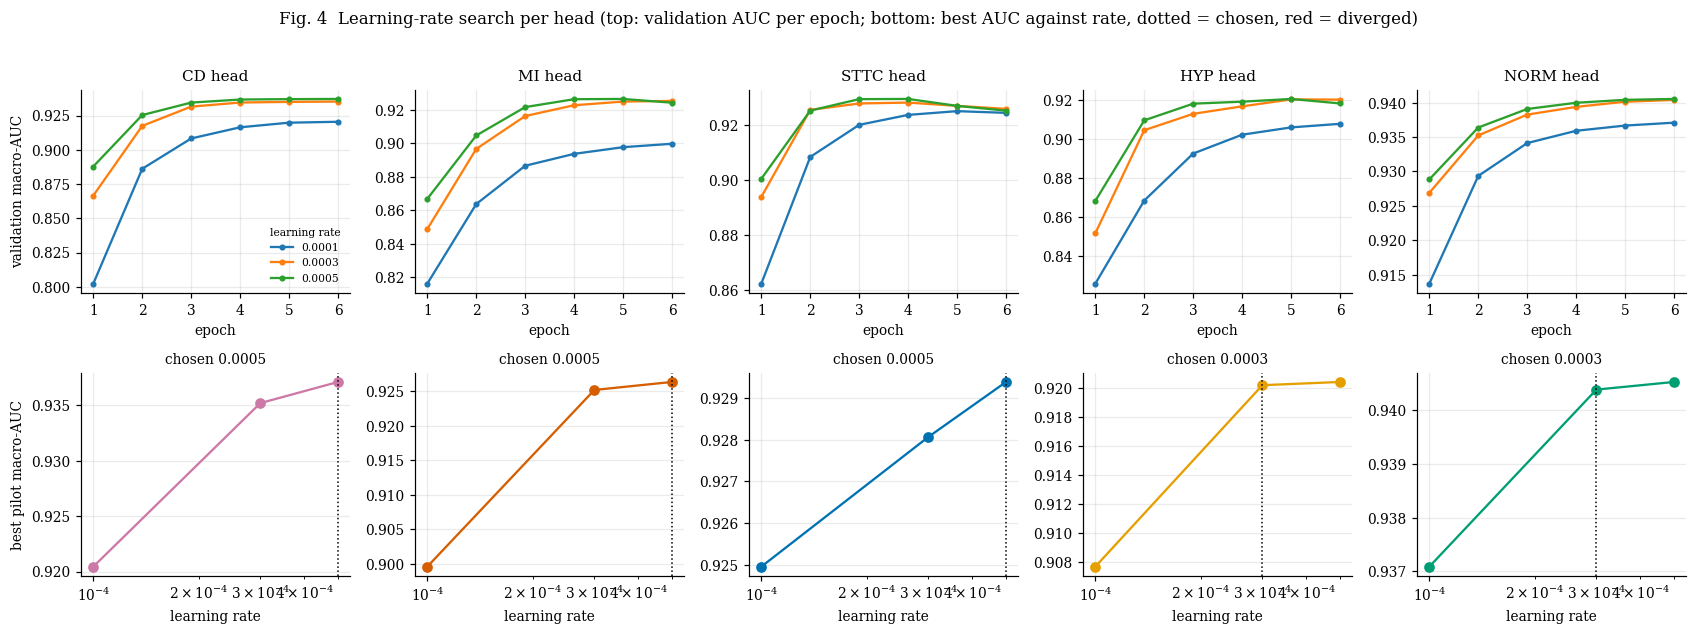

In [11]:
assert SMOKE_OK, 'run the smoke test first'
TIME_UP = False
PILOT, HEAD_LR, HIST = None, {}, {}
GRID = list(CFG['pilot_lrs'])
SEARCH_SIG = json.dumps(dict(grid=GRID, epochs=CFG['pilot_epochs'], cap=CFG['lr_cap'], margin=CFG['pilot_margin'], heads=CFG['hods'],
                             kd=CFG['kd_source'], seed=CFG['seed'], batch=CFG['batch_size']), sort_keys=True)

def pick_lr(d, grid, cap, margin):
    ok = d[(~d.diverged) & d.finished & (d.skipped == 0) & (d.lr <= cap + 1e-12)]
    if ok.empty:
        return float(min(grid)), 'no eligible value, smallest of the grid'
    top = ok.val_macro_auc.max()
    near = ok[ok.val_macro_auc >= top - margin / 2]
    return float(near.lr.min()), 'best eligible' if float(near.lr.min()) == float(ok.loc[ok.val_macro_auc.idxmax(), 'lr']) else 'lower rate within 0.001 of the best'

prev = find_art('hod_lr_search.json')
if prev is not None:
    s = json.load(open(prev))
    if s.get('sig') == SEARCH_SIG:
        HEAD_LR, PILOT, HIST = s['head_lr'], pd.DataFrame(s['table']), s.get('histories', {})
        print(f'learning-rate search found in {prev} and reused')

if not HEAD_LR and CFG['run_lr_pilot']:
    rows = []
    for name in CFG['hods']:
        for lr in GRID:
            if TIME_UP:
                break
            c = dict(CFG); c.update(lr=lr, epochs=CFG['pilot_epochs'], warmup_epochs=1, patience=99)
            tag = f'pilot_lr{lr:g}' if name == 'CD' else f'pilot_{name}_lr{lr:g}'     # the CD tags are those of the first run, so its cached runs are reused
            try:
                r = run_training(tag, HOD_COLS[name]['sup'], HOD_COLS[name]['sub'], c, DATA)
            except RuntimeError as err:
                print(f'[{name}] lr {lr:g} diverged: {err}')
                rows.append(dict(family=name, lr=lr, val_macro_auc=np.nan, best_epoch=0, last_auc=np.nan, final_kd=np.nan, final_sup=np.nan,
                                 skipped=-1, diverged=True, finished=False))
                torch.cuda.empty_cache()
                continue
            TIME_UP = r['stopped_early']
            h = pd.DataFrame(r['history'])
            if 'skipped' not in h:
                h['skipped'] = 0
            HIST[f'{name}|{lr:g}'] = h[['epoch', 'val_macro_auc']].to_dict(orient='list')
            rows.append(dict(family=name, lr=lr, val_macro_auc=r['best_score'], best_epoch=r['best_epoch'], last_auc=float(h.val_macro_auc.iloc[-1]),
                             final_kd=float(h.kd.iloc[-1]), final_sup=float(h.sup.iloc[-1]), skipped=int(h.skipped.iloc[-1]), diverged=False, finished=bool(r['finished'])))
            torch.cuda.empty_cache()
    PILOT = pd.DataFrame(rows)
    why = {}
    for name in CFG['hods']:
        d = PILOT[PILOT.family == name]
        if len(d) < len(GRID):
            continue                                   # search interrupted for this head
        HEAD_LR[name], why[name] = pick_lr(d, GRID, CFG['lr_cap'], CFG['pilot_margin'])
    if len(HEAD_LR) == len(CFG['hods']):
        json.dump(dict(sig=SEARCH_SIG, grid=GRID, cap=CFG['lr_cap'], head_lr=HEAD_LR, why=why, table=PILOT.to_dict(orient='list'), histories=HIST),
                  open(os.path.join(WORK, 'hod_lr_search.json'), 'w'), indent=1, default=float)
    PILOT.to_csv(os.path.join(TAB_DIR, 'lr_pilot_per_head.csv'), index=False)

if not CFG['run_lr_pilot']:
    HEAD_LR = {n: CFG['lr'] for n in CFG['hods']}
    print('learning-rate search skipped, every head uses', CFG['lr'])
assert len(HEAD_LR) == len(CFG['hods']), 'the search is incomplete (time budget): publish the output as a Dataset, attach it and run again'

def head_cfg(name):
    return dict(CFG, lr=HEAD_LR[name])

FLAT_LR = float(np.median([HEAD_LR[n] for n in CFG['hods']]))      # the flat student has no family of its own: it gets the median of the five
if PILOT is not None:
    show = PILOT.copy(); show['chosen'] = [bool(HEAD_LR[f] == l) for f, l in zip(show.family, show.lr)]
    print(show.round(4).to_string(index=False))
print('\nlearning rate per head:', {n: f'{v:g}' for n, v in HEAD_LR.items()}, '| flat student', f'{FLAT_LR:g}')

if PILOT is not None and HIST:
    fig, axes = plt.subplots(2, len(CFG['hods']), figsize=(3.1 * len(CFG['hods']), 5.6), squeeze=False)
    for k, n in enumerate(CFG['hods']):
        ax = axes[0, k]
        for lr in GRID:
            h = HIST.get(f'{n}|{lr:g}')
            if h:
                ax.plot(h['epoch'], h['val_macro_auc'], 'o-', ms=3, label=f'{lr:g}')
        ax.set_title(f'{n} head'); ax.set_xlabel('epoch'); ax.set_ylabel('validation macro-AUC' if k == 0 else '')
        if k == 0: ax.legend(fontsize=7, title='learning rate', title_fontsize=7)
        ax = axes[1, k]
        d = PILOT[PILOT.family == n]
        okd = d[~d.diverged]
        ax.semilogx(okd.lr, okd.val_macro_auc, 'o-', color=SUPER_COL[n])
        for _, rw in d[d.diverged].iterrows():
            ax.axvline(rw.lr, color='r', ls='--', lw=0.8)
        ax.axvline(HEAD_LR[n], color='k', ls=':', lw=1)
        ax.set_xlabel('learning rate'); ax.set_ylabel('best pilot macro-AUC' if k == 0 else ''); ax.set_title(f'chosen {HEAD_LR[n]:g}', fontsize=9)
    fig.suptitle('Fig. 4  Learning-rate search per head (top: validation AUC per epoch; bottom: best AUC against rate, dotted = chosen, red = diverged)', y=1.02)
    fig.tight_layout()
    save_fig(fig, 'fig04_lr_search_per_head')


## 8. The five departmental heads
Trained one after the other, always in the same function, each with the learning rate it won in section 7. The heads share nothing but the teacher cache. A finished head is skipped when the notebook is re-run, and an interrupted one resumes from its checkpoint. If the time budget (`max_hours`) runs out, the last lines say which heads are missing; publish the output as a Dataset, attach it to a new session and run again.

In [12]:
RES = {}
for name in CFG['hods']:
    if TIME_UP:
        break
    assert HEAD_LR[name] <= CFG['lr_cap'] + 1e-12, f"{name}: lr {HEAD_LR[name]:g} is above the safe cap {CFG['lr_cap']:g}"
    r = run_training(f'{name}', HOD_COLS[name]['sup'], HOD_COLS[name]['sub'], head_cfg(name), DATA)
    RES[name] = r
    TIME_UP = r['stopped_early']
    torch.cuda.empty_cache()
ALL_HODS = all(n in RES and RES[n]['finished'] for n in CFG['hods'])
print()
for n in CFG['hods']:
    if n in RES:
        r = RES[n]
        print(f"{n:5s} lr {HEAD_LR[n]:g} | outputs {len(r['cols']):2d} | best epoch {r['best_epoch']:2d}/{len(r['history'])} | validation macro-AUC {r['best_score']:.4f} | {'finished' if r['finished'] else 'PAUSED'}")
    else:
        print(f'{n:5s} not started')
if ALL_HODS:
    BEST = {n: dict(lr=HEAD_LR[n], best_epoch=int(RES[n]['best_epoch']), epochs_run=len(RES[n]['history']), val_macro_auc=float(RES[n]['best_score']),
                    labels=[LABELS[c] for c in RES[n]['cols']]) for n in CFG['hods']}
    json.dump(BEST, open(os.path.join(WORK, 'hod_best_per_head.json'), 'w'), indent=1)
assert ALL_HODS, 'training paused: publish the output as a Dataset, attach it to a new session and run all cells again'


[CD] already trained (best epoch 6, val AUC 0.9375), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_CD_final.pt
[MI] already trained (best epoch 6, val AUC 0.9289), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_MI_final.pt
[STTC] already trained (best epoch 4, val AUC 0.9297), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_STTC_final.pt
[HYP] already trained (best epoch 6, val AUC 0.9229), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_HYP_final.pt
[NORM] already trained (best epoch 10, val AUC 0.9400), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_NORM_final.pt

CD    lr 0.0005 | outputs  9 | best epoch  6/14 | validation macro-AUC 0.9375 | finished
MI    lr 0.0005 | outputs  5 | best epoch  6/14 | validation macro-AUC 0.9289 | finished
STTC  lr 0.0005 | outputs  5 | best epoc

## 9. Flat student (control)
The same student, trained with the same recipe, but on **all 26 labels at once** instead of one department. It answers the question a reviewer will ask first: is a department specialist better than a generalist of the same size? Its superclass output has five units and its subclass branch 21.

In [13]:
FLAT = None
if CFG['run_flat'] and not TIME_UP:
    FLAT = run_training('FLAT', list(range(5)), list(range(5, 26)), dict(CFG, lr=FLAT_LR), DATA)
    TIME_UP = TIME_UP or FLAT['stopped_early']
    torch.cuda.empty_cache()
    if not FLAT['finished']:
        FLAT = None
        print('flat student paused, re-run to resume. The rest of the notebook continues without it.')
print('flat student:', 'done' if FLAT is not None else 'not available')

[FLAT] already trained (best epoch 39, val AUC 0.9257), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_FLAT_final.pt
flat student: done


## 10. Predictions and the evaluation protocol
Every head is run once on the training and the validation records (EMA weights, no augmentation). The five heads together form a **committee**: each head supplies the columns it owns, and the 26 columns are put back in the teacher's order, so the committee can be compared with DEAN label by label.

Protocol, identical for the teacher and the students:
* **AUC** is computed on fold 9 only for labels with at least `min_pos` validation positives; rarer labels are listed but never averaged (the same rule as NB-02).
* **Calibration** is a Platt fit per label on fold 9 (the recipe of `eval_lib.fit_calibration`), fitted separately for teacher and student on exactly the columns being compared. It is monotone, so AUC does not change. Calibration error is the *cross-fitted* ECE: fitted on one half of fold 9, scored on the other.
* **F1** uses one threshold per label tuned on fold 9, so it is optimistic for both models; the honest numbers come from NB-09 on fold 10.
* **Intervals** are 95 % percentile bootstrap over records; the difference between a student and the teacher is a *paired* bootstrap (the same resampled records for both).

In [14]:
MP, NB = CFG['min_pos'], CFG['n_boot']

def deploy_params(net):
    return dean_lib.count_params(net) - dean_lib.count_params(net.proj)

PRED = {}
for n in CFG['hods']:
    lv, ev, tv = predict_net(RES[n]['net'], DATA['X_va'], tokens=True)
    lt, et = predict_net(RES[n]['net'], DATA['X_tr'])
    PRED[n] = dict(lg_va=lv, em_va=ev, tk_va=tv, lg_tr=lt, em_tr=et)
COM_va = np.zeros((len(va_idx), len(LABELS)), dtype=np.float32)
COM_tr = np.zeros((len(tr_idx), len(LABELS)), dtype=np.float32)
for n in CFG['hods']:
    COM_va[:, RES[n]['cols']] = PRED[n]['lg_va']
    COM_tr[:, RES[n]['cols']] = PRED[n]['lg_tr']
PFLAT = None
if FLAT is not None:
    lv, ev, tv = predict_net(FLAT['net'], DATA['X_va'], tokens=True)
    lt, et = predict_net(FLAT['net'], DATA['X_tr'])
    PFLAT = dict(lg_va=lv, em_va=ev, tk_va=tv, lg_tr=lt, em_tr=et)

PARAMS = {n: deploy_params(RES[n]['net']) for n in CFG['hods']}
if FLAT is not None:
    PARAMS['FLAT'] = deploy_params(FLAT['net'])
T_PARAMS = sum(p.numel() for p in teacher.enc.parameters()) + sum(p.numel() for p in teacher.head.parameters())   # the teacher is frozen: count_params would report 0
print('parameters (deployable part):', {k: f'{v / 1e6:.2f} M' for k, v in PARAMS.items()}, '| teacher', f'{T_PARAMS / 1e6:.2f} M')

def eval_block(cols, Zs, Zd, n_super, seed=0):
    Yc = Yva[:, cols]
    a, b = fit_calibration(Zs, Yc, MP)
    ad, bd = fit_calibration(Zd, Yc, MP)
    S, Sd = sigmoid(Zs * a + b), sigmoid(Zd * ad + bd)
    thr, f1 = tune_thresholds(Yc, S)
    thr_d, f1_d = tune_thresholds(Yc, Sd)
    raw, cal = crossfit_ece(Zs, Yc, MP)
    return dict(cols=cols, a=a, b=b, S=S, Sd=Sd, thr=thr, thr_d=thr_d, f1=f1, f1_d=f1_d,
                boot=bootstrap(Yc, S, thr, MP, NB, seed=seed, n_super=n_super),
                boot_d=bootstrap(Yc, Sd, thr_d, MP, NB, seed=seed, n_super=n_super),
                delta=paired_delta(Yc, S, Sd, MP, NB, seed=seed), ece_raw=raw, ece_cal=cal)

EV = {n: eval_block(RES[n]['cols'], PRED[n]['lg_va'], TL_va[:, RES[n]['cols']], len(RES[n]['sup_idx'])) for n in CFG['hods']}
EV['COMMITTEE'] = eval_block(list(range(len(LABELS))), COM_va, TL_va, 5)
EVF = eval_block(list(range(len(LABELS))), PFLAT['lg_va'], TL_va, 5) if PFLAT is not None else None

def fmt(ci, d=3):
    return f'{ci[0]:.{d}f} [{ci[1]:.{d}f}, {ci[2]:.{d}f}]'

rows = []
for n in CFG['hods'] + ['COMMITTEE']:
    e = EV[n]
    ok = Yva[:, e['cols']].sum(0) >= MP
    rows.append({'model': n, 'outputs': len(e['cols']), 'params (M)': (PARAMS[n] if n in PARAMS else sum(PARAMS[k] for k in CFG['hods'])) / 1e6,
                 'best epoch': RES[n]['best_epoch'] if n in RES else np.nan,
                 'student macro-AUC': fmt(e['boot']['macro_auc']), 'teacher macro-AUC': fmt(e['boot_d']['macro_auc']),
                 'paired diff (student - teacher)': fmt(e['delta'], 4),
                 'student macro-F1': f"{e['boot']['macro_f1'][0]:.3f}", 'teacher macro-F1': f"{e['boot_d']['macro_f1'][0]:.3f}",
                 'ECE raw': float(np.nanmean(e['ece_raw'])), 'ECE Platt': float(np.nanmean(e['ece_cal']))})
TAB_MAIN = pd.DataFrame(rows).set_index('model')
print(TAB_MAIN.round(4).to_string())
TAB_MAIN.to_csv(os.path.join(TAB_DIR, 'table_main_heads_vs_teacher.csv'))

parameters (deployable part): {'CD': '4.71 M', 'MI': '4.71 M', 'STTC': '4.71 M', 'HYP': '4.71 M', 'NORM': '4.65 M', 'FLAT': '4.72 M'} | teacher 11.49 M
           outputs  params (M)  best epoch     student macro-AUC     teacher macro-AUC paired diff (student - teacher) student macro-F1 teacher macro-F1  ECE raw  ECE Platt
model                                                                                                                                                                       
CD               9      4.7137         6.0  0.938 [0.927, 0.948]  0.936 [0.927, 0.948]        0.0013 [-0.0056, 0.0079]            0.650            0.654   0.1510     0.0079
MI               5      4.7127         6.0  0.929 [0.914, 0.944]  0.920 [0.904, 0.936]        0.0097 [-0.0008, 0.0222]            0.534            0.518   0.1541     0.0128
STTC             5      4.7127         4.0  0.930 [0.918, 0.941]  0.932 [0.919, 0.943]       -0.0016 [-0.0076, 0.0045]            0.500            0.520   0

In [15]:
# per-label table: student against teacher, committee columns
e = EV['COMMITTEE']
pl_s = per_label_table(LABELS, Yva, e['S'], e['thr'], MP)
pl_t = per_label_table(LABELS, Yva, e['Sd'], e['thr_d'], MP)
PL = pd.DataFrame({'label': LABELS, 'family': [l if l in SUPER else FAMILY[l] for l in LABELS], 'n_pos_val': pl_s.n_pos, 'reliable': pl_s.reliable,
                   'auc_student': pl_s.auc, 'auc_lo': e['boot']['label_auc_lo'], 'auc_hi': e['boot']['label_auc_hi'],
                   'auc_teacher': pl_t.auc, 'teacher_lo': e['boot_d']['label_auc_lo'], 'teacher_hi': e['boot_d']['label_auc_hi'],
                   'ap_student': pl_s.ap, 'ap_teacher': pl_t.ap, 'f1_student': pl_s.f1, 'f1_teacher': pl_t.f1,
                   'thr_student': pl_s.threshold})
PL['delta_auc'] = PL.auc_student - PL.auc_teacher
print(PL.drop(columns=['teacher_lo', 'teacher_hi', 'thr_student']).round(3).to_string(index=False))
PL.to_csv(os.path.join(TAB_DIR, 'table_per_label.csv'), index=False)

# how closely does each head follow the teacher? logits per label, and the token relations
from scipy.stats import spearmanr
def gram_stats(tk_s, tk_t, chunk=256):
    se, n, xs, ys = 0.0, 0, [], []
    for i in range(0, len(tk_s), chunk):
        gs = hod_lib.token_gram(torch.from_numpy(tk_s[i:i + chunk].astype(np.float32)))
        gt = hod_lib.token_gram(torch.from_numpy(tk_t[i:i + chunk].astype(np.float32)))
        se += float(((gs - gt) ** 2).sum()); n += gs.numel()
        xs.append(gs.reshape(-1)[::7].numpy()); ys.append(gt.reshape(-1)[::7].numpy())
    xs, ys = np.concatenate(xs), np.concatenate(ys)
    return se / n, float(np.corrcoef(xs, ys)[0, 1])

FID = []
for n in CFG['hods']:
    cols = RES[n]['cols']
    sp = [spearmanr(PRED[n]['lg_va'][:, k], TL_va[:, c])[0] for k, c in enumerate(cols)]
    g_mse, g_r = gram_stats(PRED[n]['tk_va'], TK_va)
    FID.append(dict(head=n, logit_spearman_mean=float(np.mean(sp)), logit_spearman_min=float(np.min(sp)),
                    logit_mae=float(np.abs(PRED[n]['lg_va'] - TL_va[:, cols]).mean()), gram_mse=g_mse, gram_corr=g_r))
FID = pd.DataFrame(FID).set_index('head')
print(FID.round(4).to_string())
FID.to_csv(os.path.join(TAB_DIR, 'table_teacher_fidelity.csv'))

    label family  n_pos_val  reliable  auc_student  auc_lo  auc_hi  auc_teacher  ap_student  ap_teacher  f1_student  f1_teacher  delta_auc
     NORM   NORM        942      True        0.940   0.930   0.949        0.940       0.916       0.915       0.845       0.853     -0.000
       MI     MI        412      True        0.930   0.916   0.942        0.929       0.777       0.774       0.724       0.706      0.001
     STTC   STTC        510      True        0.932   0.921   0.943        0.930       0.791       0.790       0.743       0.746      0.003
       CD     CD        495      True        0.919   0.903   0.933        0.912       0.839       0.826       0.768       0.757      0.007
      HYP    HYP        216      True        0.909   0.889   0.930        0.910       0.632       0.632       0.607       0.600     -0.001
      AMI     MI        258      True        0.944   0.931   0.957        0.941       0.729       0.721       0.678       0.663      0.003
      IMI     MI        227

## 11. Is the specialist better than a generalist?
The flat student has the same architecture and recipe but sees all 26 labels. Per family: macro-AUC of the department head, of the flat student and of the teacher on the same columns, and the paired differences. This is the experiment that tells you whether the *hierarchy* contributes anything at this tier, as opposed to distillation in general.

In [16]:
FAMCMP = None
if EVF is not None:
    rows = []
    for n in CFG['hods']:
        cols = RES[n]['cols']
        Yc = Yva[:, cols]
        S_h, S_f, S_t = EV[n]['S'], EVF['S'][:, cols], EV[n]['Sd']
        a_h, a_f, a_t = [macro_auc_cols(Yc, S, MP) for S in (S_h, S_f, S_t)]
        rows.append({'family': n, 'head': a_h, 'flat student': a_f, 'teacher': a_t,
                     'head - flat': fmt(paired_delta(Yc, S_h, S_f, MP, NB), 4), 'head - teacher': fmt(EV[n]['delta'], 4),
                     'flat - teacher': fmt(paired_delta(Yc, S_f, S_t, MP, NB), 4)})
    d_all = paired_delta(Yva, EV['COMMITTEE']['S'], EVF['S'], MP, NB)
    rows.append({'family': 'all 26 labels', 'head': macro_auc_cols(Yva, EV['COMMITTEE']['S'], MP), 'flat student': macro_auc_cols(Yva, EVF['S'], MP),
                 'teacher': macro_auc_cols(Yva, EV['COMMITTEE']['Sd'], MP), 'head - flat': fmt(d_all, 4),
                 'head - teacher': fmt(EV['COMMITTEE']['delta'], 4),
                 'flat - teacher': fmt(paired_delta(Yva, EVF['S'], EV['COMMITTEE']['Sd'], MP, NB), 4)})
    FAMCMP = pd.DataFrame(rows).set_index('family')
    print(FAMCMP.round(4).to_string())
    print(f'\nparameters: each head {np.mean([PARAMS[n] for n in CFG["hods"]]) / 1e6:.2f} M, flat student {PARAMS["FLAT"] / 1e6:.2f} M, teacher {T_PARAMS / 1e6:.2f} M; the five heads together hold {sum(PARAMS[n] for n in CFG["hods"]) / 1e6:.1f} M')
    FAMCMP.to_csv(os.path.join(TAB_DIR, 'table_family_head_vs_flat.csv'))
else:
    print('no flat student, skipped')

                 head  flat student  teacher               head - flat             head - teacher             flat - teacher
family                                                                                                                      
CD             0.9375        0.9334   0.9362  0.0043 [-0.0009, 0.0100]   0.0013 [-0.0056, 0.0079]  -0.0029 [-0.0099, 0.0050]
MI             0.9289        0.9199   0.9195   0.0091 [0.0008, 0.0172]   0.0097 [-0.0008, 0.0222]   0.0006 [-0.0113, 0.0152]
STTC           0.9297        0.9293   0.9314  0.0002 [-0.0046, 0.0044]  -0.0016 [-0.0076, 0.0045]  -0.0018 [-0.0078, 0.0049]
HYP            0.9229        0.9103   0.9164   0.0131 [0.0030, 0.0266]   0.0065 [-0.0056, 0.0184]  -0.0066 [-0.0173, 0.0026]
NORM           0.9400        0.9395   0.9403  0.0005 [-0.0024, 0.0036]  -0.0004 [-0.0039, 0.0030]  -0.0009 [-0.0042, 0.0029]
all 26 labels  0.9313        0.9257   0.9283   0.0057 [0.0023, 0.0090]   0.0031 [-0.0009, 0.0079]  -0.0026 [-0.0068, 0.0015]


## 12. Figures
Figure numbers are local to this notebook. Colours follow the family palette used since NB-02; the teacher is dark grey and drawn dashed or hollow wherever it shares a panel with a student.

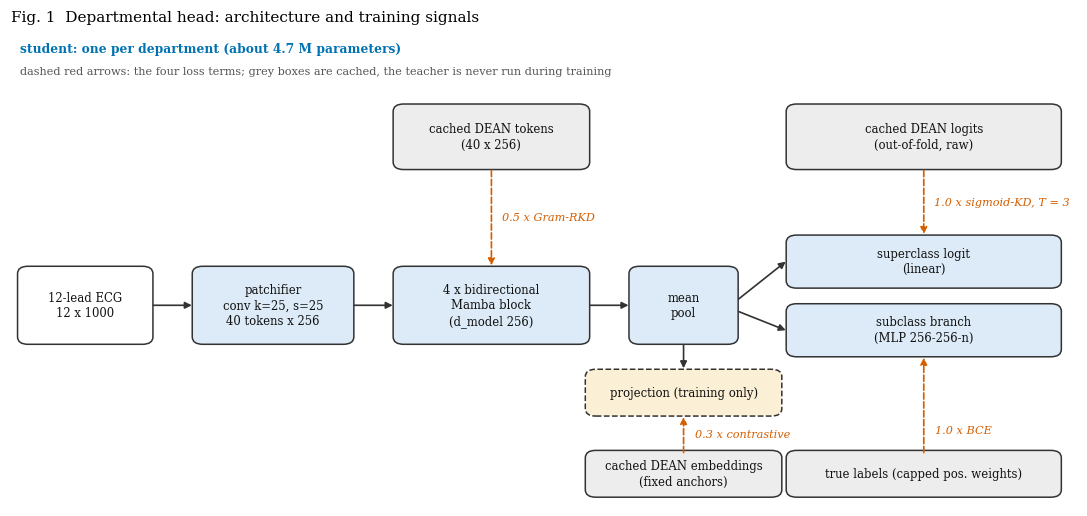

In [17]:
# Fig. 1  the departmental head and what trains it
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12.5, 5.6))
ax.set_xlim(0, 122); ax.set_ylim(-14, 62); ax.axis('off')
def box(x, y, w, h, text, fc, ec='#333', fs=7.6, ls='-', tc='#111'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.25,rounding_size=1.2', fc=fc, ec=ec, lw=1.0, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, color=tc, linespacing=1.25)
def arrow(p, q, ls='-', col='#333', lab=None, lab_dx=1.2, lab_dy=0.0, lw=1.1):
    ax.annotate('', xy=q, xytext=p, arrowprops=dict(arrowstyle='-|>', color=col, lw=lw, ls=ls, shrinkA=0, shrinkB=0))
    if lab:
        ax.text((p[0] + q[0]) / 2 + lab_dx, (p[1] + q[1]) / 2 + lab_dy, lab, fontsize=7.4, color=col, ha='left', va='center', style='italic')
S_FC, T_FC, X_FC = '#DCEBF7', '#EDEDED', '#FBEFD5'
box(1, 12, 15, 12, '12-lead ECG\n12 x 1000', '#FFFFFF')
box(21, 12, 18, 12, 'patchifier\nconv k=25, s=25\n40 tokens x 256', S_FC)
box(44, 12, 22, 12, f'{CFG["depth"]} x bidirectional\nMamba block\n(d_model 256)', S_FC)
box(71, 12, 12, 12, 'mean\npool', S_FC)
box(89, 21, 31, 8, 'superclass logit\n(linear)', S_FC)
box(89, 10, 31, 8, 'subclass branch\n(MLP 256-256-n)', S_FC)
box(66, 0.5, 22, 7, 'projection (training only)', X_FC, ls='--')
arrow((16.3, 18), (20.7, 18)); arrow((39.3, 18), (43.7, 18)); arrow((66.3, 18), (70.7, 18))
arrow((83.3, 19), (88.7, 25)); arrow((83.3, 17), (88.7, 14))
arrow((77, 11.6), (77, 7.9))
box(44, 40, 22, 10, 'cached DEAN tokens\n(40 x 256)', T_FC)
box(89, 40, 31, 10, 'cached DEAN logits\n(out-of-fold, raw)', T_FC)
box(66, -12.5, 22, 7, 'cached DEAN embeddings\n(fixed anchors)', T_FC)
box(89, -12.5, 31, 7, 'true labels (capped pos. weights)', T_FC)
arrow((55, 39.6), (55, 24.4), '--', '#D55E00', '0.5 x Gram-RKD')
arrow((104.5, 39.6), (104.5, 29.4), '--', '#D55E00', '1.0 x sigmoid-KD, T = 3')
arrow((77, -5.6), (77, 0.1), '--', '#D55E00', '0.3 x contrastive', lab_dx=1.3)
arrow((104.5, -5.6), (104.5, 9.6), '--', '#D55E00', '1.0 x BCE', lab_dx=1.3, lab_dy=-4.0)
ax.text(1, 58.5, f'student: one per department (about {np.mean([PARAMS[n] for n in CFG["hods"]]) / 1e6:.1f} M parameters)', fontsize=8, color='#0072B2', weight='bold')
ax.text(1, 55.0, 'dashed red arrows: the four loss terms; grey boxes are cached, the teacher is never run during training', fontsize=7.4, color='#555')
ax.set_title('Fig. 1  Departmental head: architecture and training signals', loc='left', y=1.0)
save_fig(fig, 'fig01_hod_architecture')

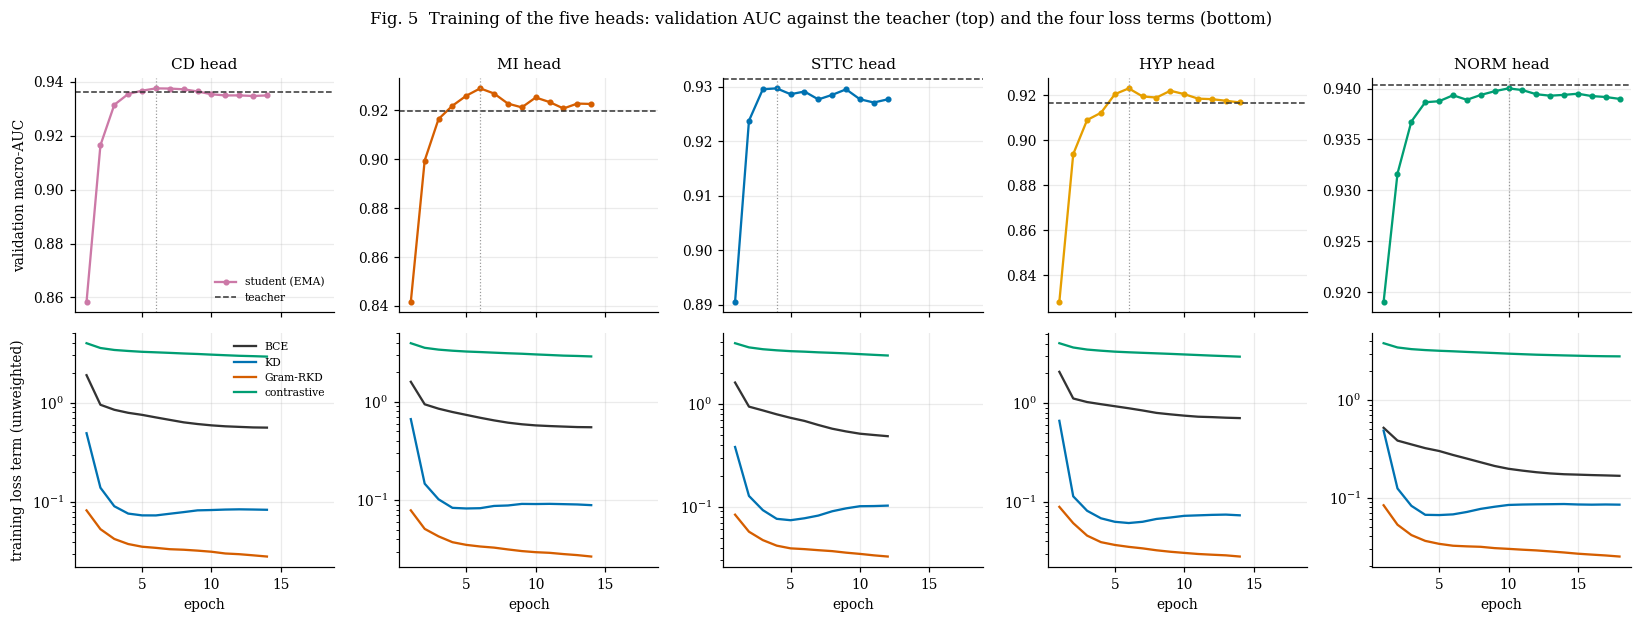

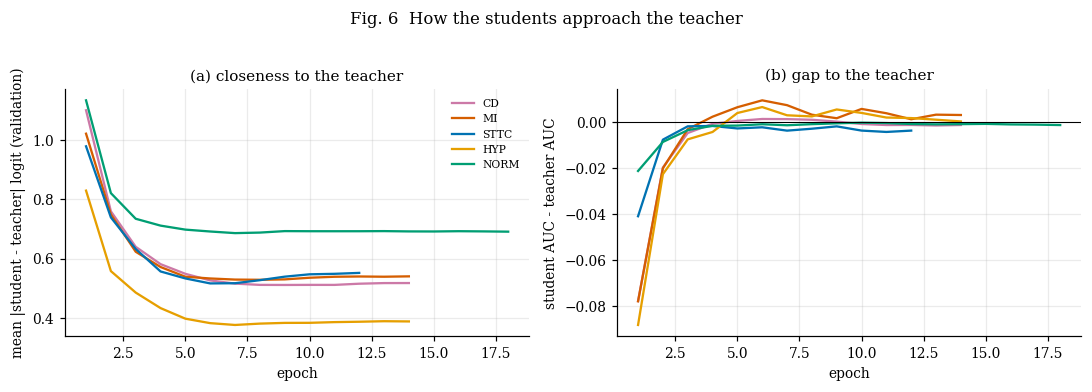

In [18]:
# Fig. 5 / 6  training curves
fig, axes = plt.subplots(2, 5, figsize=(15, 5.6), sharex=True)
for k, n in enumerate(CFG['hods']):
    h = pd.DataFrame(RES[n]['history']); cols = RES[n]['cols']
    t_auc = macro_auc_cols(Yva[:, cols], TL_va[:, cols], MP)
    ax = axes[0, k]
    ax.plot(h.epoch, h.val_macro_auc, 'o-', ms=3, color=SUPER_COL[n], label='student (EMA)')
    ax.axhline(t_auc, color=C_TEACHER, ls='--', lw=1, label='teacher')
    ax.axvline(RES[n]['best_epoch'], color='#999', lw=0.8, ls=':')
    ax.set_title(f'{n} head'); ax.set_ylabel('validation macro-AUC' if k == 0 else '')
    if k == 0: ax.legend(fontsize=7)
    ax = axes[1, k]
    for nm, c in [('sup', '#333'), ('kd', '#0072B2'), ('rkd', '#D55E00'), ('con', '#009E73')]:
        ax.plot(h.epoch, h[nm], color=c, label={'sup': 'BCE', 'kd': 'KD', 'rkd': 'Gram-RKD', 'con': 'contrastive'}[nm])
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('training loss term (unweighted)' if k == 0 else '')
    if k == 0: ax.legend(fontsize=7)
fig.suptitle('Fig. 5  Training of the five heads: validation AUC against the teacher (top) and the four loss terms (bottom)', y=1.0)
fig.tight_layout()
save_fig(fig, 'fig05_training_curves')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for n in CFG['hods']:
    h = pd.DataFrame(RES[n]['history'])
    axes[0].plot(h.epoch, h.val_logit_mae, color=SUPER_COL[n], label=n)
    axes[1].plot(h.epoch, h.val_macro_auc - macro_auc_cols(Yva[:, RES[n]['cols']], TL_va[:, RES[n]['cols']], MP), color=SUPER_COL[n], label=n)
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('mean |student - teacher| logit (validation)'); axes[0].set_title('(a) closeness to the teacher'); axes[0].legend(fontsize=7)
axes[1].axhline(0, color='k', lw=0.7); axes[1].set_xlabel('epoch'); axes[1].set_ylabel('student AUC - teacher AUC'); axes[1].set_title('(b) gap to the teacher')
fig.suptitle('Fig. 6  How the students approach the teacher', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig06_teacher_gap_curves')

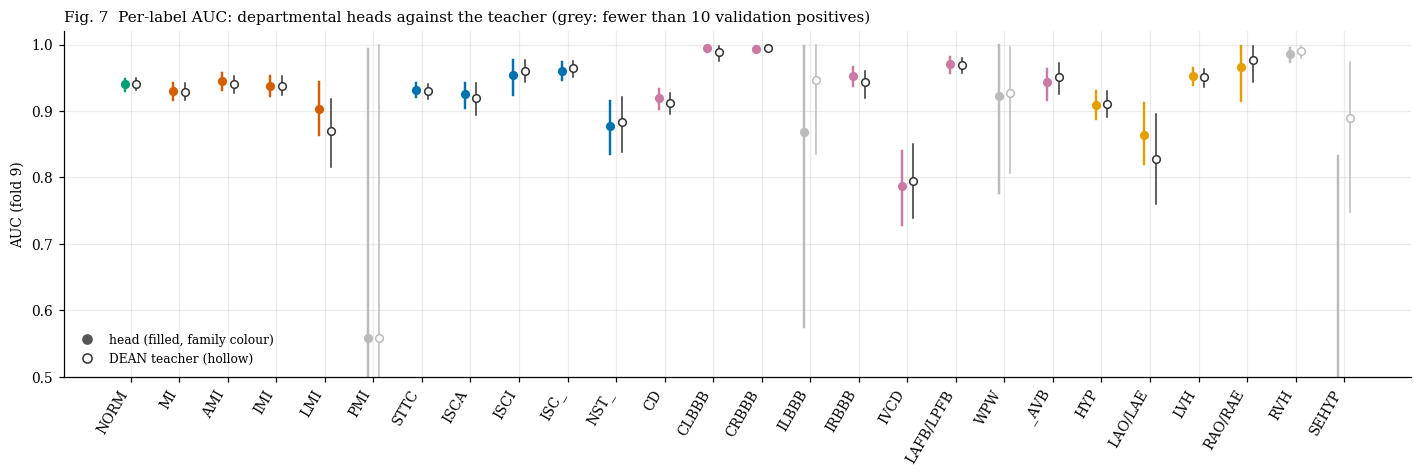

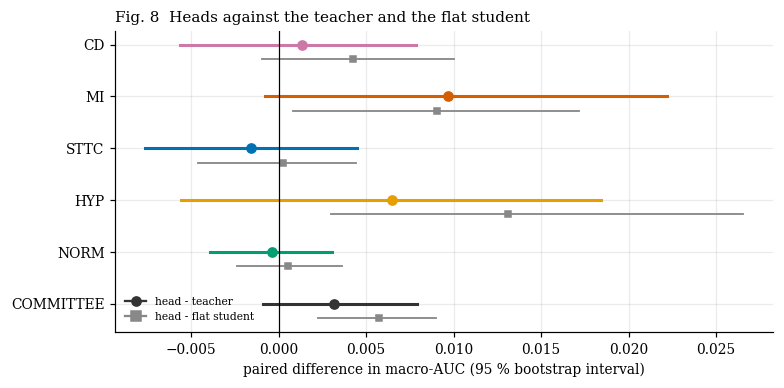

In [19]:
# Fig. 7  per-label AUC, student against teacher, with bootstrap intervals
order = [l for s in SUPER for l in [s] + [x for x in SUB if FAMILY[x] == s]]
idx = [LABELS.index(l) for l in order]
fig, ax = plt.subplots(figsize=(13, 4.4))
for k, j in enumerate(idx):
    fam = LABELS[j] if LABELS[j] in SUPER else FAMILY[LABELS[j]]
    ok = bool(PL.reliable[j])
    c = SUPER_COL[fam] if ok else '#BBBBBB'
    ax.plot([k - 0.12, k - 0.12], [PL.auc_lo[j], PL.auc_hi[j]], color=c, lw=1.6)
    ax.plot(k - 0.12, PL.auc_student[j], 'o', color=c, ms=5)
    ax.plot([k + 0.12, k + 0.12], [PL.teacher_lo[j], PL.teacher_hi[j]], color=C_TEACHER if ok else '#BBBBBB', lw=1.0)
    ax.plot(k + 0.12, PL.auc_teacher[j], 'o', mfc='white', mec=C_TEACHER if ok else '#BBBBBB', ms=5)
ax.set_xticks(range(len(idx))); ax.set_xticklabels(order, rotation=60, ha='right'); ax.set_ylabel('AUC (fold 9)')
ax.set_ylim(0.5, 1.02)
ax.plot([], [], 'o', color='#555', label='head (filled, family colour)'); ax.plot([], [], 'o', mfc='white', mec=C_TEACHER, label='DEAN teacher (hollow)'); ax.legend(loc='lower left', fontsize=8)
ax.set_title('Fig. 7  Per-label AUC: departmental heads against the teacher (grey: fewer than %d validation positives)' % MP, loc='left')
fig.tight_layout()
save_fig(fig, 'fig07_per_label_auc')

# Fig. 8  paired differences
fig, ax = plt.subplots(figsize=(7.2, 3.6))
names = CFG['hods'] + ['COMMITTEE']
for k, n in enumerate(names):
    d = EV[n]['delta']
    ax.plot([d[1], d[2]], [k, k], color=SUPER_COL.get(n, '#333'), lw=2)
    ax.plot(d[0], k, 'o', color=SUPER_COL.get(n, '#333'))
    if EVF is not None:
        cols = EV[n]['cols']
        dd = paired_delta(Yva[:, cols], EV[n]['S'], EVF['S'][:, cols], MP, NB)
        ax.plot([dd[1], dd[2]], [k + 0.28, k + 0.28], color='#888', lw=1.2)
        ax.plot(dd[0], k + 0.28, 's', color='#888', ms=4)
ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis()
ax.set_xlabel('paired difference in macro-AUC (95 % bootstrap interval)')
ax.plot([], [], 'o-', color='#333', label='head - teacher'); ax.plot([], [], 's-', color='#888', label='head - flat student'); ax.legend(fontsize=7, loc='lower left')
ax.set_title('Fig. 8  Heads against the teacher and the flat student', loc='left')
fig.tight_layout()
save_fig(fig, 'fig08_paired_differences')

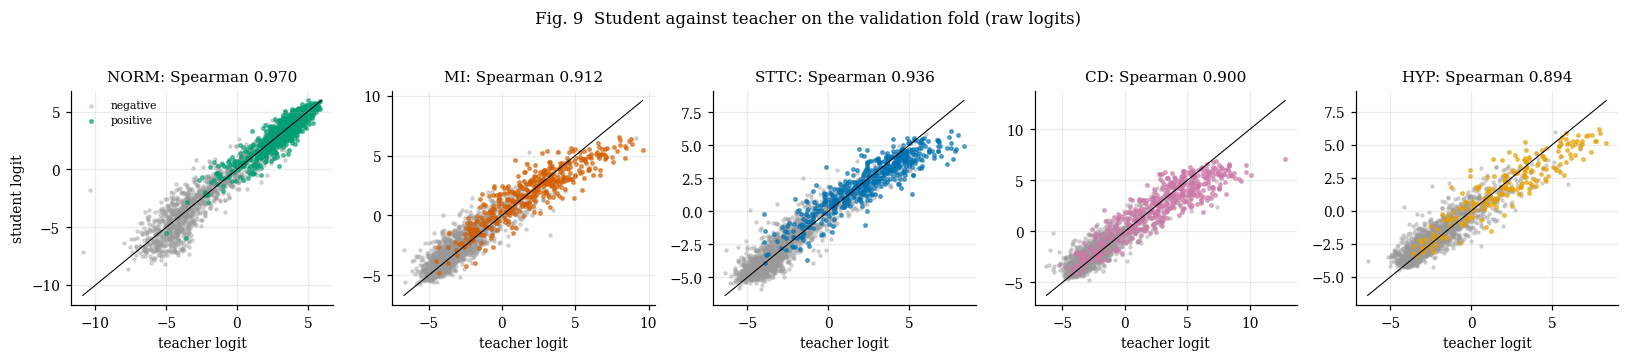

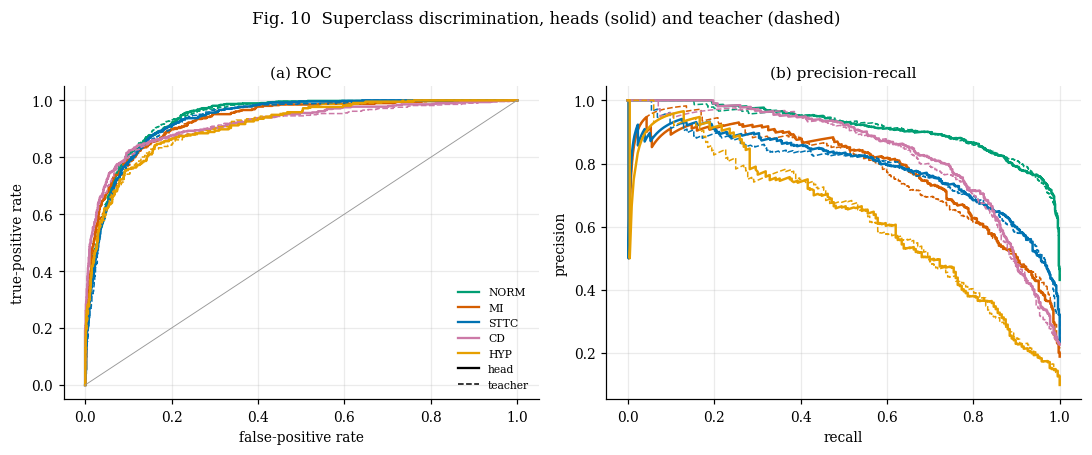

In [20]:
# Fig. 9  student against teacher logits (validation), superclass columns
fig, axes = plt.subplots(1, 5, figsize=(15, 3.1))
for ax, s in zip(axes, SUPER):
    j = LABELS.index(s); k = RES[s]['cols'].index(j)
    zt, zs, yy = TL_va[:, j], PRED[s]['lg_va'][:, k], Yva[:, j]
    ax.scatter(zt[yy == 0], zs[yy == 0], s=4, alpha=0.35, color='#999', label='negative')
    ax.scatter(zt[yy == 1], zs[yy == 1], s=5, alpha=0.6, color=SUPER_COL[s], label='positive')
    lim = [min(zt.min(), zs.min()), max(zt.max(), zs.max())]
    ax.plot(lim, lim, color='k', lw=0.7)
    ax.set_title(f'{s}: Spearman {spearmanr(zt, zs)[0]:.3f}'); ax.set_xlabel('teacher logit')
    if s == 'NORM': ax.set_ylabel('student logit'); ax.legend(fontsize=7)
fig.suptitle('Fig. 9  Student against teacher on the validation fold (raw logits)', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig09_student_vs_teacher_logits')

# Fig. 10  ROC and precision-recall of the five superclass heads
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for s in SUPER:
    j = LABELS.index(s)
    for S_, ls, lw in [(EV['COMMITTEE']['S'][:, j], '-', 1.6), (EV['COMMITTEE']['Sd'][:, j], '--', 1.0)]:
        f, t, _ = roc_curve(Yva[:, j], S_); axes[0].plot(f, t, ls, color=SUPER_COL[s], lw=lw)
        p, r, _ = precision_recall_curve(Yva[:, j], S_); axes[1].plot(r, p, ls, color=SUPER_COL[s], lw=lw)
axes[0].plot([0, 1], [0, 1], color='#999', lw=0.6); axes[0].set_xlabel('false-positive rate'); axes[0].set_ylabel('true-positive rate'); axes[0].set_title('(a) ROC')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('(b) precision-recall')
for s in SUPER: axes[0].plot([], [], color=SUPER_COL[s], label=s)
axes[0].plot([], [], '-', color='k', label='head'); axes[0].plot([], [], '--', color='k', lw=1, label='teacher'); axes[0].legend(fontsize=7, loc='lower right')
fig.suptitle('Fig. 10  Superclass discrimination, heads (solid) and teacher (dashed)', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig10_roc_pr_superclass')

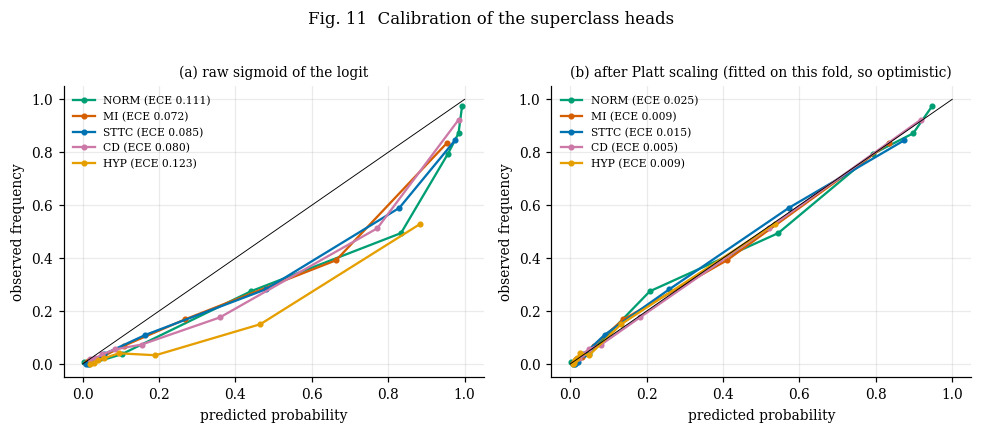

In [21]:
# Fig. 11  calibration of the heads
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for s in SUPER:
    j = LABELS.index(s); k = RES[s]['cols'].index(j)
    c0, a0, e0 = reliability(Yva[:, j], sigmoid(PRED[s]['lg_va'][:, k]), 8)
    c1, a1, e1 = reliability(Yva[:, j], EV['COMMITTEE']['S'][:, j], 8)
    axes[0].plot(c0, a0, 'o-', ms=3, color=SUPER_COL[s], label=f'{s} (ECE {e0:.3f})')
    axes[1].plot(c1, a1, 'o-', ms=3, color=SUPER_COL[s], label=f'{s} (ECE {e1:.3f})')
for ax, ttl in zip(axes, ['(a) raw sigmoid of the logit', '(b) after Platt scaling (fitted on this fold, so optimistic)']):
    ax.plot([0, 1], [0, 1], color='k', lw=0.6); ax.set_xlabel('predicted probability'); ax.set_ylabel('observed frequency'); ax.set_title(ttl, fontsize=9); ax.legend(fontsize=7)
fig.suptitle('Fig. 11  Calibration of the superclass heads', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig11_calibration')

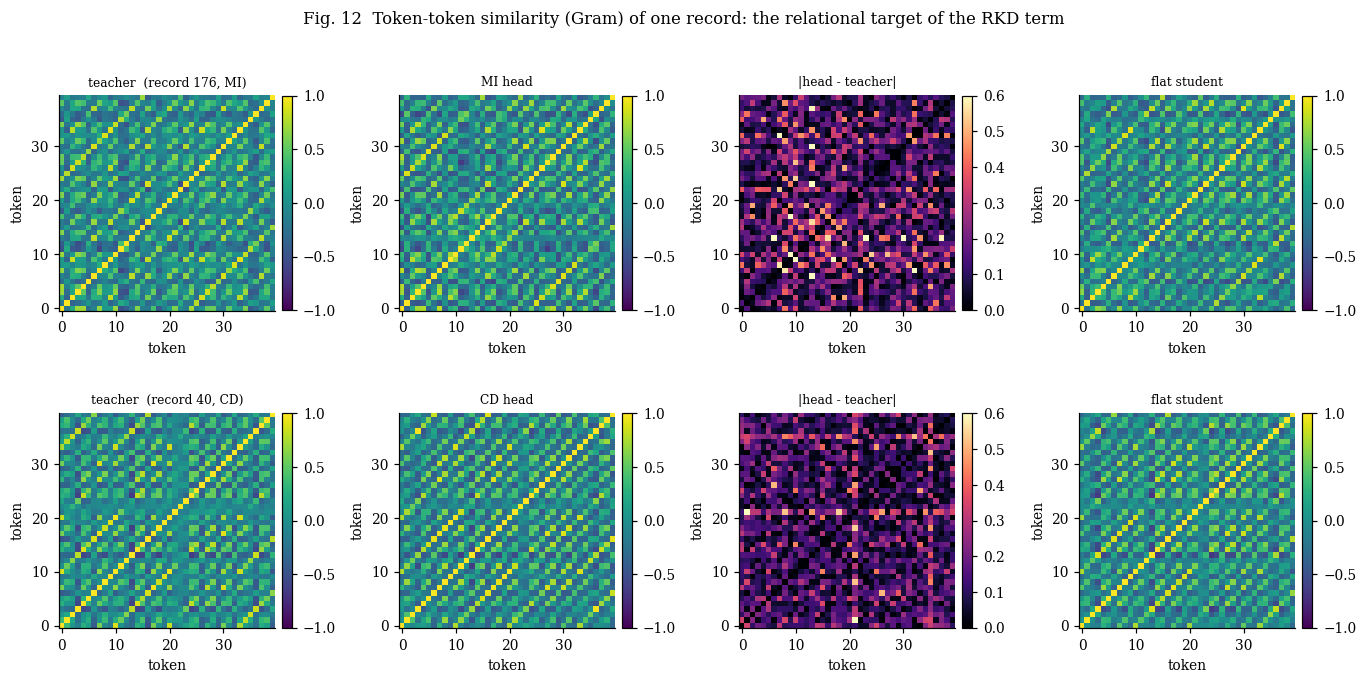

In [22]:
# Fig. 12  token Gram matrices: what the RKD term asks the student to reproduce
single = np.where(Yva[:, :5].sum(1) == 1)[0]
chosen = []
for s in ['MI', 'CD']:
    c = [i for i in single if Yva[i, SUPER.index(s)] == 1]
    if c: chosen.append((s, c[0]))
if chosen:
    fig, axes = plt.subplots(len(chosen), 4, figsize=(12.5, 3.1 * len(chosen)), squeeze=False)
    for r_, (s, i) in enumerate(chosen):
        gt = hod_lib.token_gram(torch.from_numpy(TK_va[i:i + 1].astype(np.float32)))[0].numpy()
        gs = hod_lib.token_gram(torch.from_numpy(PRED[s]['tk_va'][i:i + 1].astype(np.float32)))[0].numpy()
        gf = hod_lib.token_gram(torch.from_numpy(PFLAT['tk_va'][i:i + 1].astype(np.float32)))[0].numpy() if PFLAT is not None else None
        panels = [('teacher', gt), (f'{s} head', gs), (f'|head - teacher|', np.abs(gs - gt))]
        panels.append(('flat student', gf) if gf is not None else ('(no flat student)', np.zeros_like(gt)))
        for ax, (ttl, M) in zip(axes[r_], panels):
            im = ax.imshow(M, cmap='magma' if 'head -' in ttl else 'viridis', vmin=0 if 'head -' in ttl else -1, vmax=1 if 'head -' not in ttl else 0.6, origin='lower')
            ax.set_title(f'{ttl}' + (f'  (record {va_idx[i]}, {s})' if ttl == 'teacher' else ''), fontsize=8); ax.grid(False)
            ax.set_xlabel('token'); ax.set_ylabel('token')
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    fig.suptitle('Fig. 12  Token-token similarity (Gram) of one record: the relational target of the RKD term', y=1.01)
    fig.tight_layout()
    save_fig(fig, 'fig12_token_gram_examples')

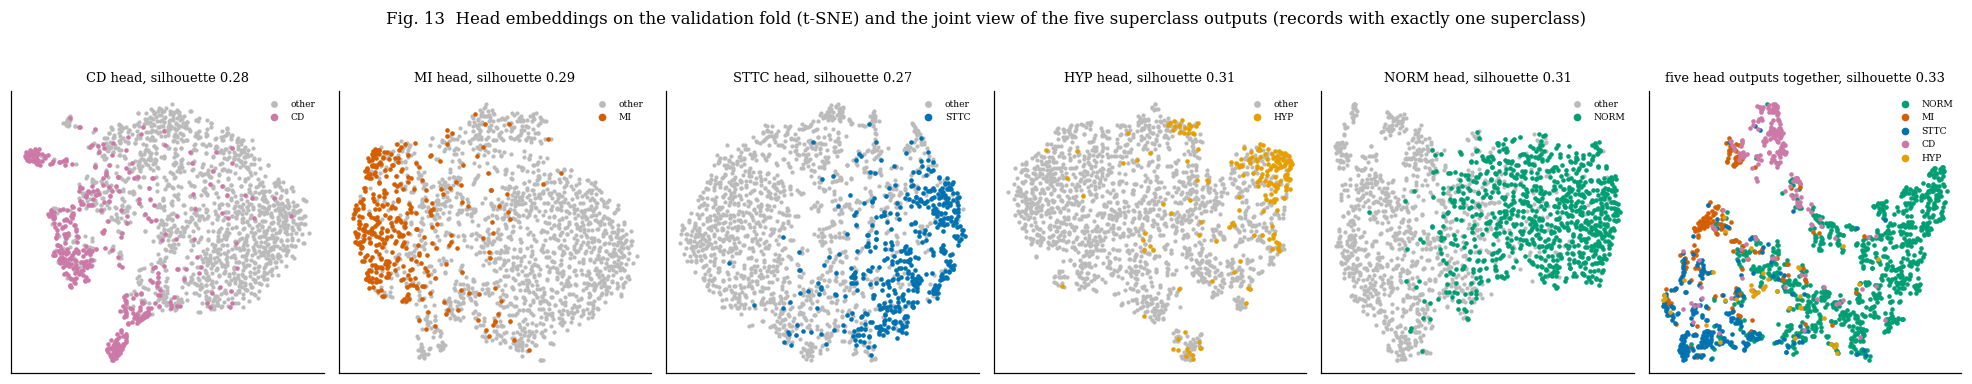

silhouette: {'CD': 0.282, 'MI': 0.294, 'STTC': 0.269, 'HYP': 0.307, 'NORM': 0.311, 'joint': 0.331}


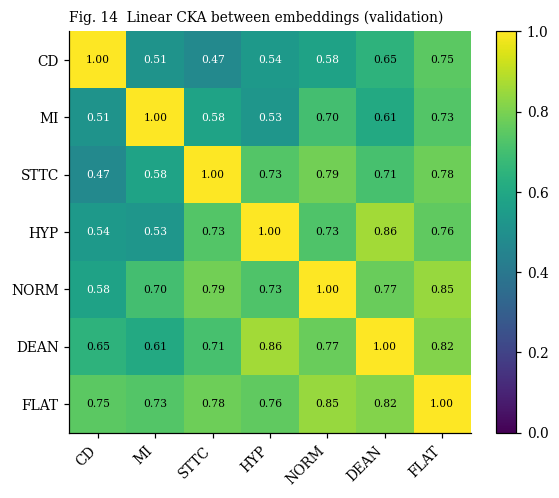

In [23]:
# Fig. 13  embeddings of the heads (t-SNE, validation) and the quantitative cluster check
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
rs = np.random.default_rng(0)
sel = rs.choice(len(va_idx), min(2000, len(va_idx)), replace=False)
def tsne(Z, seed=0):
    return TSNE(2, perplexity=max(5, min(30, (len(Z) - 1) / 4)), random_state=seed, init='pca').fit_transform(Z)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.3))
SIL = {}
for ax, n in zip(axes[:5], CFG['hods']):
    j = LABELS.index(n); y = Yva[sel, j]
    E2 = tsne(PRED[n]['em_va'][sel])
    ax.scatter(E2[y == 0, 0], E2[y == 0, 1], s=3, color='#BBBBBB', label='other')
    ax.scatter(E2[y == 1, 0], E2[y == 1, 1], s=4, color=SUPER_COL[n], label=n)
    SIL[n] = float(silhouette_score(PRED[n]['em_va'][sel], y)) if 0 < y.sum() < len(y) else np.nan
    ax.set_title(f'{n} head, silhouette {SIL[n]:.2f}', fontsize=8.5); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.legend(fontsize=6, markerscale=2)
sup_prob = EV['COMMITTEE']['S'][:, :5]
one = np.where(Yva[:, :5].sum(1) == 1)[0]
one = rs.choice(one, min(1500, len(one)), replace=False)
lab1 = Yva[one, :5].argmax(1)
J2 = tsne(sup_prob[one])
for k, s in enumerate(SUPER):
    axes[5].scatter(J2[lab1 == k, 0], J2[lab1 == k, 1], s=4, color=SUPER_COL[s], label=s)
SIL['joint'] = float(silhouette_score(sup_prob[one], lab1))
axes[5].set_title(f'five head outputs together, silhouette {SIL["joint"]:.2f}', fontsize=8.5); axes[5].set_xticks([]); axes[5].set_yticks([]); axes[5].grid(False); axes[5].legend(fontsize=6, markerscale=2)
fig.suptitle('Fig. 13  Head embeddings on the validation fold (t-SNE) and the joint view of the five superclass outputs (records with exactly one superclass)', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig13_hod_tsne')
print('silhouette:', {k: round(v, 3) for k, v in SIL.items()})

# Fig. 14  linear CKA between the head embeddings, the teacher and the flat student
names_c = CFG['hods'] + ['DEAN'] + (['FLAT'] if PFLAT is not None else [])
embs = {n: PRED[n]['em_va'] for n in CFG['hods']}
embs['DEAN'] = TE_va
if PFLAT is not None: embs['FLAT'] = PFLAT['em_va']
CKA = np.array([[hod_lib.linear_cka(embs[a], embs[b]) for b in names_c] for a in names_c])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(CKA, cmap='viridis', vmin=0, vmax=1, origin='upper'); ax.grid(False)
ax.set_xticks(range(len(names_c))); ax.set_xticklabels(names_c, rotation=45, ha='right'); ax.set_yticks(range(len(names_c))); ax.set_yticklabels(names_c)
for a in range(len(names_c)):
    for b in range(len(names_c)):
        ax.text(b, a, f'{CKA[a, b]:.2f}', ha='center', va='center', fontsize=7, color='w' if CKA[a, b] < 0.6 else 'k')
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title('Fig. 14  Linear CKA between embeddings (validation)', fontsize=9, loc='left')
fig.tight_layout()
save_fig(fig, 'fig14_cka')
pd.DataFrame(CKA, index=names_c, columns=names_c).to_csv(os.path.join(TAB_DIR, 'cka_embeddings.csv'))

      train_auc  val_auc  teacher_train_oof  teacher_train_insample  teacher_val
head                                                                            
CD       0.9891   0.9375             0.9374                  0.9879       0.9362
MI       0.9905   0.9289             0.9125                  0.9822       0.9195
STTC     0.9675   0.9297             0.9305                  0.9751       0.9314
HYP      0.9843   0.9229             0.8936                  0.9889       0.9164
NORM     0.9955   0.9400             0.9434                  0.9657       0.9403


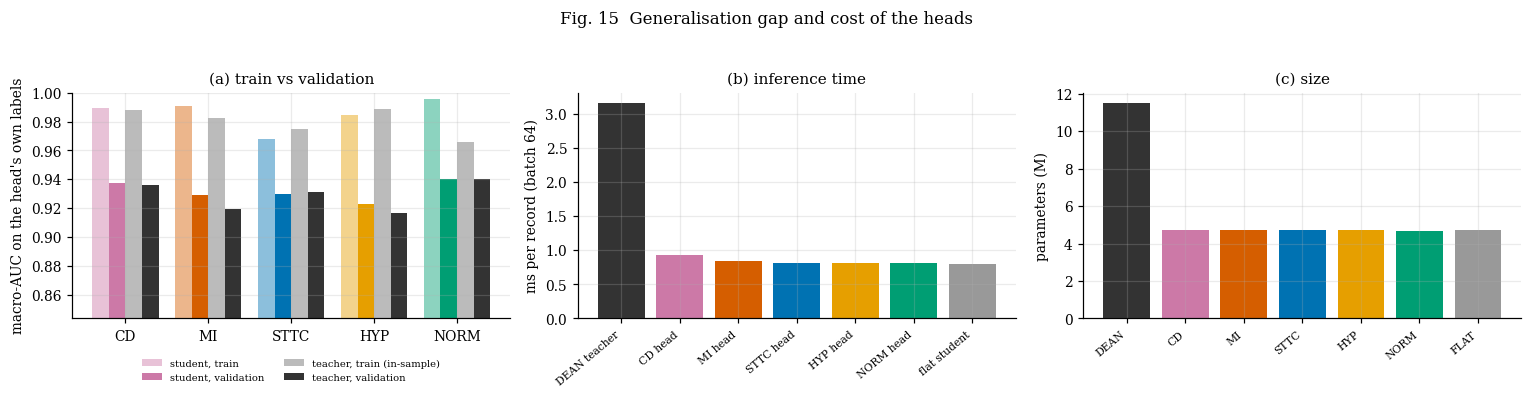

{'DEAN teacher': 3.16, 'CD head': 0.93, 'MI head': 0.85, 'STTC head': 0.82, 'HYP head': 0.81, 'NORM head': 0.81, 'flat student': 0.8}


In [24]:
# Fig. 15  generalisation gap of the students, and efficiency
gap_rows = []
for n in CFG['hods']:
    cols = RES[n]['cols']
    gap_rows.append(dict(head=n, train_auc=macro_auc_cols(Ytr_np[:, cols], sigmoid(PRED[n]['lg_tr']), MP),
                         val_auc=macro_auc_cols(Yva[:, cols], sigmoid(PRED[n]['lg_va']), MP),
                         teacher_train_oof=macro_auc_cols(Ytr_np[:, cols], TL_oof[:, cols], MP),
                         teacher_train_insample=macro_auc_cols(Ytr_np[:, cols], TL_in[:, cols], MP),
                         teacher_val=macro_auc_cols(Yva[:, cols], TL_va[:, cols], MP)))
GAP = pd.DataFrame(gap_rows).set_index('head')
print(GAP.round(4).to_string())
GAP.to_csv(os.path.join(TAB_DIR, 'table_generalisation_gap.csv'))

@torch.no_grad()
def ms_per_record(fn, x, reps=5):
    with amp(): fn(x[:8])
    if USE_AMP: torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        with amp(): fn(x)
    if USE_AMP: torch.cuda.synchronize()
    return (time.time() - t0) / reps / len(x) * 1000
xb = DATA['X_va'][:64]
LAT = {'DEAN teacher': ms_per_record(lambda x: teacher.features(x), xb)}
for n in CFG['hods']:
    RES[n]['net'].eval(); LAT[f'{n} head'] = ms_per_record(lambda x, m=RES[n]['net']: m(x), xb)
if FLAT is not None:
    FLAT['net'].eval(); LAT['flat student'] = ms_per_record(lambda x: FLAT['net'](x), xb)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
x = np.arange(len(GAP)); w = 0.2
axes[0].bar(x - 1.5 * w, GAP.train_auc, w, color=[SUPER_COL[n] for n in GAP.index], alpha=0.45, label='student, train')
axes[0].bar(x - 0.5 * w, GAP.val_auc, w, color=[SUPER_COL[n] for n in GAP.index], label='student, validation')
axes[0].bar(x + 0.5 * w, GAP.teacher_train_insample, w, color='#BBBBBB', label='teacher, train (in-sample)')
axes[0].bar(x + 1.5 * w, GAP.teacher_val, w, color=C_TEACHER, label='teacher, validation')
axes[0].set_xticks(x); axes[0].set_xticklabels(GAP.index); lo = float(np.nanmin(GAP.values)); axes[0].set_ylim(max(0.5, lo - 0.05), 1.0)
axes[0].set_ylabel('macro-AUC on the head\'s own labels'); axes[0].set_title('(a) train vs validation'); axes[0].legend(fontsize=6.5, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2)
nm = list(LAT)
axes[1].bar(range(len(nm)), [LAT[k] for k in nm], color=[C_TEACHER] + [SUPER_COL[n] for n in CFG['hods']] + ([C_FLAT] if FLAT is not None else []))
axes[1].set_xticks(range(len(nm))); axes[1].set_xticklabels(nm, rotation=40, ha='right', fontsize=7); axes[1].set_ylabel('ms per record (batch 64)'); axes[1].set_title('(b) inference time')
pm = ['DEAN'] + CFG['hods'] + (['FLAT'] if FLAT is not None else [])
axes[2].bar(range(len(pm)), [T_PARAMS / 1e6] + [PARAMS[n] / 1e6 for n in CFG['hods']] + ([PARAMS['FLAT'] / 1e6] if FLAT is not None else []),
            color=[C_TEACHER] + [SUPER_COL[n] for n in CFG['hods']] + ([C_FLAT] if FLAT is not None else []))
axes[2].set_xticks(range(len(pm))); axes[2].set_xticklabels(pm, rotation=40, ha='right', fontsize=7); axes[2].set_ylabel('parameters (M)'); axes[2].set_title('(c) size')
fig.suptitle('Fig. 15  Generalisation gap and cost of the heads', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig15_gap_and_efficiency')
json.dump({k: float(v) for k, v in LAT.items()}, open(os.path.join(TAB_DIR, 'latency_ms_per_record.json'), 'w'), indent=1)
print({k: round(v, 2) for k, v in LAT.items()})

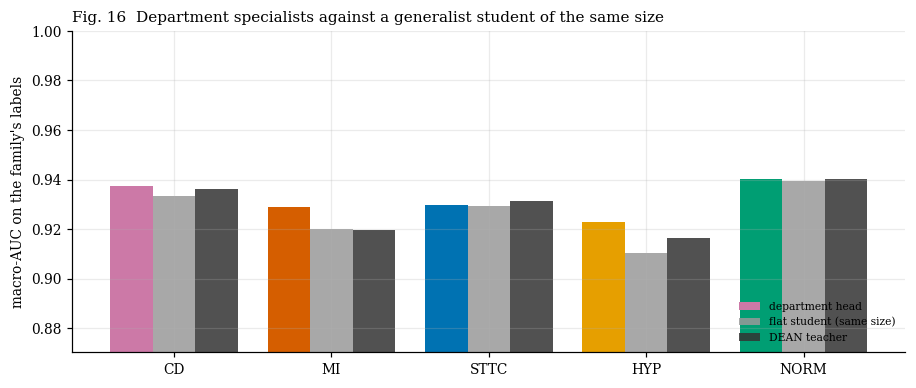

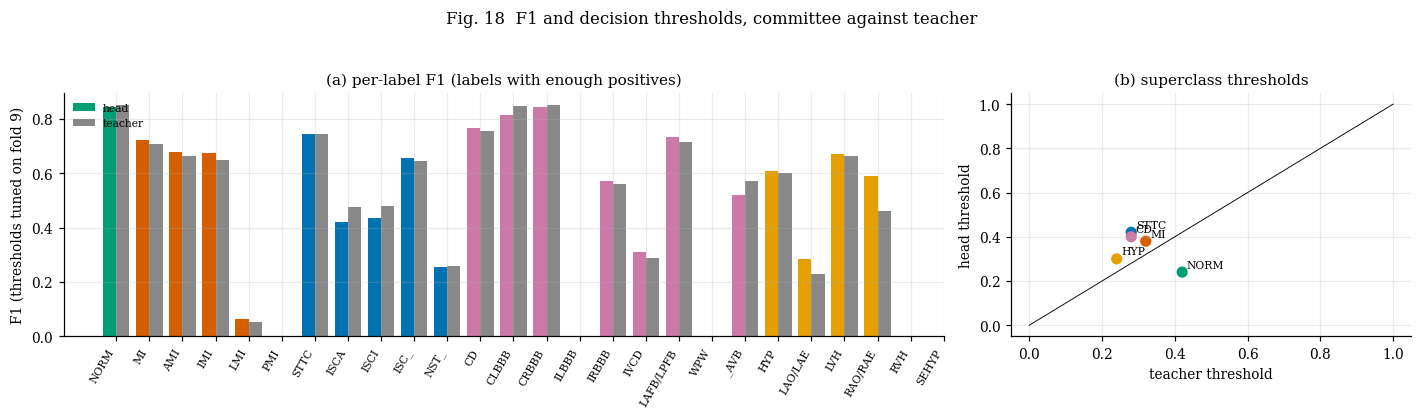

In [25]:
# Fig. 16  specialist against generalist, per family
if EVF is not None:
    fig, ax = plt.subplots(figsize=(8.4, 3.6))
    fams = CFG['hods']
    x = np.arange(len(fams)); w = 0.27
    for off, key, c, lab in [(-w, 'head', None, 'department head'), (0, 'flat student', C_FLAT, 'flat student (same size)'), (w, 'teacher', C_TEACHER, 'DEAN teacher')]:
        vals = [FAMCMP.loc[f, key] for f in fams]
        ax.bar(x + off, vals, w, color=[SUPER_COL[f] for f in fams] if c is None else c, label=lab, alpha=1.0 if c is None else 0.85)
    ax.set_xticks(x); ax.set_xticklabels(fams); ax.set_ylim(max(0.5, float(FAMCMP[['head', 'flat student', 'teacher']].iloc[:-1].min().min()) - 0.04), 1.0)
    ax.set_ylabel('macro-AUC on the family\'s labels'); ax.legend(fontsize=7, loc='lower right')
    ax.set_title('Fig. 16  Department specialists against a generalist student of the same size', loc='left')
    fig.tight_layout()
    save_fig(fig, 'fig16_specialist_vs_generalist')

# Fig. 18  F1 and thresholds
e = EV['COMMITTEE']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
ok = np.array([bool(PL.reliable[j]) for j in idx])
f1s = np.array([PL.f1_student[j] for j in idx]); f1t = np.array([PL.f1_teacher[j] for j in idx])
xx = np.arange(len(idx))
axes[0].bar(xx - 0.2, np.where(ok, f1s, np.nan), 0.4, color=[SUPER_COL[PL.family[j]] for j in idx], label='head')
axes[0].bar(xx + 0.2, np.where(ok, f1t, np.nan), 0.4, color='#888888', label='teacher')
axes[0].set_xticks(xx); axes[0].set_xticklabels(order, rotation=60, ha='right', fontsize=7); axes[0].set_ylabel('F1 (thresholds tuned on fold 9)'); axes[0].legend(fontsize=7)
axes[0].set_title('(a) per-label F1 (labels with enough positives)')
axes[1].scatter(e['thr_d'][:5], e['thr'][:5], c=[SUPER_COL[s] for s in SUPER], s=40)
for k, s in enumerate(SUPER): axes[1].annotate(s, (e['thr_d'][k], e['thr'][k]), fontsize=7, xytext=(3, 3), textcoords='offset points')
axes[1].plot([0, 1], [0, 1], color='k', lw=0.6); axes[1].set_xlabel('teacher threshold'); axes[1].set_ylabel('head threshold'); axes[1].set_title('(b) superclass thresholds')
fig.suptitle('Fig. 18  F1 and decision thresholds, committee against teacher', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig18_f1_thresholds')

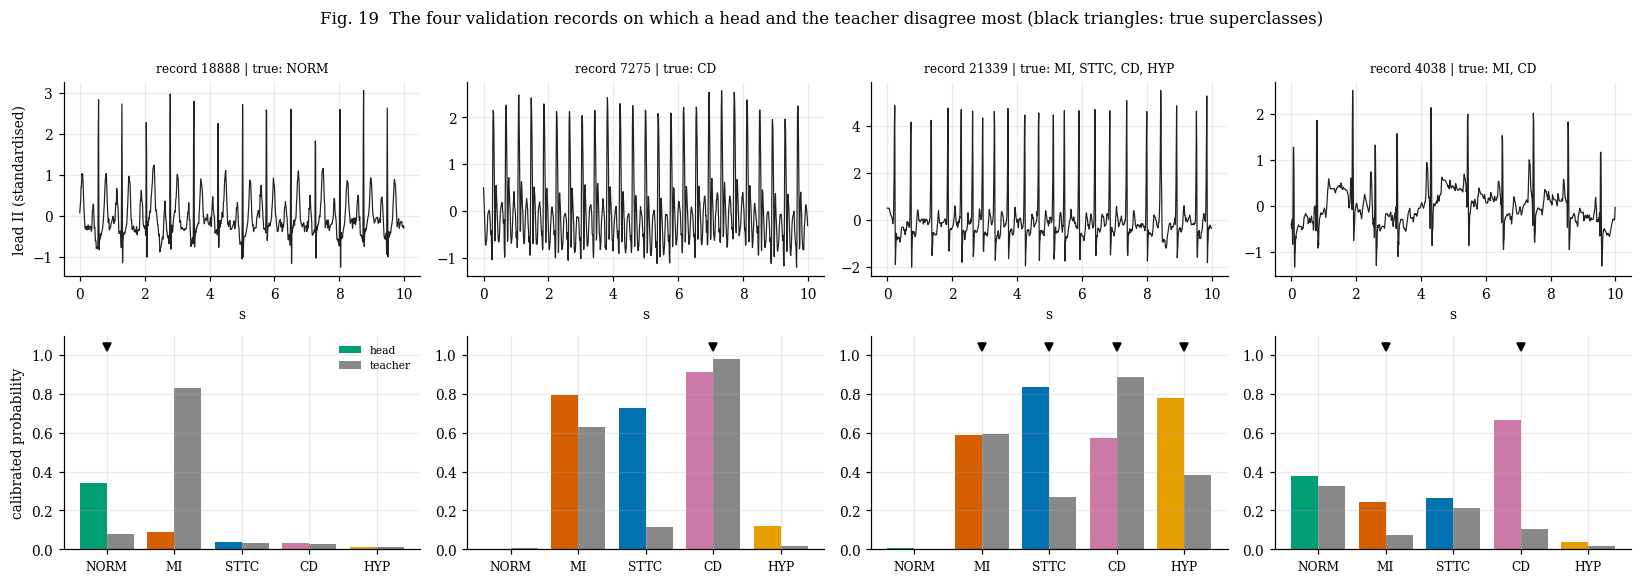

In [26]:
# Fig. 19  records where a head disagrees most with the teacher (superclass probability)
dis = np.abs(EV['COMMITTEE']['S'][:, :5] - EV['COMMITTEE']['Sd'][:, :5])
top = np.argsort(-dis.max(1))[:4]
fig, axes = plt.subplots(2, 4, figsize=(15, 5.2), gridspec_kw=dict(height_ratios=[1, 1.1]))
Xv = DATA['X_va'].cpu().numpy()
for k, i in enumerate(top):
    ax = axes[0, k]
    ax.plot(np.arange(1000) / 100, Xv[i, 1], color='#222', lw=0.8)
    tr_ = [SUPER[q] for q in range(5) if Yva[i, q] > 0] or ['none']
    ax.set_title(f'record {va_idx[i]} | true: {", ".join(tr_)}', fontsize=8); ax.set_xlabel('s'); ax.set_ylabel('lead II (standardised)' if k == 0 else '')
    ax = axes[1, k]
    xs = np.arange(5)
    ax.bar(xs - 0.2, EV['COMMITTEE']['S'][i, :5], 0.4, color=[SUPER_COL[s] for s in SUPER], label='head')
    ax.bar(xs + 0.2, EV['COMMITTEE']['Sd'][i, :5], 0.4, color='#888', label='teacher')
    for q in range(5):
        if Yva[i, q] > 0: ax.plot(q, 1.04, 'v', color='k', ms=5)
    ax.set_xticks(xs); ax.set_xticklabels(SUPER, fontsize=8); ax.set_ylim(0, 1.1); ax.set_ylabel('calibrated probability' if k == 0 else '')
    if k == 0: ax.legend(fontsize=7)
fig.suptitle('Fig. 19  The four validation records on which a head and the teacher disagree most (black triangles: true superclasses)', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig19_disagreement_examples')

## 13. Ablation: which part of the recipe matters?
One family (`ablation_family`, CD by default: the largest, with eight subclasses) is trained for `ablation_epochs` epochs under eight settings. Every run uses the same seed, the same schedule and the same data; only the named setting changes, and the **full recipe is re-run with the same short schedule** so the comparison is like for like (it is not the 30-epoch head from section 8).

| Run | What changes |
|---|---|
| full recipe | nothing |
| supervised only | no KD, no Gram-RKD, no contrastive term: the same student trained on labels alone |
| no logit KD / no Gram-RKD / no contrastive | one term removed |
| in-sample teacher logits | KD target is the final teacher's logit on records it trained on |
| DEAN-layer initialisation | student blocks start from evenly spaced DEAN blocks (a different thing from the plan's re-initialised weights) |
| family-enriched sampling | records that belong to the family are drawn twice as often |

Differences are paired bootstrap intervals on the validation fold. Differences of a few thousandths of AUC are inside the noise of a single seed and should not be written up as effects.

[abl0_CD] already trained (best epoch 6, val AUC 0.9377), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_abl0_CD_final.pt
[abl1_CD] already trained (best epoch 6, val AUC 0.9200), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_abl1_CD_final.pt
[abl2_CD] already trained (best epoch 4, val AUC 0.9341), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_abl2_CD_final.pt
[abl3_CD] already trained (best epoch 6, val AUC 0.9370), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_abl3_CD_final.pt
[abl4_CD] already trained (best epoch 6, val AUC 0.9399), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_abl4_CD_final.pt
[abl5_CD] already trained (best epoch 6, val AUC 0.9385), loaded /kaggle/input/datasets/iaadidevresearch/results-stage-5-hod-distillation/hods/hod_abl5_CD_final.pt
[abl6_CD] alread

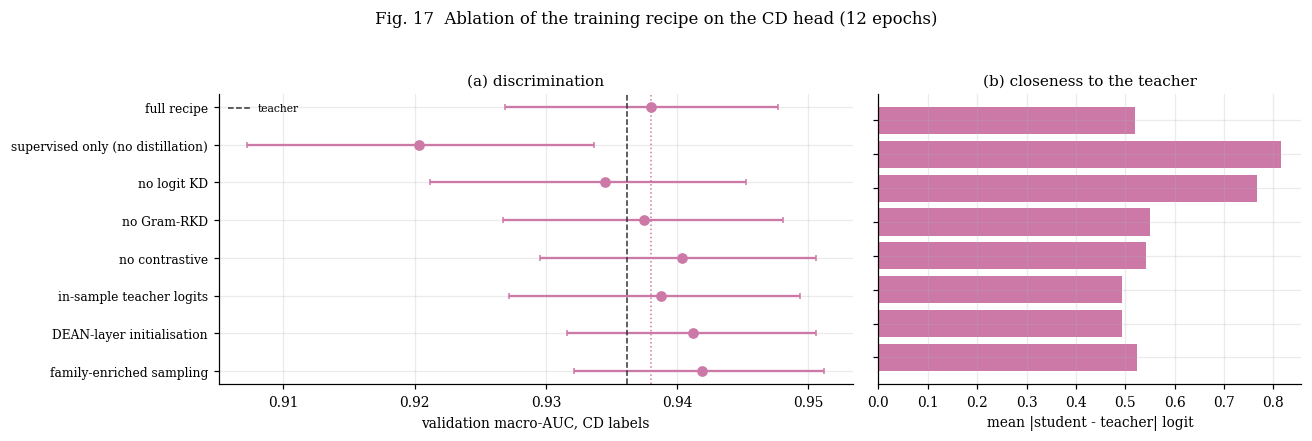

In [27]:
ABL = None
if CFG['run_ablation'] and not TIME_UP:
    fam = CFG['ablation_family']
    VARIANTS = {
        'full recipe': {},
        'supervised only (no distillation)': dict(w_kd=0.0, w_rkd=0.0, w_con=0.0),
        'no logit KD': dict(w_kd=0.0),
        'no Gram-RKD': dict(w_rkd=0.0),
        'no contrastive': dict(w_con=0.0),
        'in-sample teacher logits': dict(kd_source='insample'),
        'DEAN-layer initialisation': dict(init='dean_layers'),
        'family-enriched sampling': dict(sampler='enriched'),
    }
    ABL_RUNS = {}
    for k, (nm, ov) in enumerate(VARIANTS.items()):
        if TIME_UP:
            break
        c = head_cfg(fam); c.update(epochs=CFG['ablation_epochs'], warmup_epochs=1, patience=999); c.update(ov)
        r = run_training(f'abl{k}_{fam}', HOD_COLS[fam]['sup'], HOD_COLS[fam]['sub'], c, DATA)
        TIME_UP = r['stopped_early']
        if r['finished']:
            ABL_RUNS[nm] = r
        torch.cuda.empty_cache()
    if 'full recipe' in ABL_RUNS:
        cols = HOD_COLS[fam]['cols']
        Yc = Yva[:, cols]
        Z = {nm: predict_net(r['net'], DATA['X_va'])[0] for nm, r in ABL_RUNS.items()}
        S = {nm: sigmoid(z) for nm, z in Z.items()}
        S_t = sigmoid(TL_va[:, cols])
        rows = []
        for nm in ABL_RUNS:
            bt = bootstrap(Yc, S[nm], np.full(len(cols), 0.5), MP, NB, n_super=1)
            rows.append({'run': nm, 'macro-AUC': fmt(bt['macro_auc']), 'auc': bt['macro_auc'][0], 'lo': bt['macro_auc'][1], 'hi': bt['macro_auc'][2],
                         'vs full recipe': fmt(paired_delta(Yc, S[nm], S['full recipe'], MP, NB), 4) if nm != 'full recipe' else '-',
                         'vs teacher': fmt(paired_delta(Yc, S[nm], S_t, MP, NB), 4),
                         'val logit MAE': float(np.abs(Z[nm] - TL_va[:, cols]).mean()),
                         'best epoch': ABL_RUNS[nm]['best_epoch']})
        ABL = pd.DataFrame(rows).set_index('run')
        print(f'ablation on the {fam} family, {CFG["ablation_epochs"]} epochs, teacher macro-AUC {macro_auc_cols(Yc, TL_va[:, cols], MP):.4f}')
        print(ABL.drop(columns=['auc', 'lo', 'hi']).round(4).to_string())
        ABL.drop(columns=['auc', 'lo', 'hi']).to_csv(os.path.join(TAB_DIR, 'table_ablation.csv'))

        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
        names_a = list(ABL.index)
        y_ = np.arange(len(names_a))[::-1]
        axes[0].errorbar(ABL.auc, y_, xerr=[ABL.auc - ABL.lo, ABL.hi - ABL.auc], fmt='o', color=SUPER_COL[fam], capsize=2)
        axes[0].axvline(macro_auc_cols(Yc, TL_va[:, cols], MP), color=C_TEACHER, ls='--', lw=1, label='teacher')
        axes[0].axvline(ABL.auc['full recipe'], color=SUPER_COL[fam], ls=':', lw=1)
        axes[0].set_yticks(y_); axes[0].set_yticklabels(names_a, fontsize=8); axes[0].set_xlabel(f'validation macro-AUC, {fam} labels'); axes[0].legend(fontsize=7)
        axes[0].set_title('(a) discrimination')
        axes[1].barh(y_, ABL['val logit MAE'], color=SUPER_COL[fam]); axes[1].set_yticks(y_); axes[1].set_yticklabels([]); axes[1].set_xlabel('mean |student - teacher| logit')
        axes[1].set_title('(b) closeness to the teacher')
        fig.suptitle(f'Fig. 17  Ablation of the training recipe on the {fam} head ({CFG["ablation_epochs"]} epochs)', y=1.04)
        fig.tight_layout()
        save_fig(fig, 'fig17_ablation')
else:
    print('ablation skipped' if not CFG['run_ablation'] else 'ablation postponed: time budget used up, re-run to continue')

## 14. Export
Everything the next notebooks need:

* `hods/hod_<NAME>_final.pt` hold the training state; `hods/hod_<NAME>_deploy.pt` hold only what inference needs (no training projection) with the label columns, the student configuration, the input normalisation, the Platt parameters and the thresholds.
* `hod_logits_train.npy` / `hod_logits_val.npy`: the committee's 26 logits per record in the teacher's label order. The training logits are **in-sample for the students** (they were trained on those records). The generalisation gap is measured in Fig. 15; the Professor notebooks should keep it in mind, as NB-02's out-of-fold analysis does for the teacher.
* `hod_<NAME>_emb_{train,val}.npy`: the pooled 256-d embedding of each head.
* `hod_<NAME>_tokens_{train,val}_fp16.npy` (MI, STTC, CD, HYP): the 40 x 256 token sequence of each head, the Gram-RKD and contrastive targets of its Professors (the synopsis asks for "the same structure as Step 5" at Step 6). About 0.36 GB per head for the training set.
* `hod_calibration.json`: Platt parameters and F1 thresholds, per label, for the committee and per head.

In [28]:
cal_c = EV['COMMITTEE']
for n in CFG['hods']:
    r = RES[n]
    torch.save({'deploy': r['net'].deploy_state(), 'head': n, 'cols': r['cols'], 'labels': [LABELS[c] for c in r['cols']],
                'n_sup': len(r['sup_idx']), 'n_sub': len(r['sub_idx']), 'student_enc_cfg': dict(ENC_CFG, depth=CFG['depth'], grad_ckpt=False),
                'head_drop': CFG['head_drop'], 'sub_hidden': CFG['sub_hidden'], 'norm_mean': MU.tolist(), 'norm_std': SD.tolist(),
                'platt_a': cal_c['a'][r['cols']].tolist(), 'platt_b': cal_c['b'][r['cols']].tolist(), 'thresholds': cal_c['thr'][r['cols']].tolist(),
                'best_epoch': int(r['best_epoch']), 'val_macro_auc': float(r['best_score']), 'teacher_source': 'dean_finetuned.pt',
                'config': {k: head_cfg(n)[k] for k in SIG_KEYS}}, os.path.join(HOD_DIR, f'hod_{n}_deploy.pt'))
    np.save(os.path.join(WORK, f'hod_{n}_emb_train.npy'), PRED[n]['em_tr'].astype(np.float32))
    np.save(os.path.join(WORK, f'hod_{n}_emb_val.npy'), PRED[n]['em_va'].astype(np.float32))
    if len(r['sub_idx']) > 0:      # the Professors of this family distil the token relations of their parent head (synopsis, stage 6)
        np.save(os.path.join(WORK, f'hod_{n}_tokens_train_fp16.npy'), predict_net(r['net'], DATA['X_tr'], tokens=True)[2])
        np.save(os.path.join(WORK, f'hod_{n}_tokens_val_fp16.npy'), PRED[n]['tk_va'])
    pd.DataFrame(r['history']).to_csv(os.path.join(TAB_DIR, f'history_{n}.csv'), index=False)
np.save(os.path.join(WORK, 'hod_logits_train.npy'), COM_tr)
np.save(os.path.join(WORK, 'hod_logits_val.npy'), COM_va)
if FLAT is not None:
    torch.save({'deploy': FLAT['net'].deploy_state(), 'cols': FLAT['cols'], 'labels': LABELS}, os.path.join(HOD_DIR, 'flat_student_deploy.pt'))
    pd.DataFrame(FLAT['history']).to_csv(os.path.join(TAB_DIR, 'history_FLAT.csv'), index=False)

json.dump({'labels': LABELS, 'committee': {'platt_a': cal_c['a'].tolist(), 'platt_b': cal_c['b'].tolist(), 'thresholds': cal_c['thr'].tolist()},
           'per_head': {n: {'cols': EV[n]['cols'], 'platt_a': EV[n]['a'].tolist(), 'platt_b': EV[n]['b'].tolist(), 'thresholds': EV[n]['thr'].tolist()} for n in CFG['hods']},
           'note': 'fitted on fold 9. Thresholds are optimistic for F1; NB-09 reports fold 10.'}, open(os.path.join(WORK, 'hod_calibration.json'), 'w'), indent=1)

metrics = {
    'note': 'validation fold (fold 9) only; fold 10 is untouched. Calibration and thresholds were fitted on this fold.',
    'learning_rate_per_head': HEAD_LR, 'learning_rate_flat': FLAT_LR, 'student_params_M': {k: v / 1e6 for k, v in PARAMS.items()}, 'teacher_params_M': T_PARAMS / 1e6,
    'heads_vs_teacher': TAB_MAIN.to_dict(orient='index'),
    'per_label': PL.round(4).to_dict(orient='records'),
    'teacher_fidelity': FID.round(4).to_dict(orient='index'),
    'generalisation_gap': GAP.round(4).to_dict(orient='index'),
    'family_head_vs_flat': FAMCMP.to_dict(orient='index') if FAMCMP is not None else None,
    'ablation': ABL.drop(columns=['auc', 'lo', 'hi']).to_dict(orient='index') if ABL is not None else None,
    'lr_pilot': PILOT.round(5).to_dict(orient='records') if PILOT is not None else None,
    'augmentation_consistency': INV.round(5).to_dict(orient='index'),
    'silhouette': SIL, 'latency_ms_per_record': LAT,
    'time_budget_hit': bool(TIME_UP),
}
json.dump(metrics, open(os.path.join(WORK, 'hod_metrics.json'), 'w'), indent=1, default=float)
json.dump({'CFG': CFG, 'ENC_CFG': ENC_CFG, 'versions': VERSIONS, 'labels': LABELS, 'train_folds': list(range(1, 9)), 'val_fold': 9,
           'scan': 'unbind (hod_lib.fast_scan)', 'smoke': SMOKE}, open(os.path.join(WORK, 'hod_config.json'), 'w'), indent=1, default=str)

# reload check: a deploy file rebuilt from scratch reproduces the trained head (fp32 on identical batches, so fp16 rounding cannot fake a difference)
n0 = CFG['hods'][0]
ck = torch.load(os.path.join(HOD_DIR, f'hod_{n0}_deploy.pt'), map_location='cpu', weights_only=False)
net2 = hod_lib.HODNet(ck['student_enc_cfg'], ck['config']['depth'], ck['n_sup'], ck['n_sub'], D_T, ck['head_drop'], ck['sub_hidden']).to(dev)
missing = net2.load_state_dict(ck['deploy'], strict=False)
assert all(k.startswith('proj.') for k in missing.missing_keys) and not missing.unexpected_keys

@torch.no_grad()
def logits_fp32(net, X, bs=64):
    net.eval()
    return torch.cat([net(X[i:i + bs]).float().cpu() for i in range(0, len(X), bs)]).numpy()

xr = DATA['X_va'][:128]
d32 = float(np.abs(logits_fp32(net2, xr) - logits_fp32(RES[n0]['net'], xr)).max())
d16 = float(np.abs(predict_net(net2, DATA['X_va'][:256])[0] - PRED[n0]['lg_va'][:256]).max())
print(f'{n0}: max |deploy - trained| logit difference: fp32 {d32:.2e}, fp16 (batch 256 against the stored predictions) {d16:.3f}')
assert d32 < 5e-3, 'the deploy file does not reproduce the trained head'
assert d16 < 0.25, 'the deploy file does not reproduce the stored predictions'
print(f'reload check passed for the {n0} head')

shutil.rmtree(os.path.join(WORK, 'smoke_tmp'), ignore_errors=True)
print(f'total notebook time {(time.time() - NB_T0) / 3600:.2f} h')
print('files in /kaggle/working:')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '__pycache__' in p or p.endswith('.tmp') or p.endswith('_last.pt'):
            continue
        print(f'  {os.path.relpath(p, WORK):50s} {os.path.getsize(p) / 1e6:8.2f} MB')

CD: max |deploy - trained| logit difference: fp32 0.00e+00, fp16 (batch 256 against the stored predictions) 0.000
reload check passed for the CD head
total notebook time 0.24 h
files in /kaggle/working:
  __notebook__.ipynb                                     2.64 MB
  dean_lib.py                                            0.01 MB
  eval_lib.py                                            0.01 MB
  hod_CD_emb_train.npy                                  17.84 MB
  hod_CD_emb_val.npy                                     2.24 MB
  hod_CD_tokens_train_fp16.npy                         356.72 MB
  hod_CD_tokens_val_fp16.npy                            44.71 MB
  hod_HYP_emb_train.npy                                 17.84 MB
  hod_HYP_emb_val.npy                                    2.24 MB
  hod_HYP_tokens_train_fp16.npy                        356.72 MB
  hod_HYP_tokens_val_fp16.npy                           44.71 MB
  hod_MI_emb_train.npy                                  17.84 MB
  hod_MI_emb_val.

## 15. Stage 5 is complete
Part A ends here. The heads, the calibration, the cached logits, embeddings and token sequences that Stage 6 needs are now in `/kaggle/working`. Stage 5 conclusions to carry forward (from the first run, unchanged by the reload): the committee matches DEAN within the noise on fold 9, the specialists beat the same-size flat student on HYP and MI only, logit distillation is the only loss term with a measurable effect, the heads overfit (best epochs 4 to 10), and the five heads together are larger and slower than DEAN, so the efficiency claim rests on routing.

# PART B · Stage 6 - Professor distillation (21 subclass Professors)

Stage 5 produced five Departmental Heads (HODs). This stage distils each **subclass** out of its parent HOD into its own small network, a **Professor**. There is one Professor per subclass of the label set that Stage 3 and Stage 5 used (MI 4, STTC 4, CD 8, HYP 5 = **21**; NORM has no subclass). The synopsis counts 23 subclasses; the two it counts beyond these 21 are not in the 26-label set of the teacher, so no Professor exists for them.

### What each Professor is
* A **2-block bidirectional Mamba** (about 2.4 M parameters, `depth` in `PCFG`) with a single output: the logit of its own subclass. Its 256-d pooled embedding is the "penultimate embedding" that Stage 7 caches and the Chief Resident's consultation module attends to.
* Capacity ladder: DEAN 11.5 M -> HOD 4.7 M -> Professor 2.4 M -> Chief Resident < 1 M. Each hop roughly halves the size, which is what the teacher-assistant argument (Mirzadeh et al.) asks for.

### The loss (the Stage-5 structure plus the hierarchy term of the synopsis)
`L = L_sup + w_kd·L_KD + w_rkd·L_RKD + w_con·L_con + w_hier·L_hier`
| Term | Definition |
|---|---|
| `L_sup` | BCE on the subclass label (positive weight capped at 100, label smoothing 0.01) |
| `L_KD` | per-label sigmoid distillation at T = 3 towards the teacher logit of the subclass |
| `L_RKD` | Gram (token-token cosine) matching against the **parent HOD's** 40 x 256 token sequence |
| `L_con` | DEAN-style anchored contrastive term, anchored on the **parent HOD's** fixed embeddings |
| `L_hier` | hierarchy consistency: `relu(p_subclass - p_parent)`, where `p_parent` is the parent HOD's superclass probability (floored by the true parent label, so a correct positive is never punished) |

### Decisions that go beyond the written plan, and why
* **Distillation target.** The plan says "from its parent HOD". The HODs saw the training records, so their training logits are in-sample, and on some subclasses the HOD generalised badly (SEHYP: validation AUC 0.48 against 0.89 for DEAN). The target is therefore `kd_alpha·HOD + (1 - kd_alpha)·DEAN out-of-fold`, with `kd_alpha = 0.5`. Set `kd_alpha = 1.0` for the pure HOD target of the plan. The ablation in section 11 compares the two on one Professor.
* **Rare subclasses.** With fewer than `min_pos` validation positives the validation AUC is too noisy to choose an epoch. For those Professors the epoch is chosen by the Spearman correlation between the Professor's and DEAN's validation logits instead (`score mode = fidelity`), and their AUCs are reported but never averaged, as in Stage 5.
* **Sampling.** Records of the parent family are drawn twice as often, and positives of the subclass once more, because a Professor has to separate its subclass from its siblings.
* **Learning rate** is the one the Stage-5 search chose for the parent head, capped at 5e-4. No new search is run.
* **No test data.** Fold 10 is never read. Calibration and thresholds are fitted on fold 9, so the F1 values are optimistic; NB-09 reports the honest ones.

### Outputs
`professors/prof_<label>_final.pt` and `_deploy.pt`, `prof_lib.py`, `prof_logits_{train,val}.npy` (21 columns, subclass order), `prof_emb_{train,val}_fp16.npy` (n x 21 x 256), `prof_calibration.json`, `prof_metrics.json`, `tables/*.csv`, `figures/*`. The training-set arrays are **in-sample for the Professors**; the generalisation gap is measured and reported.


In [29]:
PCFG = dict(
    seed=42,
    families=['MI', 'STTC', 'CD', 'HYP'],            # NORM has no subclasses
    # student: 2 bidirectional Mamba blocks at the teacher's width
    depth=2, head_drop=0.2,
    # optimisation (lr: None = the Stage-5 value of the parent head, capped at lr_cap)
    epochs=20, batch_size=64, lr=None, lr_cap=5e-4, wd=0.05, warmup_epochs=1, lr_floor=0.02, clip=1.0,
    patience=5, ema_decay=0.998, save_every=2, max_hours=CFG['max_hours'],
    # loss
    pos_weight_cap=100.0, label_smooth=0.01,
    w_sup=1.0, w_kd=1.0, w_rkd=0.5, w_con=0.3, w_hier=1.0, T=3.0, tau=0.1,
    kd_alpha=0.5,                    # share of the parent HOD logit in the distillation target (1 - kd_alpha: DEAN out-of-fold)
    aug_strength=1.0,
    sampler='enriched', enrich=1.0, enrich_pos=1.0,
    min_pos=CFG['min_pos'], n_boot=CFG['n_boot'],
    # optional stage
    run_ablation=True, ablation_label='IMI', ablation_epochs=12,
)
PROF_DIR = os.path.join(WORK, 'professors')
os.makedirs(PROF_DIR, exist_ok=True)
assert all(f in SUPER[1:] for f in PCFG['families']), PCFG['families']
PROF_LABELS = [l for l in SUB if FAMILY[l] in PCFG['families']]
assert PCFG['ablation_label'] in PROF_LABELS or not PCFG['run_ablation'], 'ablation_label must be one of the Professors'
print(len(PROF_LABELS), 'Professors:', {f: [l for l in PROF_LABELS if FAMILY[l] == f] for f in PCFG['families']})
print({k: PCFG[k] for k in ['depth', 'epochs', 'batch_size', 'lr_cap', 'w_kd', 'w_rkd', 'w_con', 'w_hier', 'T', 'kd_alpha', 'sampler', 'run_ablation']})


21 Professors: {'MI': ['AMI', 'IMI', 'LMI', 'PMI'], 'STTC': ['ISCA', 'ISCI', 'ISC_', 'NST_'], 'CD': ['CLBBB', 'CRBBB', 'ILBBB', 'IRBBB', 'IVCD', 'LAFB/LPFB', 'WPW', '_AVB'], 'HYP': ['LAO/LAE', 'LVH', 'RAO/RAE', 'RVH', 'SEHYP']}
{'depth': 2, 'epochs': 20, 'batch_size': 64, 'lr_cap': 0.0005, 'w_kd': 1.0, 'w_rkd': 0.5, 'w_con': 0.3, 'w_hier': 1.0, 'T': 3.0, 'kd_alpha': 0.5, 'sampler': 'enriched', 'run_ablation': True}


## 16. Professor library and cached Stage-5 artefacts
`prof_lib.py` holds what the next notebooks need to rebuild a Professor and the hierarchy term. The cached HOD outputs are read from the files Stage 5 exports (`hod_logits_*.npy`, `hod_<n>_emb_*.npy`, `hod_<n>_tokens_*_fp16.npy`), so this section works the same whether Stage 5 was just completed in this session or attached as a Dataset.


In [30]:
%%writefile prof_lib.py
import numpy as np
import torch
import torch.nn.functional as F
import hod_lib


def safe_name(label):
    # labels such as LAFB/LPFB must not create folders
    return label.replace('/', '-')


def anchors_from(E, mu, sd):
    # per-dimension standardised, then L2-normalised embeddings: the fixed anchors of the contrastive term
    a = (E - mu) / sd
    return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)


def hier_hinge(sub_logit, par_logit, y_par):
    # hierarchy consistency: a subclass probability may not exceed the probability of its parent superclass.
    # The true parent label is a floor for the parent probability, so a correctly labelled positive is never punished.
    p_sub = torch.sigmoid(sub_logit.float())
    p_par = torch.maximum(torch.sigmoid(par_logit.float()), y_par.float())
    return F.relu(p_sub - p_par).mean()


def hier_violation(p_sub, p_par, tol=0.05):
    # numpy: share of records on which the subclass probability exceeds the parent's by more than tol, and the mean excess
    ex = np.maximum(p_sub - p_par, 0.0)
    return float((p_sub - p_par > tol).mean()), float(ex.mean())


def build_professor(enc_cfg, depth, d_anchor, head_drop=0.2):
    # one output (the logit of the subclass), no second branch; `proj` exists only for the contrastive term
    return hod_lib.HODNet(enc_cfg, depth, 1, 0, d_anchor, head_drop, 256)


def load_professor(path, device):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    net = build_professor(ck['student_enc_cfg'], ck['config']['depth'], ck['d_anchor'], ck['head_drop'])
    miss = net.load_state_dict(ck['deploy'], strict=False)
    assert all(k.startswith('proj.') for k in miss.missing_keys) and not miss.unexpected_keys, miss
    return net.to(device).eval(), ck


Writing prof_lib.py


In [31]:
import prof_lib
importlib.reload(prof_lib)
from scipy.stats import spearmanr

def load_hod(name):
    p = find_art(name)
    if p is None:
        raise FileNotFoundError(f'{name} not found: run the Stage-5 completion section above, or attach the Stage-5 output that contains it.')
    return np.load(p)

HOD_TR, HOD_VA = load_hod('hod_logits_train.npy'), load_hod('hod_logits_val.npy')
assert HOD_TR.shape == (len(tr_idx), len(LABELS)) and HOD_VA.shape == (len(va_idx), len(LABELS)), (HOD_TR.shape, HOD_VA.shape)
assert np.isfinite(HOD_TR).all() and np.isfinite(HOD_VA).all()
hod_sub_auc = macro_auc_cols(Yva[:, 5:], sigmoid(HOD_VA[:, 5:]), CFG['min_pos'])
dean_sub_auc = macro_auc_cols(Yva[:, 5:], sigmoid(TL_va[:, 5:]), CFG['min_pos'])
print(f'subclass columns, validation macro-AUC: HOD committee {hod_sub_auc:.4f} | DEAN {dean_sub_auc:.4f}')
assert hod_sub_auc > 0.85, 'the cached HOD logits do not look like the trained heads'

HOD_D = ENC_CFG['d_model']
PLR = {f: float(min(PCFG['lr'] if PCFG['lr'] else HEAD_LR.get(f, 3e-4), PCFG['lr_cap'])) for f in PCFG['families']}
print('Professor learning rate per family (the parent head value, capped):', {k: f'{v:g}' for k, v in PLR.items()})

def prof_cfg(lab, **over):
    c = dict(PCFG)
    c['lr'] = PLR[FAMILY[lab]]
    c.update(over)
    return c

def make_family_data(fam):
    # everything a Professor of this family needs from its parent HOD, on the GPU
    par = LABELS.index(fam)
    emb = load_hod(f'hod_{fam}_emb_train.npy')
    tok = load_hod(f'hod_{fam}_tokens_train_fp16.npy')
    assert emb.shape == (len(tr_idx), HOD_D), emb.shape
    assert tok.shape == TK_tr.shape and tok.dtype == np.float16, (tok.shape, tok.dtype)
    mu, sd = emb.mean(0), emb.std(0) + 1e-6
    return dict(
        family=fam,
        X_tr=DATA['X_tr'], Y_tr=DATA['Y_tr'], X_va=DATA['X_va'], Y_va=DATA['Y_va'], POS_W=DATA['POS_W'],
        HOD_tr=torch.from_numpy(HOD_TR.astype(np.float32)).to(dev), OOF_tr=DATA['TL_oof'],
        HOD_va=HOD_VA, DEAN_va=TL_va,
        TK_tr=torch.from_numpy(tok).to(dev),
        ANCH_tr=torch.from_numpy(prof_lib.anchors_from(emb, mu, sd).astype(np.float32)).to(dev),
        PAR_tr=torch.from_numpy(HOD_TR[:, par].astype(np.float32)).to(dev), PAR_va=HOD_VA[:, par])

def slice_pd(pd_, n_tr, n_va):
    out = dict(pd_)
    for k in ('X_tr', 'Y_tr', 'HOD_tr', 'OOF_tr', 'TK_tr', 'ANCH_tr', 'PAR_tr'):
        out[k] = pd_[k][:n_tr]
    for k in ('X_va', 'Y_va', 'HOD_va', 'DEAN_va', 'PAR_va'):
        out[k] = pd_[k][:n_va]
    return out


subclass columns, validation macro-AUC: HOD committee 0.9330 | DEAN 0.9296
Professor learning rate per family (the parent head value, capped): {'MI': '0.0005', 'STTC': '0.0005', 'CD': '0.0005', 'HYP': '0.0003'}


## 17. Training function
One function trains every Professor and the ablation runs. It is the Stage-5 training function with four changes: the targets and the token/embedding anchors come from the **parent HOD**, the hierarchy term is added, the epoch of a rare subclass is chosen by agreement with DEAN instead of by a noisy AUC, and the file names are made safe for labels such as `LAFB/LPFB`. Checkpoints, resume, EMA, mixed precision and the skip-a-bad-batch guard are unchanged.


In [32]:
PSIG_KEYS = ['depth', 'epochs', 'batch_size', 'lr', 'wd', 'warmup_epochs', 'head_drop', 'ema_decay', 'label_smooth', 'lr_floor', 'clip',
             'w_sup', 'w_kd', 'w_rkd', 'w_con', 'w_hier', 'T', 'tau', 'kd_alpha', 'aug_strength', 'sampler', 'enrich', 'enrich_pos',
             'seed', 'pos_weight_cap']

def pcfg_sig(cfg):
    return json.dumps({k: cfg[k] for k in PSIG_KEYS}, sort_keys=True, default=str)

def build_prof(cfg):
    return prof_lib.build_professor(ENC_CFG, cfg['depth'], HOD_D, cfg['head_drop']).to(dev)

def prof_targets(cfg, pd_, j):
    # distillation target of subclass column j: kd_alpha * parent HOD + (1 - kd_alpha) * DEAN out-of-fold (train) / DEAN (validation)
    a = cfg['kd_alpha']
    t_tr = a * pd_['HOD_tr'][:, j] + (1.0 - a) * pd_['OOF_tr'][:, j]
    t_va = a * pd_['HOD_va'][:, j] + (1.0 - a) * pd_['DEAN_va'][:, j]
    return t_tr, t_va

def prof_score(Zv, Yv, dean_v, mode, min_pos):
    if mode == 'auc':
        s = macro_auc_cols(Yv, sigmoid(Zv), min_pos)
    else:
        s = spearmanr(Zv[:, 0], dean_v)[0]
    return float(s) if np.isfinite(s) else -1.0

def run_prof_training(tag, lab, cfg, pd_, out_dir=None, stop_after=None, quiet=False):
    out_dir = out_dir or PROF_DIR
    os.makedirs(out_dir, exist_ok=True)
    j, pcol = LABELS.index(lab), LABELS.index(FAMILY[lab])
    sig_now = pcfg_sig(cfg)
    base = dict(cols=[j], label=lab, parent=FAMILY[lab], tag=tag, cfg=cfg)

    fin = find_art(f'{tag}_final.pt')
    if fin:
        s = torch.load(fin, map_location='cpu', weights_only=False)
        if s['sig'] == sig_now:
            net = build_prof(cfg)
            net.load_state_dict(s['state'])
            net.eval()
            print(f'[{tag}] already trained (best epoch {s["best_epoch"]}, score {s["best_score"]:.4f}, mode {s["mode"]}), loaded {fin}')
            return dict(base, net=net, history=s['history'], best_epoch=s['best_epoch'], best_score=s['best_score'], mode=s['mode'],
                        finished=True, stopped_early=False)
        print(f'[{tag}] a finished run exists but its configuration differs, training again')

    set_seed(cfg['seed'])
    net = build_prof(cfg)
    net.set_prior(pd_['Y_tr'][:, [j]].mean(0).clamp(1e-4, 1 - 1e-4))
    ema = hod_lib.EMA(net, cfg['ema_decay'])
    dec = [p for n, p in net.named_parameters() if not (p.ndim < 2 or 'pos_emb' in n)]
    nod = [p for n, p in net.named_parameters() if (p.ndim < 2 or 'pos_emb' in n)]
    opt = torch.optim.AdamW([{'params': dec, 'weight_decay': cfg['wd']}, {'params': nod, 'weight_decay': 0.0}], lr=cfg['lr'])
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    X, Y = pd_['X_tr'], pd_['Y_tr']
    t_tr, t_va = prof_targets(cfg, pd_, j)
    pw = pd_['POS_W'][[j]]
    N, bs = len(X), cfg['batch_size']
    spe = N // bs
    total, warm = cfg['epochs'] * spe, cfg['warmup_epochs'] * spe
    Yv, dean_v = pd_['Y_va'][:, [j]], pd_['DEAN_va'][:, j]
    mode = 'auc' if float(Yv.sum()) >= cfg['min_pos'] else 'fidelity'
    w_enrich = (1.0 + cfg['enrich'] * Y[:, pcol] + cfg['enrich_pos'] * Y[:, j]).cpu()

    start, step, history, best_score, best_epoch, best_state, bad = 0, 0, [], -2.0, 0, None, 0
    ckpt_path = os.path.join(out_dir, f'{tag}_last.pt')
    rs = find_art(f'{tag}_last.pt')
    if rs:
        s = torch.load(rs, map_location='cpu', weights_only=False)
        if s.get('sig') == sig_now:
            net.load_state_dict(s['model']); opt.load_state_dict(s['opt']); scaler.load_state_dict(s['scaler'])
            ema.model.load_state_dict(s['ema']); ema.n = s['ema_n']
            start, step, history = s['epoch'], s['step'], s['history']
            best_score, best_epoch, best_state, bad = s['best_score'], s['best_epoch'], s['best_state'], s['bad']
            print(f'[{tag}] resumed from {rs}: epoch {start}, best epoch {best_epoch} ({best_score:.4f})')
    stopped_early = False
    n_skip = consec = 0
    sc = 1.0
    if USE_AMP: torch.cuda.reset_peak_memory_stats()

    for epoch in range(start, cfg['epochs']):
        net.train()
        t_ep = time.time()
        gen = torch.Generator().manual_seed(cfg['seed'] * 1000 + epoch)
        if cfg['sampler'] == 'enriched':
            order = torch.multinomial(w_enrich, N, replacement=True, generator=gen).to(dev)
        else:
            order = torch.randperm(N, generator=gen).to(dev)
        acc = defaultdict(float)
        bar = tqdm(range(spe), desc=f'[{tag}] epoch {epoch + 1}/{cfg["epochs"]}', leave=False, disable=quiet)
        for i in bar:
            idx = order[i * bs:(i + 1) * bs]
            x = hod_lib.aug_mild(X[idx], cfg['aug_strength']) if cfg['aug_strength'] > 0 else X[idx]
            y_all = Y[idx]
            y = y_all[:, [j]]
            sc = hod_lib.cosine_scale(step, total, warm, cfg['lr_floor'])
            for g in opt.param_groups:
                g['lr'] = cfg['lr'] * sc
            with amp():
                logits, z, tok = net(x, full=True)
                zp = net.proj(z) if cfg['w_con'] > 0 else None
            sm = cfg['label_smooth']
            l_sup = F.binary_cross_entropy_with_logits(logits.float(), y * (1 - sm) + 0.5 * sm, pos_weight=pw)
            loss = cfg['w_sup'] * l_sup
            l_kd = l_rkd = l_con = l_hier = torch.zeros((), device=dev)
            if cfg['w_kd'] > 0:
                l_kd = hod_lib.kd_sigmoid(logits, t_tr[idx][:, None], cfg['T'])
                loss = loss + cfg['w_kd'] * l_kd
            if cfg['w_rkd'] > 0:
                l_rkd = hod_lib.gram_loss(tok, pd_['TK_tr'][idx])
                loss = loss + cfg['w_rkd'] * l_rkd
            if cfg['w_con'] > 0:
                l_con = hod_lib.anchored_supcon(zp, pd_['ANCH_tr'][idx], y_all[:, :5], cfg['tau'])
                loss = loss + cfg['w_con'] * l_con
            if cfg['w_hier'] > 0:
                l_hier = prof_lib.hier_hinge(logits[:, 0], pd_['PAR_tr'][idx], y_all[:, pcol])
                loss = loss + cfg['w_hier'] * l_hier
            if not torch.isfinite(loss):
                # an occasional fp16 overflow is skipped; a run that keeps producing them has diverged
                n_skip += 1; consec += 1
                if consec > 25:
                    raise RuntimeError(f'[{tag}] {consec} non-finite losses in a row at step {step}: lr {cfg["lr"]:g} is too high')
                opt.zero_grad(set_to_none=True)
                continue
            consec = 0
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), cfg['clip'])
            scaler.step(opt); scaler.update()
            ema.update(net)
            step += 1
            acc['loss'] += float(loss); acc['sup'] += float(l_sup); acc['kd'] += float(l_kd)
            acc['rkd'] += float(l_rkd); acc['con'] += float(l_con); acc['hier'] += float(l_hier)
            if i % 20 == 0:
                bar.set_postfix(loss=f'{acc["loss"] / (i + 1):.3f}')
        bar.close()
        if USE_AMP: torch.cuda.synchronize()
        ep_time = time.time() - t_ep

        Zv = predict_net(ema.model, pd_['X_va'])[0]
        score = prof_score(Zv, Yv, dean_v, mode, cfg['min_pos'])
        done = epoch + 1
        row = {'epoch': done, 'step': step, 'lr': cfg['lr'] * sc, 'sec_per_epoch': ep_time, 'sec_per_step': ep_time / max(spe, 1),
               'gpu_peak_gb': torch.cuda.max_memory_allocated() / 1e9 if USE_AMP else 0.0,
               'val_score': score, 'val_logit_mae': float(np.abs(Zv[:, 0] - t_va).mean())}
        row.update({k: v / max(spe, 1) for k, v in acc.items()})
        row['skipped'] = n_skip
        history.append(row)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, done, 0
            best_state = {k: v.detach().cpu().clone() for k, v in ema.model.state_dict().items()}
        else:
            bad += 1
        remaining = hours_left(cfg['max_hours'])
        stop_now = bool(cfg['max_hours']) and done < cfg['epochs'] and 1.5 * ep_time / 3600 > remaining
        cut = stop_after is not None and done >= stop_after
        if done % cfg['save_every'] == 0 or done == cfg['epochs'] or stop_now or bad >= cfg['patience'] or cut:
            torch.save({'model': net.state_dict(), 'ema': ema.model.state_dict(), 'ema_n': ema.n, 'opt': opt.state_dict(),
                        'scaler': scaler.state_dict(), 'epoch': done, 'step': step, 'history': history, 'best_score': best_score,
                        'best_epoch': best_epoch, 'best_state': best_state, 'bad': bad, 'sig': sig_now}, ckpt_path + '.tmp')
            os.replace(ckpt_path + '.tmp', ckpt_path)
        if not quiet:
            print(f"[{tag}] ep {done:2d} | loss {row['loss']:.4f} (sup {row['sup']:.3f} kd {row['kd']:.4f} rkd {row['rkd']:.4f} con {row['con']:.3f} hier {row['hier']:.4f}) | "
                  f"val {mode} {score:.4f} | logit MAE {row['val_logit_mae']:.3f} | {ep_time:4.0f}s{f' | skipped {n_skip}' if n_skip else ''}{' | best' if improved else ''}")
        if bad >= cfg['patience']:
            print(f'[{tag}] no improvement for {cfg["patience"]} epochs, stopping at epoch {done}')
            break
        if stop_now:
            stopped_early = True
            print(f'[{tag}] time budget reached after epoch {done}. State saved, publish the output as a Dataset and re-run to resume.')
            break
        if cut:
            stopped_early = True
            break

    if stopped_early:
        return dict(base, net=net, history=history, best_epoch=best_epoch, best_score=best_score, mode=mode, finished=False, stopped_early=True)
    net.load_state_dict(best_state)
    net.eval()
    final = os.path.join(out_dir, f'{tag}_final.pt')
    torch.save({'state': net.state_dict(), 'deploy': net.deploy_state(), 'history': history, 'best_epoch': best_epoch, 'best_score': best_score,
                'mode': mode, 'label': lab, 'parent': FAMILY[lab], 'cols': [j], 'student_enc_cfg': dict(ENC_CFG, depth=cfg['depth'], grad_ckpt=False),
                'sig': sig_now, 'cfg': {k: cfg[k] for k in PSIG_KEYS}}, final + '.tmp')
    os.replace(final + '.tmp', final)
    return dict(base, net=net, history=history, best_epoch=best_epoch, best_score=best_score, mode=mode, finished=True, stopped_early=False)


## 18. Smoke test (Stage 6)
Runs the real code on a small slice before the long run starts. It checks that the hierarchy term behaves as defined (zero when the subclass is not more probable than its parent, zero for a true positive, positive otherwise), that the distillation target is the stated mix, that every parameter of a Professor receives a finite gradient from the combined loss, that two epochs run, a stopped run resumes and the reloaded Professor reproduces the trained one, and the time per step, from which the run time of the 21 Professors is projected. Nothing below starts until this has passed.


In [33]:
def prof_smoke(cfg_fn, data_fn):
    print('=' * 70, '\nSMOKE TEST (Stage 6)\n' + '=' * 70)
    torch.manual_seed(0)
    # 1. hierarchy term
    sl = torch.tensor([2.0, -3.0, 3.0], device=dev)
    pl = torch.tensor([-2.0, 0.0, -3.0], device=dev)
    yp = torch.tensor([0.0, 0.0, 1.0], device=dev)
    exp = float((torch.sigmoid(torch.tensor(2.0)) - torch.sigmoid(torch.tensor(-2.0))) / 3)
    assert abs(float(prof_lib.hier_hinge(sl, pl, yp)) - exp) < 1e-5
    assert float(prof_lib.hier_hinge(sl[1:], pl[1:], yp[1:])) < 1e-7
    v, ex = prof_lib.hier_violation(np.array([0.9, 0.2, 0.03]), np.array([0.1, 0.5, 0.02]))
    assert abs(v - 1 / 3) < 1e-9 and ex > 0
    print('[ok] hierarchy term: positive for a violation, zero when the subclass is below its parent, zero for a true positive')
    # 2. a real Professor on real shapes
    lab = max(PROF_LABELS, key=lambda l: float(Ytr_np[:, LABELS.index(l)].sum()))
    cfg = cfg_fn(lab)
    pd_full = data_fn(FAMILY[lab])
    j = LABELS.index(lab)
    a1 = prof_targets(dict(cfg, kd_alpha=1.0), pd_full, j)
    a0 = prof_targets(dict(cfg, kd_alpha=0.0), pd_full, j)
    assert torch.allclose(a1[0], pd_full['HOD_tr'][:, j]) and torch.allclose(a0[0], pd_full['OOF_tr'][:, j])
    assert np.allclose(a1[1], pd_full['HOD_va'][:, j]) and np.allclose(a0[1], pd_full['DEAN_va'][:, j])
    print('[ok] distillation target: kd_alpha = 1 gives the parent HOD logit, kd_alpha = 0 gives DEAN out-of-fold')
    net = build_prof(cfg)
    n_par, n_enc = dean_lib.count_params(net), dean_lib.count_params(net.enc)
    print(f'[ok] Professor {lab} (family {FAMILY[lab]}): {n_par / 1e6:.2f} M parameters ({n_enc / 1e6:.2f} M encoder, {dean_lib.count_params(net.proj) / 1e3:.1f} K training-only projection)')
    bs = cfg['batch_size']
    idx = torch.arange(bs, device=dev)
    pcol = LABELS.index(FAMILY[lab])
    x = hod_lib.aug_mild(pd_full['X_tr'][idx]); y_all = pd_full['Y_tr'][idx]
    net.train()
    with amp():
        lg, z, tk = net(x, full=True)
        zp = net.proj(z)
    assert lg.shape == (bs, 1) and z.shape == (bs, HOD_D) and tk.shape[1:] == pd_full['TK_tr'].shape[1:], (lg.shape, z.shape, tk.shape)
    t_tr = prof_targets(cfg, pd_full, j)[0]
    loss = (F.binary_cross_entropy_with_logits(lg.float(), y_all[:, [j]], pos_weight=pd_full['POS_W'][[j]])
            + hod_lib.kd_sigmoid(lg, t_tr[idx][:, None], cfg['T']) + hod_lib.gram_loss(tk, pd_full['TK_tr'][idx])
            + hod_lib.anchored_supcon(zp, pd_full['ANCH_tr'][idx], y_all[:, :5], cfg['tau'])
            + prof_lib.hier_hinge(lg[:, 0], pd_full['PAR_tr'][idx], y_all[:, pcol]))
    loss.backward()
    bad = [n for n, p in net.named_parameters() if p.grad is None or not torch.isfinite(p.grad).all()]
    assert not bad, bad[:5]
    print('[ok] every parameter receives a finite gradient from the combined five-term loss')
    del net
    # 3. two epochs on a slice, stop and resume, reload
    n_tr, n_va = 12 * bs, min(400, len(pd_full['X_va']))
    small = slice_pd(pd_full, n_tr, n_va)
    c = dict(cfg); c.update(epochs=2, warmup_epochs=1, patience=99, save_every=1, max_hours=0, min_pos=2)
    tmp = os.path.join(WORK, 'smoke_tmp6')
    shutil.rmtree(tmp, ignore_errors=True)
    r1 = run_prof_training('prof_smoke', lab, c, small, out_dir=tmp, stop_after=1, quiet=True)
    assert r1['stopped_early'] and len(r1['history']) == 1
    r2 = run_prof_training('prof_smoke', lab, c, small, out_dir=tmp, quiet=True)
    assert r2['finished'] and len(r2['history']) == 2 and r2['history'][-1]['step'] == 2 * (n_tr // bs)
    h = r2['history']
    assert all(np.isfinite([h[-1]['loss'], h[-1]['sup'], h[-1]['kd'], h[-1]['rkd'], h[-1]['con'], h[-1]['hier']]))
    p_a = predict_net(r2['net'], small['X_va'])[0]
    r3 = run_prof_training('prof_smoke', lab, c, small, out_dir=tmp, quiet=True)
    p_b = predict_net(r3['net'], small['X_va'])[0]
    assert np.allclose(p_a, p_b, atol=1e-4), 'the reloaded Professor does not reproduce the trained one'
    print(f'[ok] 2 epochs, stop at epoch 1 and resume, reload reproduces the predictions (loss {h[0]["loss"]:.3f} -> {h[-1]["loss"]:.3f})')
    sps = float(h[-1]['sec_per_step'])
    spe = len(pd_full['X_tr']) // bs
    ep_s = sps * spe * 1.04 + 4.0
    shutil.rmtree(tmp, ignore_errors=True)
    del pd_full, small
    torch.cuda.empty_cache()
    n_p = len(PROF_LABELS)
    proj = {'one Professor (typical, 12 epochs)': 12 * ep_s / 3600, f'{n_p} Professors (typical)': n_p * 12 * ep_s / 3600,
            f'{n_p} Professors (upper bound, {PCFG["epochs"]} epochs)': n_p * PCFG['epochs'] * ep_s / 3600,
            'ablation': 8 * PCFG['ablation_epochs'] * ep_s / 3600 if PCFG['run_ablation'] else 0.0}
    print(f'{sps:.3f} s per step at batch {bs} -> about {ep_s:.0f} s per epoch on the full training set')
    print('projected run time of this section (hours; evaluation and figures come on top):')
    for k, v in proj.items():
        print(f'   {k:44s} {v:5.2f}')
    print('SMOKE TEST (Stage 6) PASSED')
    return dict(sec_per_step=sps, epoch_s=ep_s, params=n_par, projection=proj)

SMOKE6 = prof_smoke(prof_cfg, make_family_data)


SMOKE TEST (Stage 6)
[ok] hierarchy term: positive for a violation, zero when the subclass is below its parent, zero for a true positive
[ok] distillation target: kd_alpha = 1 gives the parent HOD logit, kd_alpha = 0 gives DEAN out-of-fold
[ok] Professor AMI (family MI): 2.43 M parameters (2.37 M encoder, 65.8 K training-only projection)
[ok] every parameter receives a finite gradient from the combined five-term loss
[prof_smoke] resumed from /kaggle/working/smoke_tmp6/prof_smoke_last.pt: epoch 1, best epoch 1 (0.7271)
[prof_smoke] already trained (best epoch 2, score 0.7910, mode auc), loaded /kaggle/working/smoke_tmp6/prof_smoke_final.pt
[ok] 2 epochs, stop at epoch 1 and resume, reload reproduces the predictions (loss 4.785 -> 3.357)
0.126 s per step at batch 64 -> about 40 s per epoch on the full training set
projected run time of this section (hours; evaluation and figures come on top):
   one Professor (typical, 12 epochs)            0.13
   21 Professors (typical)               

## 19. The Professors
Trained family by family, one after the other, always with the same function. A finished Professor is skipped when the notebook is re-run and an interrupted one resumes from its checkpoint. If the time budget runs out, the last lines say which Professors are missing; publish the output as a Dataset, attach it to a new session and run again.


In [34]:
PROF, TIME_UP = {}, False
for fam in PCFG['families']:
    labs = [l for l in PROF_LABELS if FAMILY[l] == fam]
    if not labs or TIME_UP:
        continue
    pdata = make_family_data(fam)
    for lab in labs:
        r = run_prof_training(f'prof_{prof_lib.safe_name(lab)}', lab, prof_cfg(lab), pdata)
        PROF[lab] = r
        TIME_UP = r['stopped_early']
        torch.cuda.empty_cache()
        if TIME_UP:
            break
    del pdata
    torch.cuda.empty_cache()
ALL_PROF = all(l in PROF and PROF[l]['finished'] for l in PROF_LABELS)
print()
rows = []
for l in PROF_LABELS:
    if l in PROF:
        r = PROF[l]
        rows.append(dict(label=l, family=FAMILY[l], lr=r['cfg']['lr'], best_epoch=r['best_epoch'], epochs_run=len(r['history']), score_mode=r['mode'],
                         val_score=r['best_score'], status='finished' if r['finished'] else 'PAUSED'))
    else:
        rows.append(dict(label=l, family=FAMILY[l], status='not started'))
TRAIN_SUMMARY = pd.DataFrame(rows).set_index('label')
print(TRAIN_SUMMARY.round(4).to_string())
TRAIN_SUMMARY.to_csv(os.path.join(TAB_DIR, 'professors_training_summary.csv'))
assert ALL_PROF, 'training paused: publish the output as a Dataset, attach it to a new session and run all cells again'


[prof_AMI] epoch 1/20:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_AMI] ep  1 | loss 3.2253 (sup 1.427 kd 0.4983 rkd 0.0867 con 3.798 hier 0.1173) | val auc 0.9258 | logit MAE 1.089 |   35s | best


[prof_AMI] epoch 2/20:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_AMI] ep  2 | loss 1.9839 (sup 0.730 kd 0.1438 rkd 0.0574 con 3.434 hier 0.0514) | val auc 0.9361 | logit MAE 0.737 |   34s | best


[prof_AMI] epoch 3/20:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_AMI] ep  3 | loss 1.7118 (sup 0.549 kd 0.1138 rkd 0.0463 con 3.316 hier 0.0315) | val auc 0.9406 | logit MAE 0.625 |   34s | best


... (502 outputs left out)

[prof_SEHYP] epoch 7/20:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_SEHYP] ep  7 | loss 2.0744 (sup 0.977 kd 0.0295 rkd 0.0197 con 3.108 hier 0.1258) | val fidelity 0.2605 | logit MAE 0.239 |   35s


[prof_SEHYP] epoch 8/20:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_SEHYP] ep  8 | loss 2.0673 (sup 0.976 kd 0.0269 rkd 0.0195 con 3.093 hier 0.1264) | val fidelity 0.2553 | logit MAE 0.235 |   35s
[prof_SEHYP] no improvement for 5 epochs, stopping at epoch 8

          family      lr  best_epoch  epochs_run score_mode  val_score    status
label                                                                           
AMI           MI  0.0005          13          18        auc     0.9487  finished
IMI           MI  0.0005           9          14        auc     0.9360  finished
LMI           MI  0.0005           2           7        auc     0.8215  finished
PMI           MI  0.0005           2           7   fidelity     0.1195  finished
ISCA        STTC  0.0005          18          20        auc     0.9278  finished
ISCI        STTC  0.0005           2           7        auc     0.9465  finished
ISC_        STTC  0.0005          20          20        auc     0.9613  finished
NST_        STTC  0.0005          14          19        auc     0.8761  

## 20. Predictions and the evaluation protocol
Identical to Stage 5. Every Professor is run once on the training and the validation records (EMA weights, no augmentation). The 21 subclass columns are assembled in the teacher's label order and compared with the **parent HOD's subclass branch** and with **DEAN**, column by column.

* **AUC** on fold 9 only for labels with at least `min_pos` validation positives; rarer labels are listed, never averaged.
* **Platt calibration** per label on fold 9, fitted separately for each model on exactly the columns compared; cross-fitted ECE.
* **F1** with one threshold per label tuned on fold 9, so it is optimistic for every model; NB-09 reports the honest numbers on fold 10.
* **Intervals** are 95 % percentile bootstrap over records; differences are *paired* bootstrap differences.
* **Hierarchy consistency**: the share of validation records on which a model's subclass probability exceeds its parent's by more than 0.05, and the mean excess. It is reported for the Professors (against the parent HOD's probability), for the HODs (against their own parent) and for DEAN.


In [35]:
MP, NB = CFG['min_pos'], CFG['n_boot']
SUBI = [LABELS.index(l) for l in PROF_LABELS]
PP = {}
for l in PROF_LABELS:
    lv, ev = predict_net(PROF[l]['net'], DATA['X_va'])
    lt, et = predict_net(PROF[l]['net'], DATA['X_tr'])
    PP[l] = dict(lg_va=lv, em_va=ev, lg_tr=lt, em_tr=et)
PROF_va = np.concatenate([PP[l]['lg_va'] for l in PROF_LABELS], 1)
PROF_tr = np.concatenate([PP[l]['lg_tr'] for l in PROF_LABELS], 1)
PROF_EMB_va = np.stack([PP[l]['em_va'] for l in PROF_LABELS], 1)
PROF_EMB_tr = np.stack([PP[l]['em_tr'] for l in PROF_LABELS], 1)
P_PARAMS = {l: dean_lib.count_params(PROF[l]['net']) - dean_lib.count_params(PROF[l]['net'].proj) for l in PROF_LABELS}
print('Professor logits', PROF_va.shape, '| embeddings', PROF_EMB_va.shape, '| deployable parameters per Professor', f'{np.mean(list(P_PARAMS.values())) / 1e6:.2f} M')

HOD_sub_va, DEAN_sub_va = HOD_VA[:, SUBI], TL_va[:, SUBI]
EVP_H = eval_block(SUBI, PROF_va, HOD_sub_va, 1)       # Professors (S) against the parent HODs' subclass branches (Sd)
EVP_D = eval_block(SUBI, PROF_va, DEAN_sub_va, 1)      # Professors (S) against DEAN (Sd)
EVP_HD = eval_block(SUBI, HOD_sub_va, DEAN_sub_va, 1)  # HODs (S) against DEAN (Sd)

def fmt(ci, d=3):
    return f'{ci[0]:.{d}f} [{ci[1]:.{d}f}, {ci[2]:.{d}f}]'

rows = [
    {'model': 'Professors (21)', 'macro-AUC': fmt(EVP_H['boot']['macro_auc']), 'macro-F1': f"{EVP_H['boot']['macro_f1'][0]:.3f}", 'ECE raw': float(np.nanmean(EVP_H['ece_raw'])),
     'ECE Platt': float(np.nanmean(EVP_H['ece_cal'])), 'paired diff vs HOD': fmt(EVP_H['delta'], 4), 'paired diff vs DEAN': fmt(EVP_D['delta'], 4)},
    {'model': 'parent HODs (subclass branches)', 'macro-AUC': fmt(EVP_H['boot_d']['macro_auc']), 'macro-F1': f"{EVP_H['boot_d']['macro_f1'][0]:.3f}", 'ECE raw': np.nan,
     'ECE Platt': np.nan, 'paired diff vs HOD': '-', 'paired diff vs DEAN': fmt(EVP_HD['delta'], 4)},
    {'model': 'DEAN teacher', 'macro-AUC': fmt(EVP_D['boot_d']['macro_auc']), 'macro-F1': f"{EVP_D['boot_d']['macro_f1'][0]:.3f}", 'ECE raw': np.nan,
     'ECE Platt': np.nan, 'paired diff vs HOD': '-', 'paired diff vs DEAN': '-'},
]
TAB_PROF = pd.DataFrame(rows).set_index('model')
print(f'macro over the {len(PROF_LABELS)} subclasses with at least {MP} validation positives (fold 9)')
print(TAB_PROF.round(4).to_string())
TAB_PROF.to_csv(os.path.join(TAB_DIR, 'table_main_professors.csv'))


Professor logits (2183, 21) | embeddings (2183, 21, 256) | deployable parameters per Professor 2.37 M
macro over the 21 subclasses with at least 10 validation positives (fold 9)
                                            macro-AUC macro-F1  ECE raw  ECE Platt         paired diff vs HOD        paired diff vs DEAN
model                                                                                                                                   
Professors (21)                  0.926 [0.916, 0.935]    0.518   0.1699     0.0087  -0.0073 [-0.0154, 0.0009]  -0.0038 [-0.0126, 0.0038]
parent HODs (subclass branches)  0.933 [0.925, 0.941]    0.530      NaN        NaN                          -   0.0036 [-0.0015, 0.0093]
DEAN teacher                     0.930 [0.921, 0.937]    0.522      NaN        NaN                          -                          -


In [36]:
# per-label table: Professor against the parent HOD and DEAN
Ysub = Yva[:, SUBI]
pl_p = per_label_table(PROF_LABELS, Ysub, EVP_H['S'], EVP_H['thr'], MP)
pl_h = per_label_table(PROF_LABELS, Ysub, EVP_H['Sd'], EVP_H['thr_d'], MP)
pl_d = per_label_table(PROF_LABELS, Ysub, EVP_D['Sd'], EVP_D['thr_d'], MP)
PLP = pd.DataFrame({'label': PROF_LABELS, 'family': [FAMILY[l] for l in PROF_LABELS], 'n_pos_val': np.asarray(pl_p.n_pos), 'reliable': np.asarray(pl_p.reliable),
                    'auc_prof': np.asarray(pl_p.auc), 'auc_lo': EVP_H['boot']['label_auc_lo'], 'auc_hi': EVP_H['boot']['label_auc_hi'],
                    'auc_hod': np.asarray(pl_h.auc), 'auc_dean': np.asarray(pl_d.auc),
                    'ap_prof': np.asarray(pl_p.ap), 'ap_hod': np.asarray(pl_h.ap), 'ap_dean': np.asarray(pl_d.ap),
                    'f1_prof': np.asarray(pl_p.f1), 'f1_hod': np.asarray(pl_h.f1), 'f1_dean': np.asarray(pl_d.f1),
                    'score_mode': [PROF[l]['mode'] for l in PROF_LABELS], 'best_epoch': [PROF[l]['best_epoch'] for l in PROF_LABELS],
                    'lr': [PROF[l]['cfg']['lr'] for l in PROF_LABELS]})
PLP['d_auc_vs_hod'] = PLP.auc_prof - PLP.auc_hod
PLP['d_auc_vs_dean'] = PLP.auc_prof - PLP.auc_dean
print(PLP.drop(columns=['ap_prof', 'ap_hod', 'ap_dean', 'lr']).round(3).to_string(index=False))
PLP.to_csv(os.path.join(TAB_DIR, 'table_per_label_professors.csv'), index=False)

# per family: Professor, parent HOD and DEAN on the same labels, with paired differences
rows = []
for fam in PCFG['families']:
    ix = [k for k, l in enumerate(PROF_LABELS) if FAMILY[l] == fam]
    Yc = Ysub[:, ix]
    S_p, S_h, S_d = EVP_H['S'][:, ix], EVP_H['Sd'][:, ix], EVP_D['Sd'][:, ix]
    rows.append({'family': fam, 'subclasses': len(ix), 'Professors': macro_auc_cols(Yc, S_p, MP), 'parent HOD': macro_auc_cols(Yc, S_h, MP), 'DEAN': macro_auc_cols(Yc, S_d, MP),
                 'Professor - HOD': fmt(paired_delta(Yc, S_p, S_h, MP, NB), 4), 'Professor - DEAN': fmt(paired_delta(Yc, S_p, S_d, MP, NB), 4),
                 'HOD - DEAN': fmt(paired_delta(Yc, S_h, S_d, MP, NB), 4)})
rows.append({'family': 'all subclasses', 'subclasses': len(PROF_LABELS), 'Professors': macro_auc_cols(Ysub, EVP_H['S'], MP), 'parent HOD': macro_auc_cols(Ysub, EVP_H['Sd'], MP),
             'DEAN': macro_auc_cols(Ysub, EVP_D['Sd'], MP), 'Professor - HOD': fmt(EVP_H['delta'], 4), 'Professor - DEAN': fmt(EVP_D['delta'], 4), 'HOD - DEAN': fmt(EVP_HD['delta'], 4)})
FAMCMP6 = pd.DataFrame(rows).set_index('family')
print(FAMCMP6.round(4).to_string())
FAMCMP6.to_csv(os.path.join(TAB_DIR, 'table_family_professor_vs_hod.csv'))

# hierarchy consistency on the validation fold
rows = []
for k, l in enumerate(PROF_LABELS):
    j, pc = LABELS.index(l), LABELS.index(FAMILY[l])
    p_par_h = sigmoid(HOD_VA[:, pc])
    v_p, e_p = prof_lib.hier_violation(sigmoid(PROF_va[:, k]), p_par_h)
    v_h, e_h = prof_lib.hier_violation(sigmoid(HOD_VA[:, j]), p_par_h)
    v_d, e_d = prof_lib.hier_violation(sigmoid(TL_va[:, j]), sigmoid(TL_va[:, pc]))
    rows.append(dict(label=l, family=FAMILY[l], prof_violation=v_p, hod_violation=v_h, dean_violation=v_d, prof_excess=e_p, hod_excess=e_h, dean_excess=e_d))
HIER6 = pd.DataFrame(rows).set_index('label')
print('share of validation records on which the subclass probability exceeds the parent probability by more than 0.05 (and the mean excess):')
print(HIER6.groupby('family')[['prof_violation', 'hod_violation', 'dean_violation', 'prof_excess', 'hod_excess', 'dean_excess']].mean().round(4).to_string())
print('all subclasses:', HIER6[['prof_violation', 'hod_violation', 'dean_violation']].mean().round(4).to_dict())
pos_rows = Yva[:, SUBI] > 0.5
par_ok = float(np.mean([Yva[pos_rows[:, k], LABELS.index(FAMILY[l])].mean() for k, l in enumerate(PROF_LABELS) if pos_rows[:, k].any()]))
print(f'sanity: share of true subclass positives whose true parent label is also positive: {par_ok:.3f}')
HIER6.to_csv(os.path.join(TAB_DIR, 'table_hierarchy_consistency.csv'))

# generalisation gap: Professors are in-sample on the training records, exactly like the HODs
rows = []
for k, l in enumerate(PROF_LABELS):
    j = LABELS.index(l)
    Yt = Ytr_np[:, [j]]
    rows.append(dict(label=l, family=FAMILY[l], n_pos_train=int(Yt.sum()), prof_train=macro_auc_cols(Yt, sigmoid(PROF_tr[:, [k]]), 1), prof_val=PLP.auc_prof[k],
                     hod_train=macro_auc_cols(Yt, sigmoid(HOD_TR[:, [j]]), 1), hod_val=PLP.auc_hod[k],
                     dean_oof_train=macro_auc_cols(Yt, TL_oof[:, [j]], 1), dean_val=PLP.auc_dean[k]))
GAP6 = pd.DataFrame(rows).set_index('label')
print(GAP6.groupby('family')[['prof_train', 'prof_val', 'hod_train', 'hod_val', 'dean_oof_train', 'dean_val']].mean().round(4).to_string())
GAP6.to_csv(os.path.join(TAB_DIR, 'table_generalisation_gap_professors.csv'))


    label family  n_pos_val  reliable  auc_prof  auc_lo  auc_hi  auc_hod  auc_dean  f1_prof  f1_hod  f1_dean score_mode  best_epoch  d_auc_vs_hod  d_auc_vs_dean
      AMI     MI        258      True     0.949   0.938   0.959    0.944     0.941    0.691   0.678    0.663        auc          13         0.004          0.007
      IMI     MI        227      True     0.936   0.920   0.951    0.938     0.938    0.655   0.673    0.648        auc           9        -0.002         -0.002
      LMI     MI         12      True     0.821   0.711   0.916    0.903     0.870    0.143   0.065    0.054        auc           2        -0.082         -0.049
      PMI     MI          2     False     0.926   0.845   1.000    0.558     0.558    0.000   0.000    0.000   fidelity           2         0.368          0.367
     ISCA   STTC         91      True     0.928   0.908   0.944    0.925     0.920    0.427   0.422    0.476        auc          18         0.003          0.008
     ISCI   STTC         37      T

## 21. Figures
Numbering is local to this notebook (Fig. P1 onwards). Colours follow the family palette; the teacher is dark grey and drawn hollow wherever it shares a panel with a student.


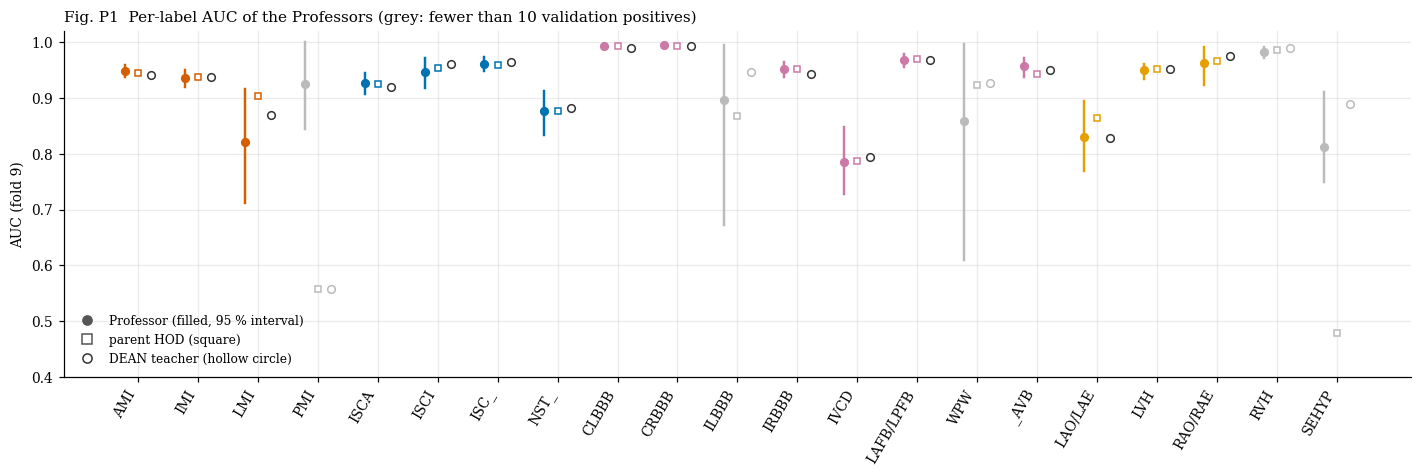

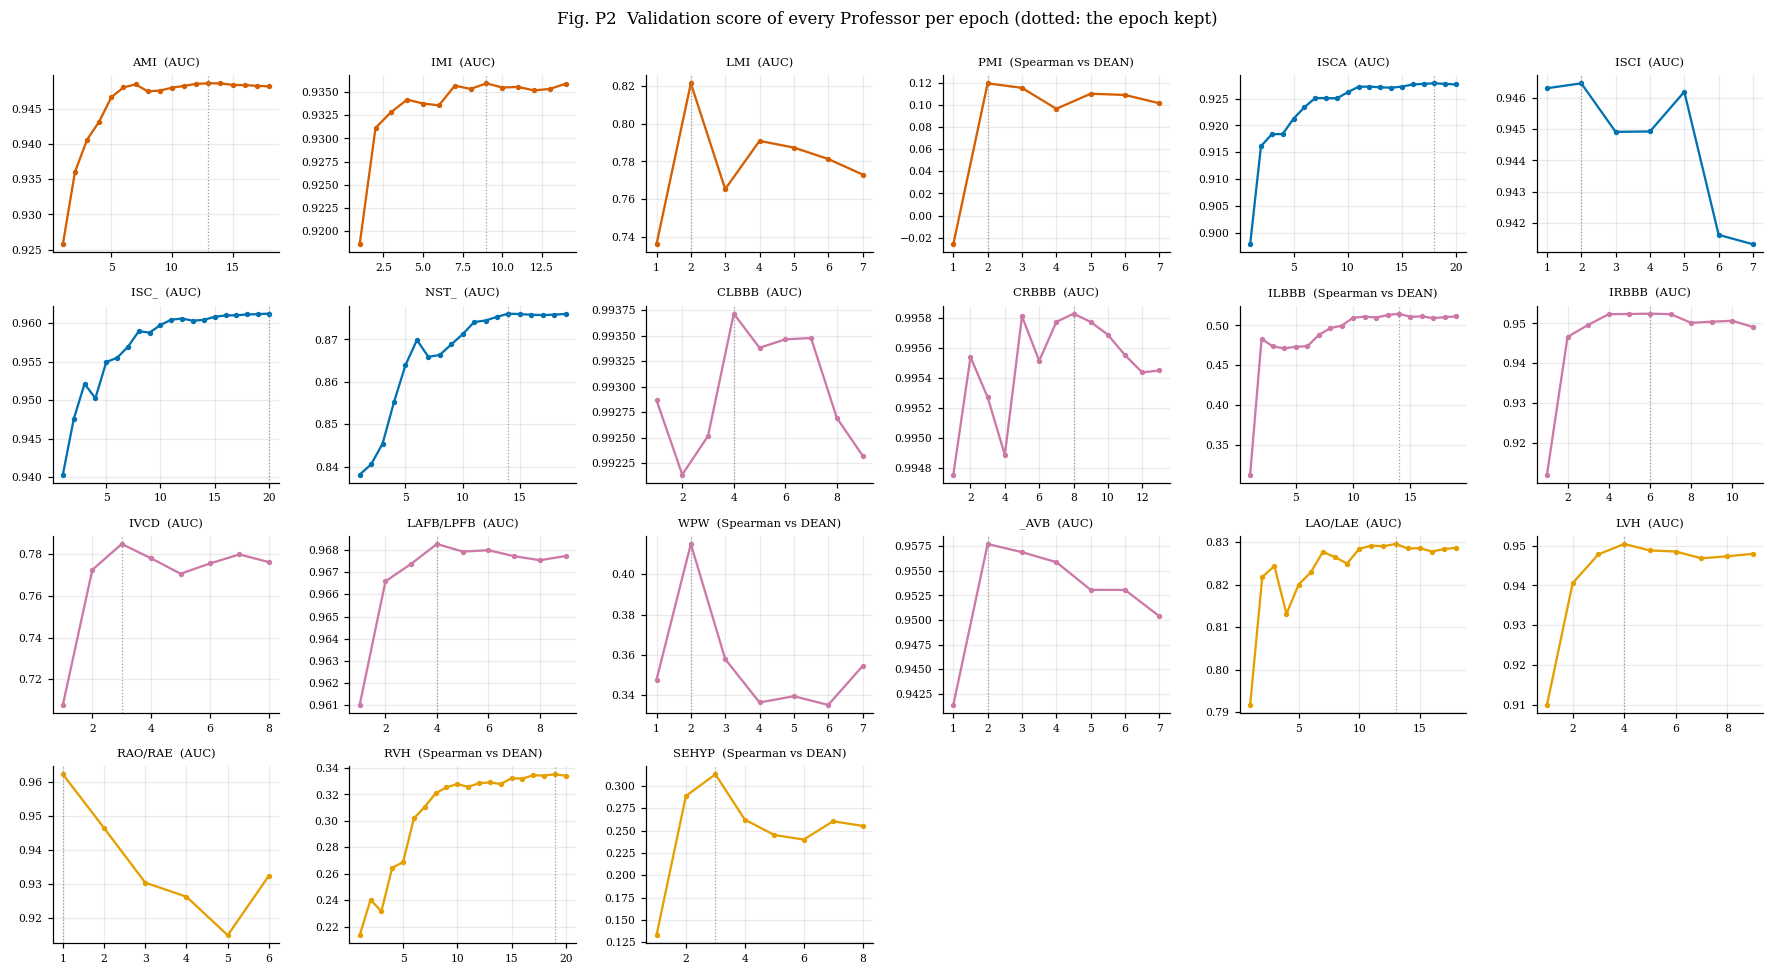

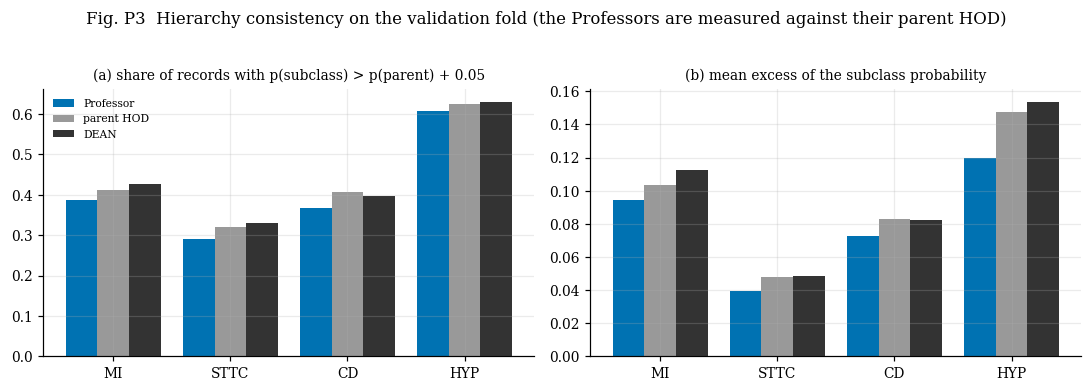

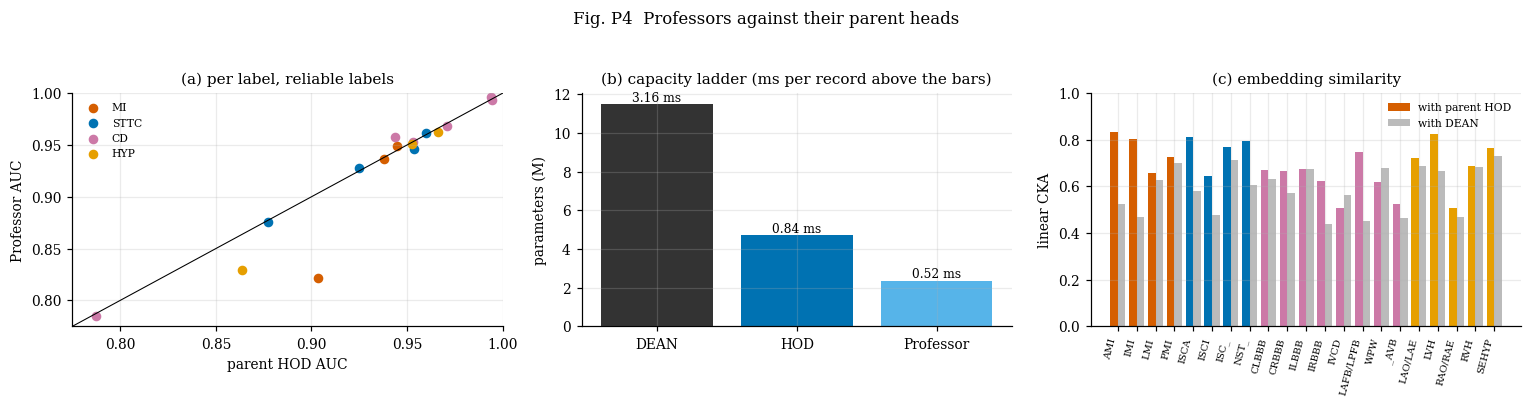

{'DEAN teacher': 3.16, 'HOD (4 blocks)': 0.84, 'Professor (2 blocks)': 0.52}


In [37]:
# Fig. P1  per-label AUC: Professor, parent HOD, DEAN
order6 = [l for s in PCFG['families'] for l in PROF_LABELS if FAMILY[l] == s]
pos6 = {l: k for k, l in enumerate(PROF_LABELS)}
fig, ax = plt.subplots(figsize=(13, 4.4))
for x_, l in enumerate(order6):
    k = pos6[l]
    c = SUPER_COL[FAMILY[l]] if bool(PLP.loc[k, 'reliable']) else '#BBBBBB'
    ax.plot([x_ - 0.22, x_ - 0.22], [PLP.loc[k, 'auc_lo'], PLP.loc[k, 'auc_hi']], color=c, lw=1.6)
    ax.plot(x_ - 0.22, PLP.loc[k, 'auc_prof'], 'o', color=c, ms=5)
    ax.plot(x_, PLP.loc[k, 'auc_hod'], 's', mfc='white', mec=c, ms=4.5)
    ax.plot(x_ + 0.22, PLP.loc[k, 'auc_dean'], 'o', mfc='white', mec=C_TEACHER if bool(PLP.loc[k, 'reliable']) else '#BBBBBB', ms=5)
ax.set_xticks(range(len(order6))); ax.set_xticklabels(order6, rotation=60, ha='right'); ax.set_ylabel('AUC (fold 9)'); ax.set_ylim(0.4, 1.02)
ax.plot([], [], 'o', color='#555', label='Professor (filled, 95 % interval)'); ax.plot([], [], 's', mfc='white', mec='#555', label='parent HOD (square)')
ax.plot([], [], 'o', mfc='white', mec=C_TEACHER, label='DEAN teacher (hollow circle)'); ax.legend(loc='lower left', fontsize=8)
ax.set_title(f'Fig. P1  Per-label AUC of the Professors (grey: fewer than {MP} validation positives)', loc='left')
fig.tight_layout()
save_fig(fig, 'figP1_professor_per_label_auc')

# Fig. P2  training curves of the 21 Professors
ncol = 6
nrow = int(np.ceil(len(PROF_LABELS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.7 * ncol, 2.2 * nrow), squeeze=False)
for ax in axes.ravel():
    ax.set_visible(False)
for k, l in enumerate(PROF_LABELS):
    ax = axes[k // ncol, k % ncol]
    ax.set_visible(True)
    h = pd.DataFrame(PROF[l]['history'])
    ax.plot(h['epoch'], h['val_score'], 'o-', ms=2.5, color=SUPER_COL[FAMILY[l]])
    ax.axvline(PROF[l]['best_epoch'], color='#999', lw=0.8, ls=':')
    ax.set_title(f"{l}  ({'AUC' if PROF[l]['mode'] == 'auc' else 'Spearman vs DEAN'})", fontsize=7.5)
    ax.tick_params(labelsize=7)
fig.suptitle('Fig. P2  Validation score of every Professor per epoch (dotted: the epoch kept)', y=1.0)
fig.tight_layout()
save_fig(fig, 'figP2_professor_training_curves')

# Fig. P3  hierarchy consistency
g = HIER6.groupby('family')[['prof_violation', 'hod_violation', 'dean_violation', 'prof_excess', 'hod_excess', 'dean_excess']].mean().reindex(PCFG['families'])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
xx = np.arange(len(g))
for ax, cols_, ttl in [(axes[0], ['prof_violation', 'hod_violation', 'dean_violation'], '(a) share of records with p(subclass) > p(parent) + 0.05'),
                       (axes[1], ['prof_excess', 'hod_excess', 'dean_excess'], '(b) mean excess of the subclass probability')]:
    for off, cc, col, lab_ in zip((-0.27, 0, 0.27), cols_, ('#0072B2', '#999999', C_TEACHER), ('Professor', 'parent HOD', 'DEAN')):
        ax.bar(xx + off, g[cc], 0.27, color=col, label=lab_)
    ax.set_xticks(xx); ax.set_xticklabels(g.index); ax.set_title(ttl, fontsize=9)
axes[0].legend(fontsize=7)
fig.suptitle('Fig. P3  Hierarchy consistency on the validation fold (the Professors are measured against their parent HOD)', y=1.03)
fig.tight_layout()
save_fig(fig, 'figP3_hierarchy_consistency')

# Fig. P4  Professor against HOD, the capacity ladder and the embedding similarity
CKA6 = []
for l in PROF_LABELS:
    e_h = load_hod(f'hod_{FAMILY[l]}_emb_val.npy')
    CKA6.append(dict(label=l, family=FAMILY[l], cka_parent_hod=hod_lib.linear_cka(PP[l]['em_va'], e_h), cka_dean=hod_lib.linear_cka(PP[l]['em_va'], TE_va)))
CKA6 = pd.DataFrame(CKA6).set_index('label')
CKA6.to_csv(os.path.join(TAB_DIR, 'cka_professor_embeddings.csv'))
xb6 = DATA['X_va'][:64]
l_mid = PROF_LABELS[0]
PROF[l_mid]['net'].eval()
LAT6 = {'DEAN teacher': LAT['DEAN teacher'] if 'LAT' in globals() and 'DEAN teacher' in LAT else float('nan'),
        'HOD (4 blocks)': float(np.mean([v for k_, v in LAT.items() if k_.endswith('head')])) if 'LAT' in globals() else float('nan'),
        'Professor (2 blocks)': ms_per_record(lambda x, m=PROF[l_mid]['net']: m(x), xb6)}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
ok_ = PLP['reliable'].values.astype(bool)
for fam in PCFG['families']:
    m_ = np.array([FAMILY[l] == fam for l in PROF_LABELS]) & ok_
    axes[0].scatter(PLP.loc[m_, 'auc_hod'], PLP.loc[m_, 'auc_prof'], s=28, color=SUPER_COL[fam], label=fam)
lim = [min(PLP.loc[ok_, 'auc_hod'].min(), PLP.loc[ok_, 'auc_prof'].min()) - 0.01, 1.0]
axes[0].plot(lim, lim, color='k', lw=0.7); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel('parent HOD AUC'); axes[0].set_ylabel('Professor AUC'); axes[0].set_title('(a) per label, reliable labels'); axes[0].legend(fontsize=7)
sizes = [T_PARAMS / 1e6, float(np.mean([PARAMS[n] for n in CFG['hods']])) / 1e6, float(np.mean(list(P_PARAMS.values()))) / 1e6]
axes[1].bar(range(3), sizes, color=[C_TEACHER, '#0072B2', '#56B4E9'])
for i_, (s_, t_) in enumerate(zip(sizes, LAT6.values())):
    axes[1].text(i_, s_ + 0.15, f'{t_:.2f} ms' if np.isfinite(t_) else '', ha='center', fontsize=8)
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(['DEAN', 'HOD', 'Professor']); axes[1].set_ylabel('parameters (M)'); axes[1].set_title('(b) capacity ladder (ms per record above the bars)')
axes[2].bar(np.arange(len(CKA6)) - 0.2, CKA6.cka_parent_hod, 0.4, color=[SUPER_COL[f] for f in CKA6.family], label='with parent HOD')
axes[2].bar(np.arange(len(CKA6)) + 0.2, CKA6.cka_dean, 0.4, color='#BBBBBB', label='with DEAN')
axes[2].set_xticks(range(len(CKA6))); axes[2].set_xticklabels(CKA6.index, rotation=75, ha='right', fontsize=6.5); axes[2].set_ylabel('linear CKA'); axes[2].set_ylim(0, 1)
axes[2].set_title('(c) embedding similarity'); axes[2].legend(fontsize=7)
fig.suptitle('Fig. P4  Professors against their parent heads', y=1.04)
fig.tight_layout()
save_fig(fig, 'figP4_professor_vs_hod')
print({k: round(v, 2) for k, v in LAT6.items()})


## 22. Ablation: which part of the Professor recipe matters?
One Professor (`ablation_label`, IMI by default: the largest subclass, so its AUC is the least noisy) is trained for `ablation_epochs` epochs under eight settings. Every run uses the same seed, schedule and data; only the named setting changes, and the full recipe is re-run with the same short schedule so the comparison is like for like.

| Run | What changes |
|---|---|
| full recipe | nothing |
| supervised only | no KD, no Gram-RKD, no contrastive term, no hierarchy term |
| no hierarchy term | `w_hier = 0` |
| no Gram-RKD / no contrastive | one term removed |
| KD from parent HOD only | `kd_alpha = 1` (the plan's literal target) |
| KD from DEAN out-of-fold only | `kd_alpha = 0` |
| uniform sampling | no family-enriched sampling |

Differences are paired bootstrap intervals on the validation fold. Differences of a few thousandths of AUC are inside the noise of one seed on one label and are not effects. The hierarchy column shows what the hierarchy term buys.


In [38]:
ABL6 = None
if PCFG['run_ablation'] and not TIME_UP:
    lab_a = PCFG['ablation_label']
    fam_a, j_a = FAMILY[lab_a], LABELS.index(lab_a)
    VARIANTS6 = {
        'full recipe': {},
        'supervised only (no distillation)': dict(w_kd=0.0, w_rkd=0.0, w_con=0.0, w_hier=0.0),
        'no hierarchy term': dict(w_hier=0.0),
        'no Gram-RKD': dict(w_rkd=0.0),
        'no contrastive': dict(w_con=0.0),
        'KD from parent HOD only': dict(kd_alpha=1.0),
        'KD from DEAN out-of-fold only': dict(kd_alpha=0.0),
        'uniform sampling': dict(sampler='uniform'),
    }
    pdata = make_family_data(fam_a)
    ABL_RUNS6 = {}
    for k, (nm, ov) in enumerate(VARIANTS6.items()):
        if TIME_UP:
            break
        c = prof_cfg(lab_a, epochs=PCFG['ablation_epochs'], warmup_epochs=1, patience=999, **ov)
        r = run_prof_training(f'prof_abl{k}_{prof_lib.safe_name(lab_a)}', lab_a, c, pdata)
        TIME_UP = r['stopped_early']
        if r['finished']:
            ABL_RUNS6[nm] = r
        torch.cuda.empty_cache()
    del pdata
    torch.cuda.empty_cache()
    if 'full recipe' in ABL_RUNS6:
        Yc = Yva[:, [j_a]]
        Z = {nm: predict_net(r['net'], DATA['X_va'])[0] for nm, r in ABL_RUNS6.items()}
        S = {nm: sigmoid(z) for nm, z in Z.items()}
        S_t = sigmoid(TL_va[:, [j_a]])
        p_par_a = sigmoid(HOD_VA[:, LABELS.index(fam_a)])
        rows = []
        for nm in ABL_RUNS6:
            bt = bootstrap(Yc, S[nm], np.full(1, 0.5), MP, NB, n_super=1)
            viol, exc = prof_lib.hier_violation(S[nm][:, 0], p_par_a)
            rows.append({'run': nm, 'AUC': fmt(bt['macro_auc']), 'auc': bt['macro_auc'][0], 'lo': bt['macro_auc'][1], 'hi': bt['macro_auc'][2],
                         'vs full recipe': fmt(paired_delta(Yc, S[nm], S['full recipe'], MP, NB), 4) if nm != 'full recipe' else '-',
                         'vs DEAN': fmt(paired_delta(Yc, S[nm], S_t, MP, NB), 4),
                         'val logit MAE to DEAN': float(np.abs(Z[nm][:, 0] - TL_va[:, j_a]).mean()),
                         'hierarchy violation': viol, 'mean excess': exc, 'best epoch': ABL_RUNS6[nm]['best_epoch']})
        ABL6 = pd.DataFrame(rows).set_index('run')
        print(f'ablation on the {lab_a} Professor, {PCFG["ablation_epochs"]} epochs, DEAN AUC {macro_auc_cols(Yc, S_t, MP):.4f}')
        print(ABL6.drop(columns=['auc', 'lo', 'hi']).round(4).to_string())
        ABL6.drop(columns=['auc', 'lo', 'hi']).to_csv(os.path.join(TAB_DIR, 'table_ablation_professor.csv'))

        fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
        names_a = list(ABL6.index)
        y_ = np.arange(len(names_a))[::-1]
        axes[0].errorbar(ABL6.auc, y_, xerr=[ABL6.auc - ABL6.lo, ABL6.hi - ABL6.auc], fmt='o', color=SUPER_COL[fam_a], capsize=2)
        axes[0].axvline(macro_auc_cols(Yc, S_t, MP), color=C_TEACHER, ls='--', lw=1, label='DEAN')
        axes[0].axvline(ABL6.auc['full recipe'], color=SUPER_COL[fam_a], ls=':', lw=1)
        axes[0].set_yticks(y_); axes[0].set_yticklabels(names_a, fontsize=8); axes[0].set_xlabel(f'validation AUC, {lab_a}'); axes[0].legend(fontsize=7)
        axes[0].set_title('(a) discrimination')
        axes[1].barh(y_, ABL6['val logit MAE to DEAN'], color=SUPER_COL[fam_a]); axes[1].set_yticks(y_); axes[1].set_yticklabels([])
        axes[1].set_xlabel('mean |Professor - DEAN| logit'); axes[1].set_title('(b) closeness to DEAN')
        axes[2].barh(y_, ABL6['hierarchy violation'], color='#555555'); axes[2].set_yticks(y_); axes[2].set_yticklabels([])
        axes[2].set_xlabel('share of records with p(sub) > p(parent) + 0.05'); axes[2].set_title('(c) hierarchy consistency')
        fig.suptitle(f'Fig. P5  Ablation of the Professor recipe on {lab_a} ({PCFG["ablation_epochs"]} epochs)', y=1.04)
        fig.tight_layout()
        save_fig(fig, 'figP5_professor_ablation')
else:
    print('ablation skipped' if not PCFG['run_ablation'] else 'ablation postponed: time budget used up, re-run to continue')


[prof_abl0_IMI] epoch 1/12:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_abl0_IMI] ep  1 | loss 3.3054 (sup 1.493 kd 0.5105 rkd 0.0965 con 3.796 hier 0.1149) | val auc 0.9186 | logit MAE 1.116 |   33s | best


[prof_abl0_IMI] epoch 2/12:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_abl0_IMI] ep  2 | loss 1.9975 (sup 0.739 kd 0.1411 rkd 0.0641 con 3.458 hier 0.0481) | val auc 0.9311 | logit MAE 0.776 |   33s | best


[prof_abl0_IMI] epoch 3/12:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_abl0_IMI] ep  3 | loss 1.7471 (sup 0.577 kd 0.1102 rkd 0.0479 con 3.347 hier 0.0316) | val auc 0.9328 | logit MAE 0.633 |   33s | best


... (22 outputs left out)

[prof_abl1_IMI] epoch 3/12:   0%|          | 0/272 [00:00<?, ?it/s]

[prof_abl1_IMI] ep  3 | loss 0.6254 (sup 0.625 kd 0.0000 rkd 0.0000 con 0.000 hier 0.0000) | val auc 0.9207 | logit MAE 1.141 |   35s


[prof_abl1_IMI] epoch 4/12:   0%|          | 0/272 [00:00<?, ?it/s]

ValueError: Input contains NaN.

## 23. Export
Everything Stage 7 (teacher-output caching) and the Chief Resident need:

* `professors/prof_<label>_final.pt` hold the training state; `professors/prof_<label>_deploy.pt` hold only what inference needs, with the label, its parent, the input normalisation, the Platt parameters and the threshold. `prof_lib.load_professor` rebuilds a Professor from one of them.
* `prof_logits_train.npy` / `prof_logits_val.npy`: the 21 subclass logits per record, columns in the teacher's subclass order (`LABELS[5:]`, listed in `prof_config.json`). The training logits are **in-sample for the Professors**; `table_generalisation_gap_professors.csv` measures how much that matters.
* `prof_emb_train_fp16.npy` / `prof_emb_val_fp16.npy`: the pooled 256-d embedding of every Professor, shape (records, 21, 256). These are the keys and values of the Chief Resident's consultation module.
* `prof_calibration.json`: Platt parameters and F1 thresholds per subclass (fold 9).
* `prof_metrics.json`, `prof_best_per_label.json`, `tables/*.csv`, `figures/*`.


In [ ]:
cal6 = EVP_H
for k, l in enumerate(PROF_LABELS):
    r = PROF[l]
    torch.save({'deploy': r['net'].deploy_state(), 'label': l, 'parent': FAMILY[l], 'col': LABELS.index(l), 'd_anchor': HOD_D,
                'student_enc_cfg': dict(ENC_CFG, depth=r['cfg']['depth'], grad_ckpt=False), 'head_drop': r['cfg']['head_drop'],
                'norm_mean': MU.tolist(), 'norm_std': SD.tolist(),
                'platt_a': float(cal6['a'][k]), 'platt_b': float(cal6['b'][k]), 'threshold': float(cal6['thr'][k]),
                'best_epoch': int(r['best_epoch']), 'val_score': float(r['best_score']), 'score_mode': r['mode'],
                'teacher_source': 'dean_finetuned.pt + departmental heads (Stage 5)',
                'config': {kk: r['cfg'][kk] for kk in PSIG_KEYS}}, os.path.join(PROF_DIR, f'prof_{prof_lib.safe_name(l)}_deploy.pt'))
    pd.DataFrame(r['history']).to_csv(os.path.join(TAB_DIR, f'history_prof_{prof_lib.safe_name(l)}.csv'), index=False)
np.save(os.path.join(WORK, 'prof_logits_train.npy'), PROF_tr.astype(np.float32))
np.save(os.path.join(WORK, 'prof_logits_val.npy'), PROF_va.astype(np.float32))
np.save(os.path.join(WORK, 'prof_emb_train_fp16.npy'), PROF_EMB_tr.astype(np.float16))
np.save(os.path.join(WORK, 'prof_emb_val_fp16.npy'), PROF_EMB_va.astype(np.float16))

json.dump({'labels': PROF_LABELS, 'parents': [FAMILY[l] for l in PROF_LABELS], 'platt_a': [float(v) for v in cal6['a']], 'platt_b': [float(v) for v in cal6['b']],
           'thresholds': [float(v) for v in cal6['thr']], 'note': 'fitted on fold 9. Thresholds are optimistic for F1; NB-09 reports fold 10.'},
          open(os.path.join(WORK, 'prof_calibration.json'), 'w'), indent=1)
json.dump({l: dict(parent=FAMILY[l], lr=PROF[l]['cfg']['lr'], best_epoch=int(PROF[l]['best_epoch']), epochs_run=len(PROF[l]['history']),
                   score_mode=PROF[l]['mode'], val_score=float(PROF[l]['best_score'])) for l in PROF_LABELS},
          open(os.path.join(WORK, 'prof_best_per_label.json'), 'w'), indent=1)
metrics6 = {
    'note': 'validation fold (fold 9) only; fold 10 is untouched. Calibration and thresholds were fitted on this fold.',
    'learning_rate_per_family': PLR, 'kd_alpha': PCFG['kd_alpha'], 'professor_params_M': {k: v / 1e6 for k, v in P_PARAMS.items()},
    'teacher_params_M': T_PARAMS / 1e6, 'professors_vs_hod_vs_dean': TAB_PROF.to_dict(orient='index'),
    'per_label': PLP.round(4).to_dict(orient='records'), 'family_professor_vs_hod': FAMCMP6.to_dict(orient='index'),
    'hierarchy_consistency': HIER6.round(4).to_dict(orient='index'), 'generalisation_gap': GAP6.round(4).to_dict(orient='index'),
    'cka_embeddings': CKA6.round(4).to_dict(orient='index'), 'latency_ms_per_record': LAT6,
    'ablation': ABL6.drop(columns=['auc', 'lo', 'hi']).to_dict(orient='index') if ABL6 is not None else None,
    'time_budget_hit': bool(TIME_UP),
}
json.dump(metrics6, open(os.path.join(WORK, 'prof_metrics.json'), 'w'), indent=1, default=float)
json.dump({'PCFG': PCFG, 'ENC_CFG': ENC_CFG, 'versions': VERSIONS, 'labels': LABELS, 'subclass_columns': PROF_LABELS, 'train_folds': list(range(1, 9)), 'val_fold': 9,
           'hod_inputs': ['hod_logits_train.npy', 'hod_logits_val.npy', 'hod_<n>_emb_train.npy', 'hod_<n>_tokens_train_fp16.npy'],
           'smoke': SMOKE6}, open(os.path.join(WORK, 'prof_config.json'), 'w'), indent=1, default=str)

# reload check: a deploy file rebuilt from scratch reproduces the trained Professor (fp32, identical batches)
l0 = PROF_LABELS[0]
net2, ck = prof_lib.load_professor(os.path.join(PROF_DIR, f'prof_{prof_lib.safe_name(l0)}_deploy.pt'), dev)

@torch.no_grad()
def logits_fp32(net, X, bs=64):
    net.eval()
    return torch.cat([net(X[i:i + bs]).float().cpu() for i in range(0, len(X), bs)]).numpy()

xr = DATA['X_va'][:128]
d32 = float(np.abs(logits_fp32(net2, xr) - logits_fp32(PROF[l0]['net'], xr)).max())
d16 = float(np.abs(predict_net(net2, DATA['X_va'][:256])[0] - PP[l0]['lg_va'][:256]).max())
print(f'{l0}: max |deploy - trained| logit difference: fp32 {d32:.2e}, fp16 (batch 256 against the stored predictions) {d16:.3f}')
assert d32 < 5e-3, 'the deploy file does not reproduce the trained Professor'
assert d16 < 0.25, 'the deploy file does not reproduce the stored predictions'
print(f'reload check passed for the {l0} Professor')

shutil.rmtree(os.path.join(WORK, 'smoke_tmp6'), ignore_errors=True)
print(f'total notebook time {(time.time() - NB_T0) / 3600:.2f} h')
print('files in /kaggle/working:')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '__pycache__' in p or p.endswith('.tmp') or p.endswith('_last.pt'):
            continue
        print(f'  {os.path.relpath(p, WORK):55s} {os.path.getsize(p) / 1e6:8.2f} MB')


## 24. After this notebook
1. Save a version (Save & Run All) and publish the output as the Dataset **`professors-v1`**. The important files are `professors/prof_<label>_final.pt` and `_deploy.pt`, `prof_lib.py`, `prof_logits_{train,val}.npy`, `prof_emb_{train,val}_fp16.npy`, `prof_calibration.json`, `prof_metrics.json` and `prof_best_per_label.json`. Keep the Stage-5 files (`hods/`, `hod_*.npy`, `hod_lib.py`, `hod_lr_search.json`) in the Dataset as well, so that a later session reloads instead of retraining. The `professors/*_last.pt` files are only needed if a run paused.
2. **Read four things before moving on:** `table_main_professors.csv` (are the Professors within the noise of their parent HODs and of DEAN?), `table_per_label_professors.csv` (the rare subclasses are listed but not averaged), `table_hierarchy_consistency.csv` (did the hierarchy term reduce the violations?) and `table_ablation_professor.csv` (does the plan's HOD-only target or the HOD + DEAN mix do better, and which loss terms earn their place?). Whatever those say is a result, including a negative one.
3. The Professors' training logits are in-sample for them (`table_generalisation_gap_professors.csv` measures the gap). Stage 7 should cache them as they are, but Stage 8 should know that the targets on the training records are sharper than on new data, as NB-02's out-of-fold analysis showed for DEAN.
4. Next: Stage 7 (teacher-output caching) needs only `prof_logits_*.npy` and `prof_emb_*_fp16.npy` from here, the gating distributions from Stage 4 and DEAN's token sequences from Stage 3. Stage 9 (prototype index) needs only the cached DEAN embeddings and can be run at any time.

Everything in the notebook that was fixed in advance (the target mix `kd_alpha`, the learning-rate rule, the 0.05 hierarchy tolerance, the minimum of 10 positives, the augmentation rule) is written next to the code that uses it, so the report can state it as a pre-specified protocol.
